In [ ]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#display
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)
# This suppresses scientific notation globally for the session
pd.options.display.float_format = '{:.2f}'.format
import warnings
warnings.filterwarnings('ignore')

##**Data Pre-Processing**

In [ ]:
#reading the dataset
df=pd.read_csv('/content/master_file_final_new_final_03.csv')
df.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE
0,22300_1_1,34,2,2,57436,4,56,1,2,12,1,1,0.02,3,2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25
1,22300_2_1,34,2,2,27497,4,48,1,2,5,1,1,0.01,3,2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50
2,22300_2_2,34,2,2,27497,2,63,1,2,12,1,9,0.01,3,2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00
3,22300_2_3,34,2,2,27497,2,68,1,2,5,2,9,0.03,3,2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00
4,22300_2_4,34,2,2,27497,2,53,1,2,13,1,2,0.02,3,2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50


In [ ]:
#shape
df.shape

(261953, 28)

In [ ]:
#print for unique state number
print(df.State.unique())

[34 33 37 36 35 19 18 15 14 17 16 13 12 32 31 29 28 30 23 24 20 22 21  8
  7  3  6  5  4  1  2 10 11  9 27 25]


In [ ]:
#region mapping based on states
# Define Region Mapping
region_mapping = {
    'North': [1, 2, 3, 4, 5, 6, 7, 8, 37],
    'Central': [9, 22, 23],
    'East': [10, 19, 20, 21],
    'North East': [11, 12, 13, 14, 15, 16, 17, 18],
    'West': [24, 25, 26, 27, 30],
    'South': [28, 29, 31, 32, 33, 34, 35, 36]
}

# Create a mapping for easy application to the DataFrame
state_to_region = {state: region for region, states in region_mapping.items() for state in states}
df['Region'] = df['State'].map(state_to_region)


In [ ]:
#read data
df.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,34,2,2,57436,4,56,1,2,12,1,1,0.02,3,2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,34,2,2,27497,4,48,1,2,5,1,1,0.01,3,2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,34,2,2,27497,2,63,1,2,12,1,9,0.01,3,2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,34,2,2,27497,2,68,1,2,5,2,9,0.03,3,2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,34,2,2,27497,2,53,1,2,13,1,2,0.02,3,2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
#checking for null
df.isnull().sum()

,0
HHID,0
State,0
Sector,0
District,0
Multiplier,0
hh_size,0
head_age,0
head_gender,0
head_marital_status,0
head_education_level,0


In [ ]:
df.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,34,2,2,57436,4,56,1,2,12,1,1,0.02,3,2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,34,2,2,27497,4,48,1,2,5,1,1,0.01,3,2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,34,2,2,27497,2,63,1,2,12,1,9,0.01,3,2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,34,2,2,27497,2,68,1,2,5,2,9,0.03,3,2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,34,2,2,27497,2,53,1,2,13,1,2,0.02,3,2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
#mapping state and sector
df2 = df.copy()
sector_map = {1:'rural',2:'urban'}
state_map = {
    1: "Jammu & Kashmir", 2: "Himachal Pradesh", 3: "Punjab", 4: "Chandigarh",
    5: "Uttarakhand", 6: "Haryana", 7: "Delhi", 8: "Rajasthan", 9: "Uttar Pradesh",
    10: "Bihar", 11: "Sikkim", 12: "Arunachal Pradesh", 13: "Nagaland", 14: "Manipur",
    15: "Mizoram", 16: "Tripura", 17: "Meghalaya", 18: "Assam", 19: "West Bengal",
    20: "Jharkhand", 21: "Odisha", 22: "Chhattisgarh", 23: "Madhya Pradesh",
    24: "Gujarat", 25: "Daman & Diu", 26: "Dadra & Nagar Haveli", 27: "Maharashtra",
    28: "Andhra Pradesh", 29: "Karnataka", 30: "Goa", 31: "Lakshadweep",
    32: "Kerala", 33: "Tamil Nadu", 34: "Puducherry", 35: "Andaman & Nicobar",
    36: "Telangana",37:"Ladakh"}
df2['Sector'] = df2['Sector'].map(sector_map)
df2['State'] = df2['State'].map(state_map)
df2.head()


,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,Puducherry,urban,2,57436,4,56,1,2,12,1,1,0.02,3,2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,Puducherry,urban,2,27497,4,48,1,2,5,1,1,0.01,3,2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,Puducherry,urban,2,27497,2,63,1,2,12,1,9,0.01,3,2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,Puducherry,urban,2,27497,2,68,1,2,5,2,9,0.03,3,2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,Puducherry,urban,2,27497,2,53,1,2,13,1,2,0.02,3,2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
#mapping gender
gender_map = {1:'male',2:'female',3:'LGBTQ+'}
df2['head_gender'] = df2['head_gender'].map(gender_map)
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,2,12,1,1,0.02,3,2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,2,5,1,1,0.01,3,2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,2,12,1,9,0.01,3,2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,2,5,2,9,0.03,3,2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,2,13,1,2,0.02,3,2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
#mapping marital status
marital_map = {1:'Single',2:'married',3:'Widowed',4:'Divorced/Seperated'}
df2['head_marital_status'] = df2['head_marital_status'].map(marital_map)

In [ ]:
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,12,1,1,0.02,3,2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,5,1,1,0.01,3,2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,12,1,9,0.01,3,2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,5,2,9,0.03,3,2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,13,1,2,0.02,3,2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
#mapping education level
edu_map={
    1: "Not Literate", 2: "Literate (No Schooling)", 3: "Literate (Non-Formal)",
    4: "Below Primary", 5: "Primary", 6: "Middle", 7: "Secondary",
    8: "Higher Secondary", 10: "Diploma", 11: "Graduate", 12: "Post Graduate+",13: "Post Graduate & Above"
}
df2['head_education_level'] = df2['head_education_level'].map(edu_map)
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,1,0.02,3,2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,1,0.01,3,2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,9,0.01,3,2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,9,0.03,3,2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,2,0.02,3,2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
df2.Sector.value_counts()

,count
Sector,
rural,154357
urban,107596


In [ ]:
##household type
def map_hh_type(row):
    # Rural Mapping
    if row['Sector'] == 'rural':
        rural_map = {
            1: "Rural: Self-Emp (Agri)",
            2: "Rural: Self-Emp (Non-Agri)",
            3: "Rural: Regular Salary",
            4: "Rural: Casual Labour (Agri)",
            5: "Rural: Casual Labour (Non-Agri)",
            6: "Rural: Others",
            9: "Rural: Others"
        }
        return rural_map.get(row['Household_Type'], "Unknown")

    # Urban Mapping
    else:
        urban_map = {
            1: "Urban: Self-Employed",
            2: "Urban: Regular Salary",
            3: "Urban: Casual Labour",
            9: "Urban: Others"
        }
        return urban_map.get(row['Household_Type'], "Unknown")

# Apply the mapping row by row
df2['Household_Type'] = df2.apply(map_hh_type, axis=1)

In [ ]:
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,0.02,3,2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,0.01,3,2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,0.01,3,2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,0.03,3,2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,0.02,3,2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
#mapping the ration card type
#mapping for ration card type
# Detailed Mapping
ration_map = {
    1: "Antyodaya (AAY)",
    2: "Priority (BPL)",
    3: "Non-Priority (APL)",
    4: "Others",
    5: "No Ration Card",
    0: "No Card/Not Recorded",
    9: "Not Recorded"
}

df2['Ration_Card_Type'] = df2['Ration_Card_Type'].map(ration_map)
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,0.02,Non-Priority (APL),2,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,0.01,Non-Priority (APL),2,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,0.01,Non-Priority (APL),2,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,0.03,Non-Priority (APL),2,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,0.02,Non-Priority (APL),2,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
#mapping for cooking fuel type
fuel_map = {
    1: "LPG", 2: "Firewood/Chips", 3: "Coke/Coal", 4: "Gobar Gas",
    5: "Dung Cake", 6: "Charcoal", 7: "Kerosene", 8: "Electricity",
    9: "Solar", 10: "Wind", 11: "Others", 12: "No Cooking arrangement"
}

# Apply to the dataframe
df2['Energy_Source_Cooking'] = df2['Energy_Source_Cooking'].map(fuel_map)
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Total_Area_Land_Owned_Acres,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,0.02,Non-Priority (APL),Firewood/Chips,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,0.01,Non-Priority (APL),Firewood/Chips,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,0.01,Non-Priority (APL),Firewood/Chips,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,0.03,Non-Priority (APL),Firewood/Chips,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,0.02,Non-Priority (APL),Firewood/Chips,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South


In [ ]:
#checking for null values
df2.isnull().sum()

,0
HHID,0
State,0
Sector,0
District,0
Multiplier,0
hh_size,0
head_age,0
head_gender,0
head_marital_status,0
head_education_level,0


In [ ]:
#printing info
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261953 entries, 0 to 261952
Data columns (total 29 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   HHID                          261953 non-null  object 
 1   State                         261953 non-null  object 
 2   Sector                        261953 non-null  object 
 3   District                      261953 non-null  int64  
 4   Multiplier                    261953 non-null  int64  
 5   hh_size                       261953 non-null  int64  
 6   head_age                      261953 non-null  int64  
 7   head_gender                   261953 non-null  object 
 8   head_marital_status           261953 non-null  object 
 9   head_education_level          261953 non-null  object 
 10  is_digital_hh                 261953 non-null  int64  
 11  Household_Type                261953 non-null  object 
 12  Total_Area_Land_Owned_Acres   261953 non-nul

In [ ]:
#converting dtypes
df2['District'] = df2['District'].astype('str')


In [ ]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261953 entries, 0 to 261952
Data columns (total 29 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   HHID                          261953 non-null  object 
 1   State                         261953 non-null  object 
 2   Sector                        261953 non-null  object 
 3   District                      261953 non-null  object 
 4   Multiplier                    261953 non-null  int64  
 5   hh_size                       261953 non-null  int64  
 6   head_age                      261953 non-null  int64  
 7   head_gender                   261953 non-null  object 
 8   head_marital_status           261953 non-null  object 
 9   head_education_level          261953 non-null  object 
 10  is_digital_hh                 261953 non-null  int64  
 11  Household_Type                261953 non-null  object 
 12  Total_Area_Land_Owned_Acres   261953 non-nul

In [ ]:
#exporting the csv file
df2.to_csv('master_file_final_cleaned_new.csv',index=False)

In [ ]:
#converting land area into square feet for better understanding
df2['land_area_sqft'] = df2['Total_Area_Land_Owned_Acres'] * 43560

In [ ]:
#dropping our total land in acres
df2.drop('Total_Area_Land_Owned_Acres',axis=1,inplace=True)

In [ ]:
#reading the data
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South,871.20
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South,435.60
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South,435.60
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South,1306.80
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South,871.20


In [ ]:
def get_remaining_years(age, gender):
  if age > 100:
        return 3.0
    # Standard SRS Life Table Mapping for India
  if gender == "Male":  # Male
        if age < 25: return 50.4
        elif age < 35: return 41.5
        elif age < 45: return 32.8
        elif age < 55: return 24.5
        elif age < 65: return 17.2
        else: return 8.0
  else:  # Female / Other
    if age < 25: return 54.2
    elif age < 35: return 45.1
    elif age < 45: return 36.3
    elif age < 55: return 27.7
    elif age < 65: return 19.8
    else: return 10.3

# Apply this to your Master Dataframe
df2['expected_remaining_years'] = df2.apply(
    lambda x: get_remaining_years(x['head_age'], x['head_gender']), axis=1
)


In [ ]:
#checking with the descriptive statistics
df2.describe().T

,count,mean,std,min,25%,50%,75%,max
Multiplier,261953.00,111344.81,79656.11,369.00,56738.00,114044.00,150441.00,2366902.00
hh_size,261953.00,4.23,2.07,1.00,3.00,4.00,5.00,31.00
head_age,261953.00,48.83,14.27,4.00,38.00,48.00,60.00,120.00
is_digital_hh,261953.00,1.43,0.49,1.00,1.00,1.00,2.00,2.00
food_spend,261953.00,40118.63,80012.86,0.00,5476.00,14480.00,45773.00,4646418.00
intoxicant_spend,261953.00,6922.67,8077.64,0.00,2000.00,4735.00,9092.00,312668.00
online_score,261953.00,0.44,0.83,0.00,0.00,0.00,1.00,7.00
asset_score,261953.00,2.56,1.37,0.00,1.00,2.00,3.00,6.00
welfare_benefit_count,261953.00,0.01,0.09,0.00,0.00,0.00,0.00,3.00
total_basket_value,261953.00,35434.83,23821.12,0.00,19760.00,30700.00,45130.00,502200.00


**Inferences**

- The average Household age indicates most of the hosueholds are young households ageing around 48 years, which indicates long and higher customer lifetime value

- The Average household digitally empowered indicates that atleast 2 houses in a area are having internet connection.

- Most of the consumers highest expenditures are towards food since being daily consumables and lowest on intoxicants.

- The target mpce indicates that the monthly  consumption of an average indian family is atleast 23,422 rupees.

- We also observe the online items purchased score is just 0.44 which indicates most of the indian customers prefer offline shopping.

 - We also observe that the total basket value in the indian households minimum affordability is worth 35434 rupees with 18 unique items.

 - The expected remaining for households is around 28 years which indicates most of households are young and and long life expectancy.

 - We also observed that most of the households atleast own an average of 38465 square feet of land indicating high value customers.



- **Estimated CLV = (Predicted MPCEx 12)x Expected Remaining Years**

- **Expected remaining Years = Based on Life expectancy Table From SRS Life table Mapping**

In [ ]:
#checking for null values
df2.isnull().sum()

,0
HHID,0
State,0
Sector,0
District,0
Multiplier,0
hh_size,0
head_age,0
head_gender,0
head_marital_status,0
head_education_level,0


#**Exploratory Data Analysis**


In [ ]:
#read data
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South,871.20,19.80
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South,435.60,27.70
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South,435.60,19.80
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South,1306.80,10.30
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South,871.20,27.70


In [ ]:
# #export to csv as cleaned_2
#df2.to_csv('master_data_cleaned_final.csv',index=False)

**Outlier Analysis**

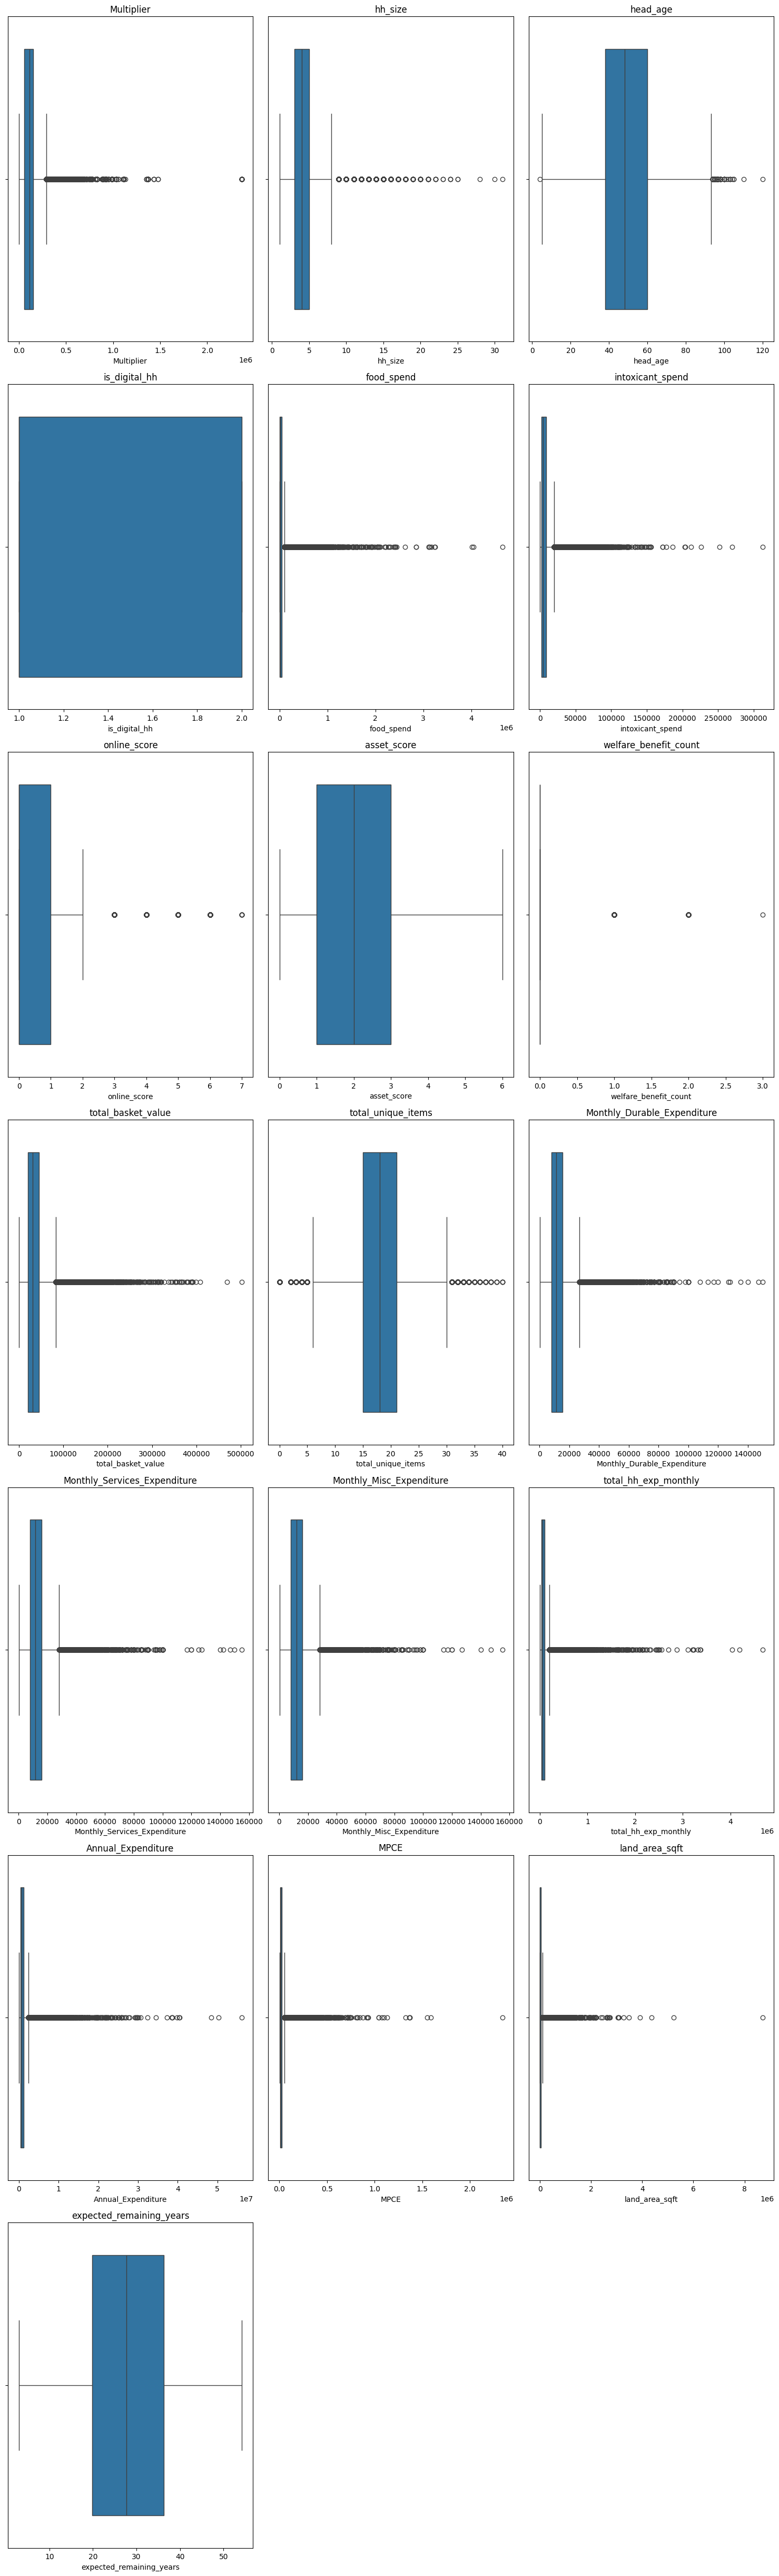

In [ ]:
#creating subplots for outlier analysis for all numeric columns
import math

numeric_cols = df2.select_dtypes(include=['int64', 'float64']).columns
num_plots = len(numeric_cols)

# Determine the number of rows and columns for the subplot grid
ncols = 3  # You can adjust this number of columns
nrows = math.ceil(num_plots / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15,7 * nrows)) # Adjust figsize dynamically

# Flatten the axes array to easily iterate over it
# Handles cases where nrows or ncols might be 1 (axes would be a 1D array or single Axes object)
if num_plots == 1:
    axes = [axes] # Make it a list if only one subplot
else:
    axes = axes.flatten()

# Iterate through the numeric columns and create a boxplot for each
for i, col in enumerate(numeric_cols):
    sns.boxplot(x=df2[col], ax=axes[i])
    axes[i].set_title(col)

# Hide any unused subplots if num_plots is not a perfect multiple of ncols
for j in range(num_plots, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Inferences**

- After observing outliers for all numeric columns the distance between outliers is minimalistic for all expenditures hence no treating of outliers.

- In the Age column we observe the maximum age as 120 and minimum at 4 which has no semantic meaning hence we treat the outliers.



In [ ]:
#read data
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South,871.20,19.80
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South,435.60,27.70
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South,435.60,19.80
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South,1306.80,10.30
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,54574.50,South,871.20,27.70


In [ ]:
#treating the outliers
def handle_outliers_iqr(df, column):
    # 1. Calculate Q1, Q3, and IQR
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    # 2. Define Bounds
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    # 3. For Age specifically: ensure lower bound isn't below 18
    if column == 'head_age':
        lower_fence = max(lower_fence, 18)

    # 4. Perform Clipping (Winsorization)
    # This overwrites the extreme values with the fence values
    cleaned_series = df[column].clip(lower=lower_fence, upper=upper_fence)

    print(f"Treated {column}: Lower Fence: {lower_fence:.2f} | Upper Fence: {upper_fence:.2f}")
    return cleaned_series

# --- Apply and Overwrite Original Columns ---
df2['head_age'] = handle_outliers_iqr(df2, 'head_age')
df2['MPCE'] = handle_outliers_iqr(df2, 'MPCE')

# Quick check: The 120 and single-digits are now gone
print(f"\nMax Age after treatment: {df2['head_age'].max()}")
print(f"Min Age after treatment: {df2['head_age'].min()}")


Treated head_age: Lower Fence: 18.00 | Upper Fence: 93.00
Treated MPCE: Lower Fence: -14602.38 | Upper Fence: 51155.43

Max Age after treatment: 93
Min Age after treatment: 18


<Axes: xlabel='head_age'>

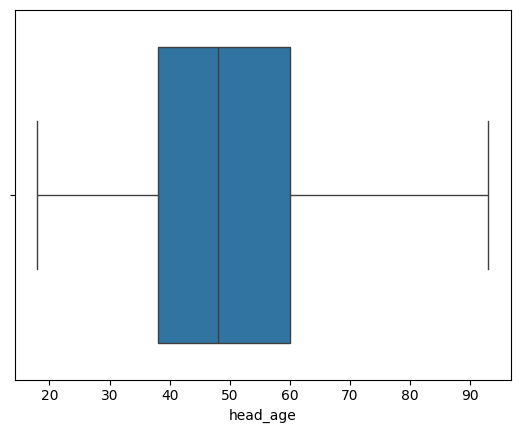

In [ ]:
#checking with box plot for the head age
sns.boxplot(x=df2['head_age'])

In [ ]:
#checking with the statistsics after treating outliers
df2.describe().T

,count,mean,std,min,25%,50%,75%,max
Multiplier,261953.00,111344.81,79656.11,369.00,56738.00,114044.00,150441.00,2366902.00
hh_size,261953.00,4.23,2.07,1.00,3.00,4.00,5.00,31.00
head_age,261953.00,48.86,14.19,18.00,38.00,48.00,60.00,93.00
is_digital_hh,261953.00,1.43,0.49,1.00,1.00,1.00,2.00,2.00
food_spend,261953.00,40118.63,80012.86,0.00,5476.00,14480.00,45773.00,4646418.00
intoxicant_spend,261953.00,6922.67,8077.64,0.00,2000.00,4735.00,9092.00,312668.00
online_score,261953.00,0.44,0.83,0.00,0.00,0.00,1.00,7.00
asset_score,261953.00,2.56,1.37,0.00,1.00,2.00,3.00,6.00
welfare_benefit_count,261953.00,0.01,0.09,0.00,0.00,0.00,0.00,3.00
total_basket_value,261953.00,35434.83,23821.12,0.00,19760.00,30700.00,45130.00,502200.00


In [ ]:
#read data
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923,21690,3,5,0,31570,20,40000,39000,40000,154613,1855356,38653.25,South,871.20,19.80
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894,29700,2,5,0,63520,18,28000,32000,35000,135594,1627128,33898.50,South,435.60,27.70
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South,435.60,19.80
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South,1306.80,10.30
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929,23720,1,5,0,65980,19,25000,24500,24000,109149,1309788,51155.43,South,871.20,27.70


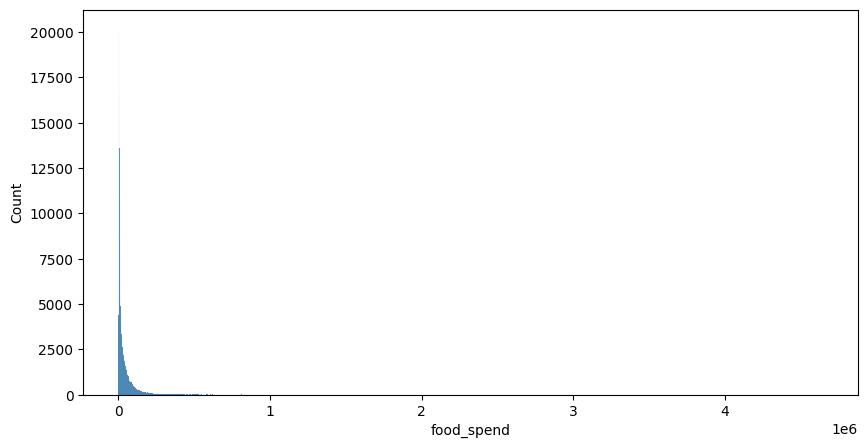

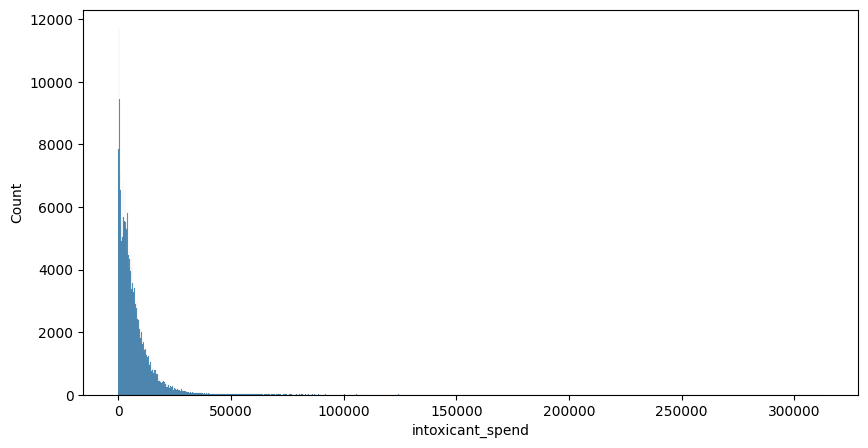

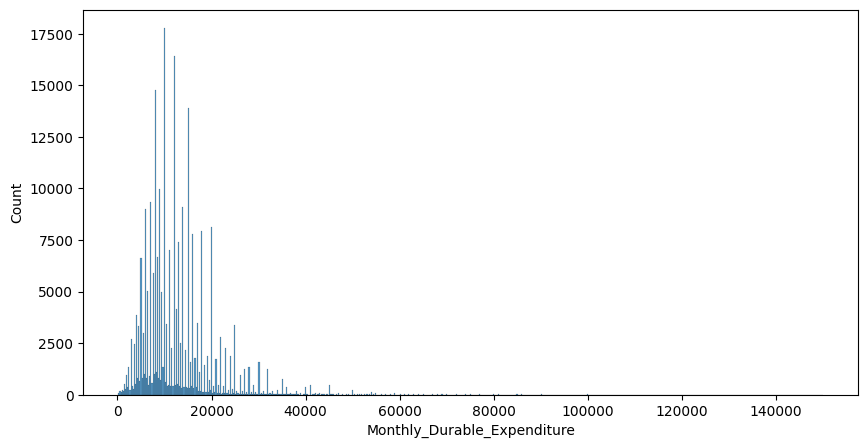

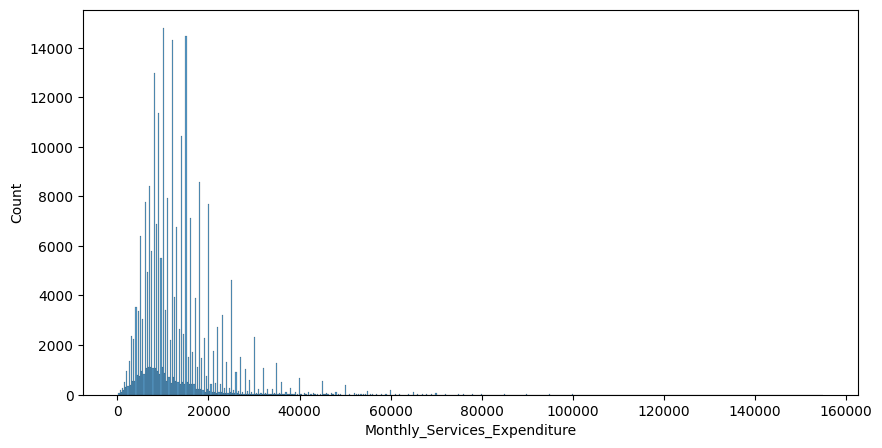

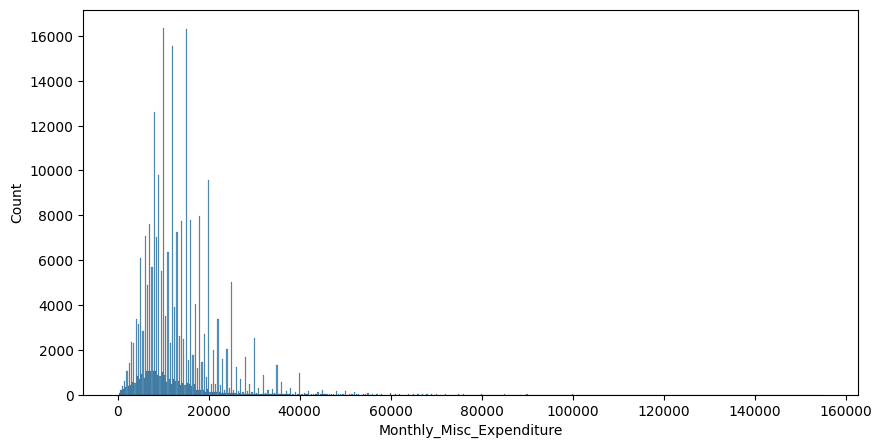

In [ ]:
#checking the distribution using histplot for expenditures on food,intocicant,durables,services and misc
for i in ['food_spend','intoxicant_spend','Monthly_Durable_Expenditure','Monthly_Services_Expenditure','Monthly_Misc_Expenditure']:
  plt.figure(figsize=(10,5))
  sns.histplot(df2[i])
  plt.show()





**Inferences**

- Since we observe that most of the expenditures are left skewed and biased towards households which could affect our modeling accuracy hence we treat outliers for each

In [ ]:
#treating outliers for all expenditure columns
df2['food_spend'] = handle_outliers_iqr(df2, 'food_spend')
df2['intoxicant_spend'] = handle_outliers_iqr(df2, 'intoxicant_spend')
df2['Monthly_Durable_Expenditure'] = handle_outliers_iqr(df2, 'Monthly_Durable_Expenditure')
df2['Monthly_Services_Expenditure'] = handle_outliers_iqr(df2, 'Monthly_Services_Expenditure')
df2['Monthly_Misc_Expenditure'] = handle_outliers_iqr(df2, 'Monthly_Misc_Expenditure')


Treated food_spend: Lower Fence: -54969.50 | Upper Fence: 106218.50
Treated intoxicant_spend: Lower Fence: -8638.00 | Upper Fence: 19730.00
Treated Monthly_Durable_Expenditure: Lower Fence: -3250.00 | Upper Fence: 26750.00
Treated Monthly_Services_Expenditure: Lower Fence: -4000.00 | Upper Fence: 28000.00
Treated Monthly_Misc_Expenditure: Lower Fence: -4000.00 | Upper Fence: 28000.00


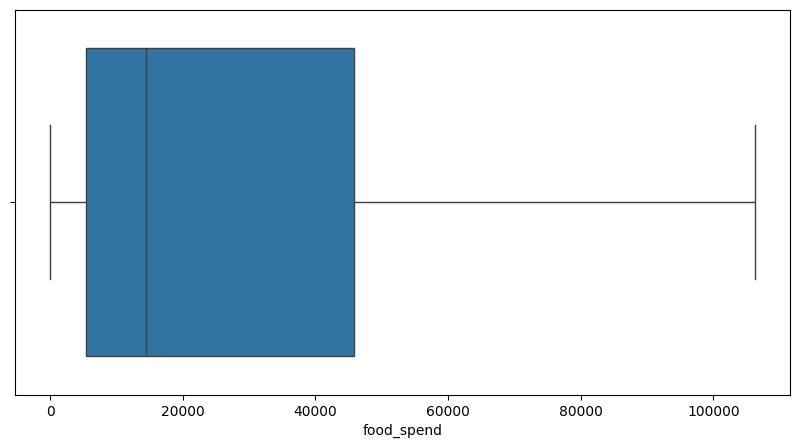

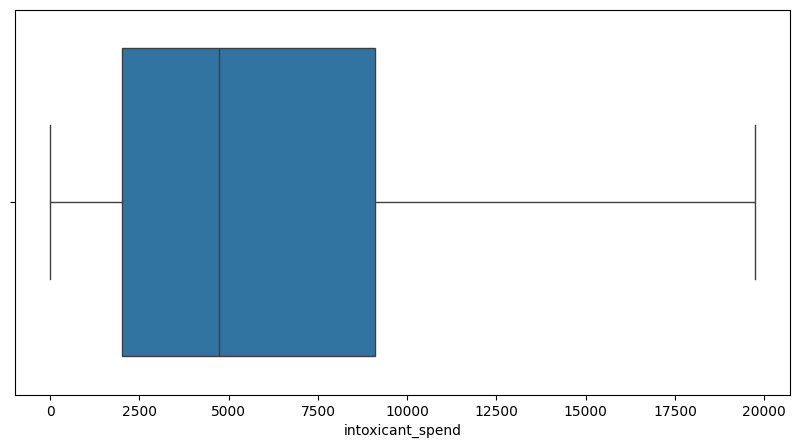

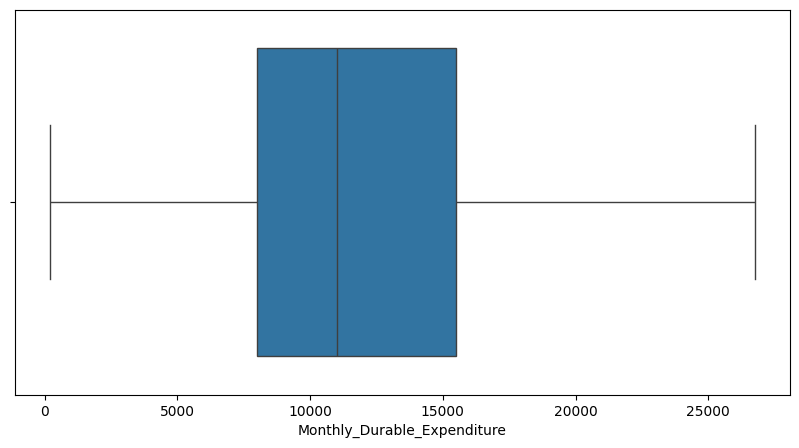

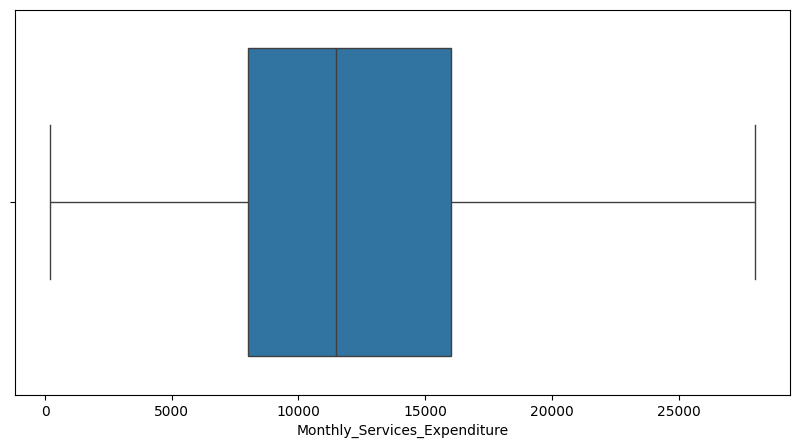

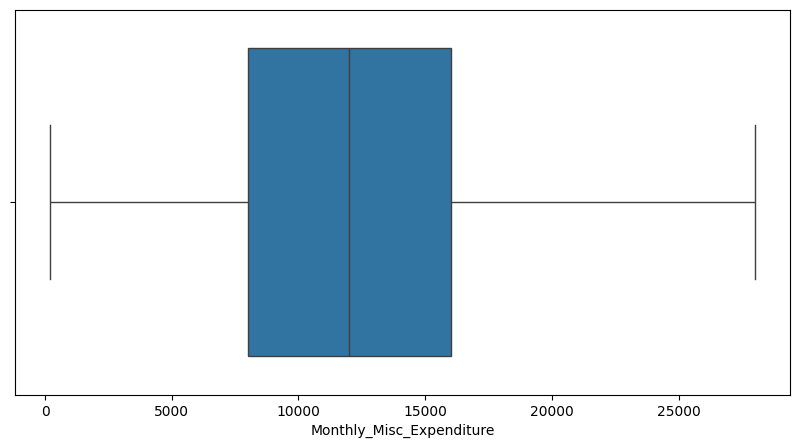

In [ ]:
#plotting box plot for all expenditures
for i in ['food_spend','intoxicant_spend','Monthly_Durable_Expenditure','Monthly_Services_Expenditure','Monthly_Misc_Expenditure']:
  plt.figure(figsize=(10,5))
  sns.boxplot(x=df2[i])
  plt.show()

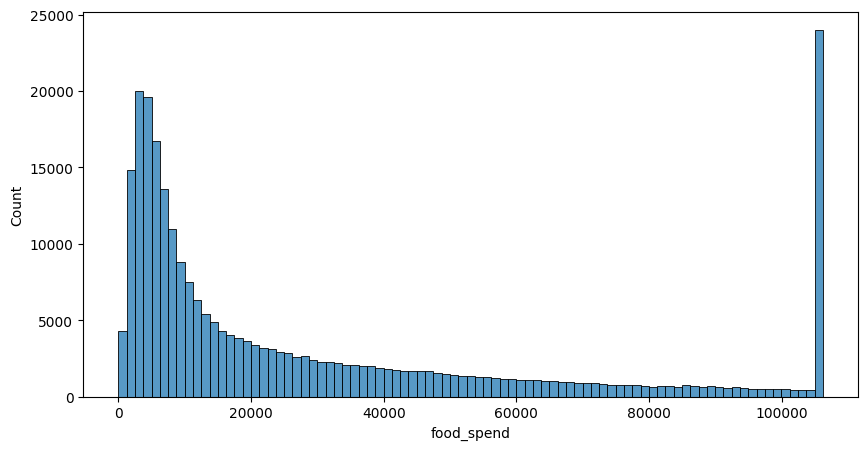

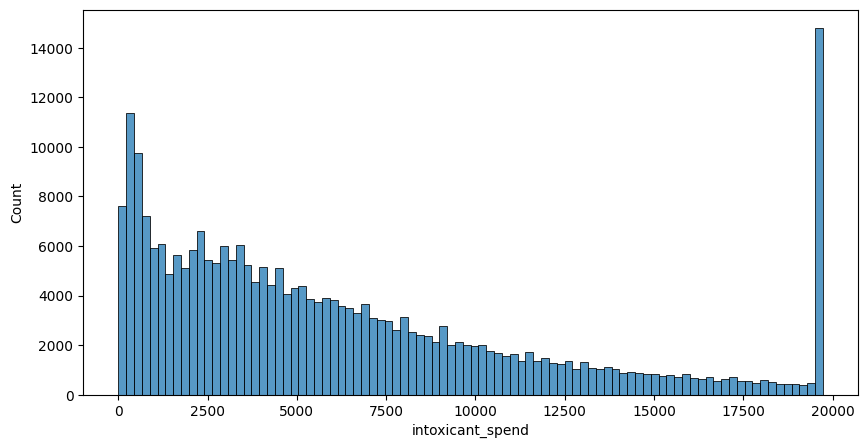

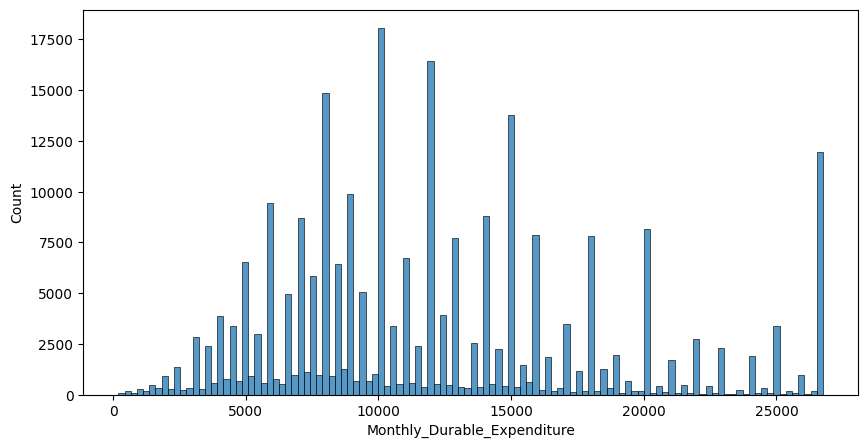

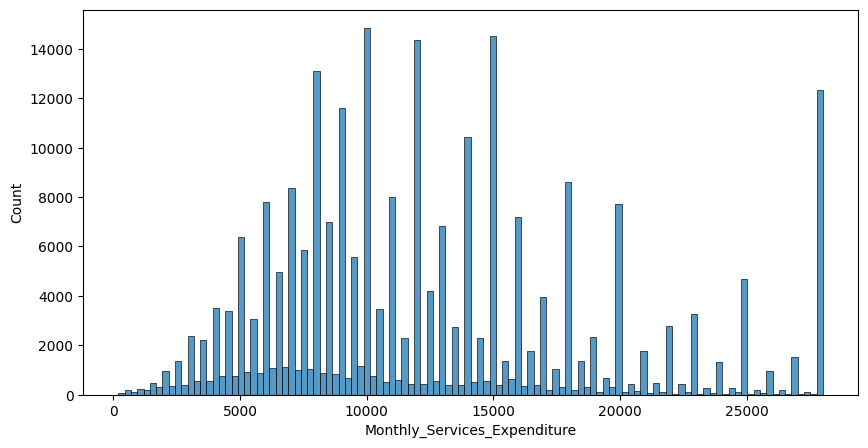

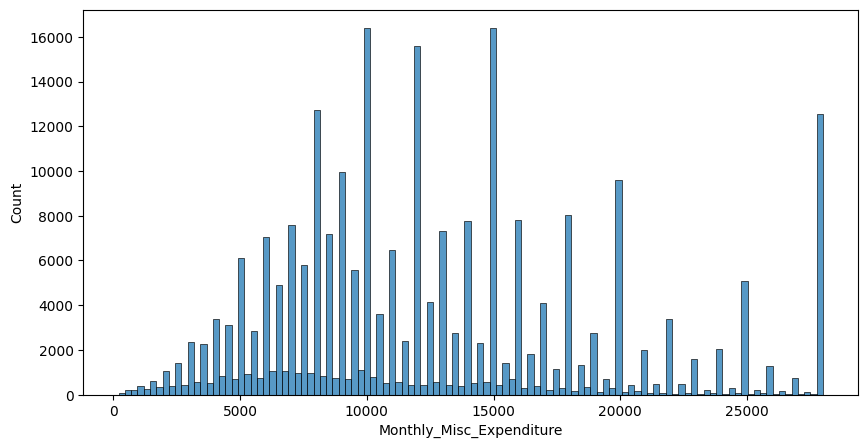

In [ ]:
#checking with the histplot
for i in ['food_spend','intoxicant_spend','Monthly_Durable_Expenditure','Monthly_Services_Expenditure','Monthly_Misc_Expenditure']:
  plt.figure(figsize=(10,5))
  sns.histplot(df2[i])
  plt.show()

In [ ]:
#data shape
df2.shape

(261953, 30)

In [ ]:
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,154613,1855356,38653.25,South,871.20,19.80
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,135594,1627128,33898.50,South,435.60,27.70
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754.00,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South,435.60,19.80
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144.00,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South,1306.80,10.30
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,109149,1309788,51155.43,South,871.20,27.70


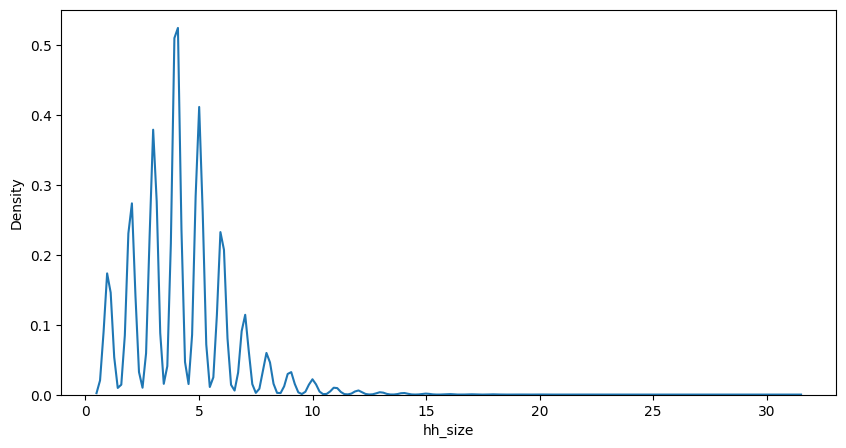

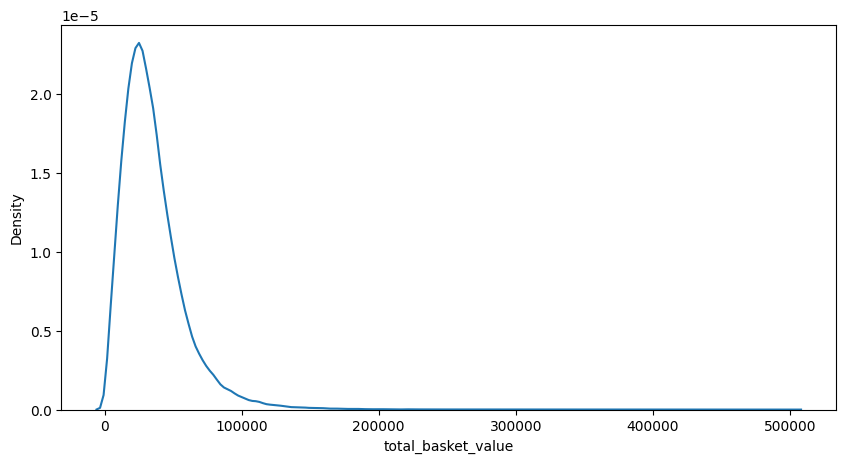

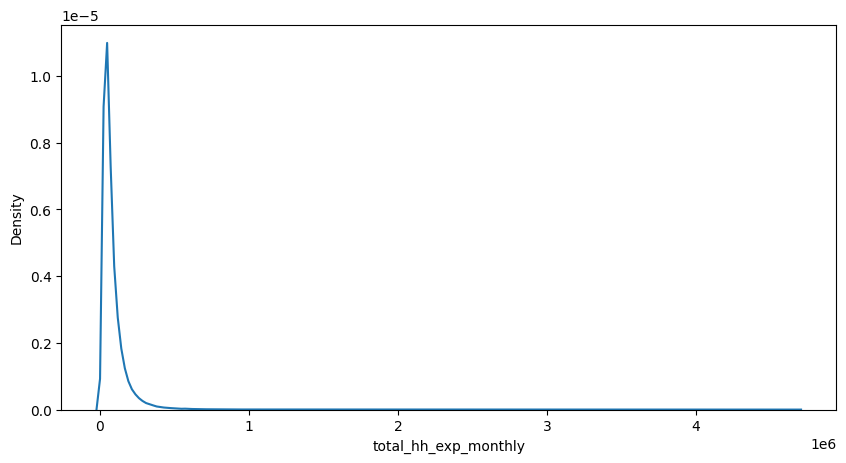

In [ ]:
#observing with kde plot household size, household expenditure and total basket value
for i in ['hh_size','total_basket_value','total_hh_exp_monthly']:
  plt.figure(figsize=(10,5))
  sns.kdeplot(df2[i])
  plt.show

**Inferences**

- We observe that our data is left skewed which indicates high bias hence we treat the outliers for normal distribution.

In [ ]:
#treating the outliers
df2['hh_size'] = handle_outliers_iqr(df2, 'hh_size')
df2['total_basket_value'] = handle_outliers_iqr(df2, 'total_basket_value')
df2['total_hh_exp'] = handle_outliers_iqr(df2, 'total_hh_exp_monthly')

Treated hh_size: Lower Fence: 0.00 | Upper Fence: 8.00
Treated total_basket_value: Lower Fence: -18295.00 | Upper Fence: 83185.00
Treated total_hh_exp_monthly: Lower Fence: -56993.50 | Upper Fence: 196154.50


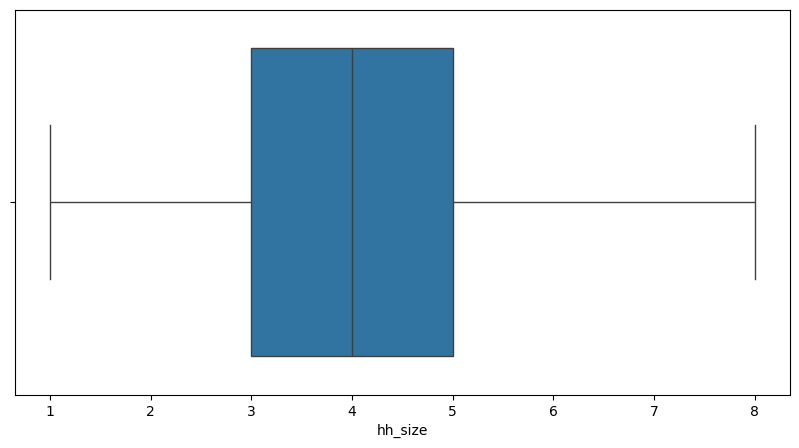

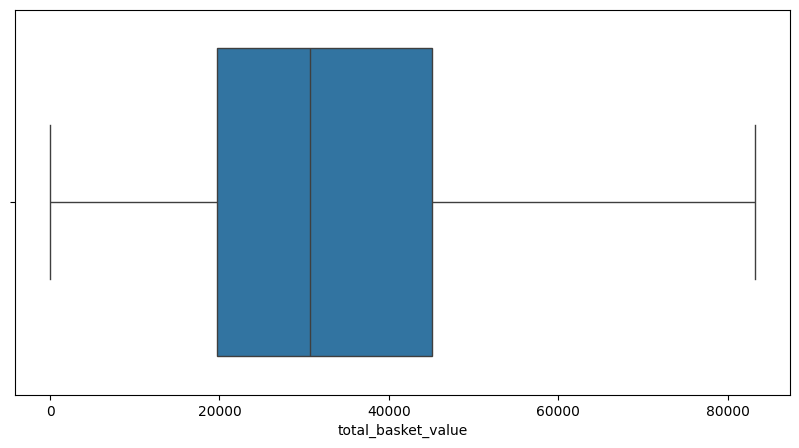

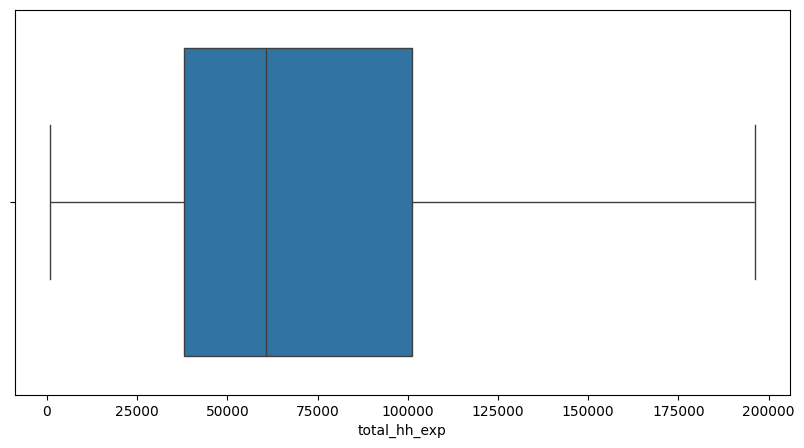

In [ ]:
#plotting after treating outliers using boxplot
for i in ['hh_size','total_basket_value','total_hh_exp']:
  plt.figure(figsize=(10,5))
  sns.boxplot(x=df2[i])
  plt.show()

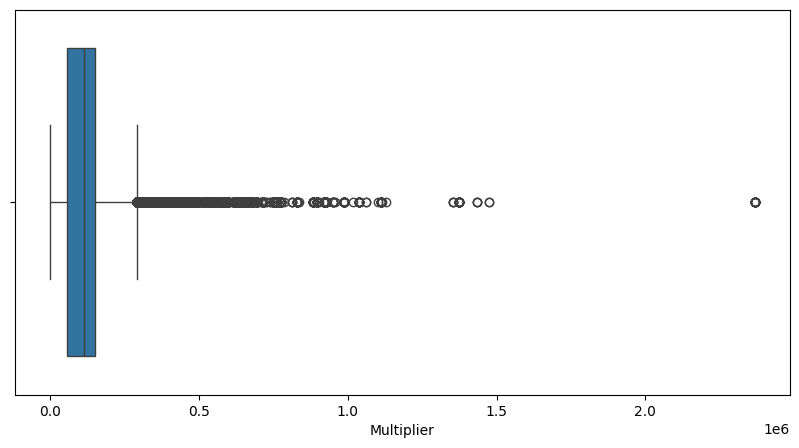

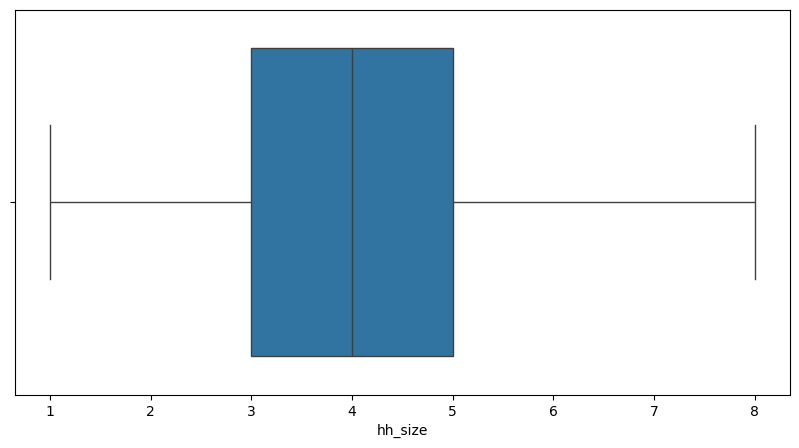

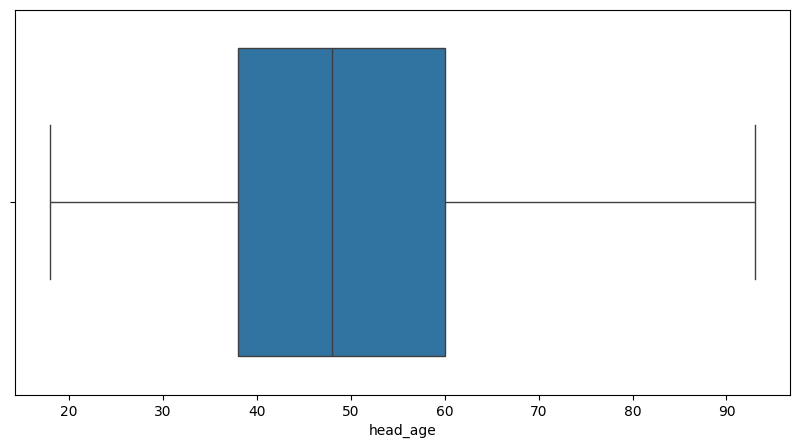

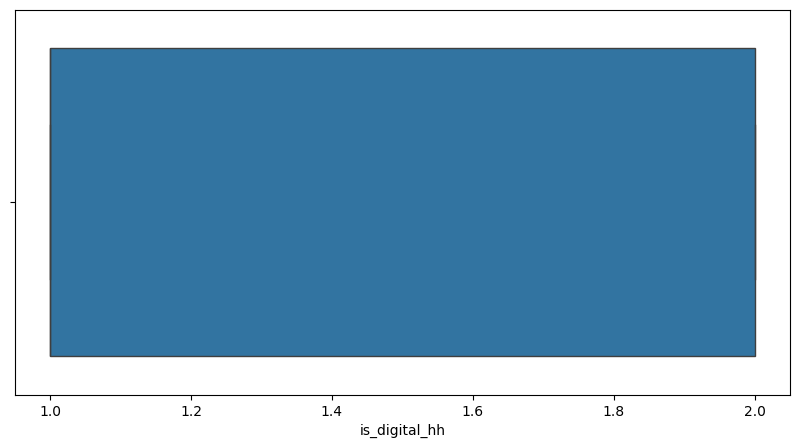

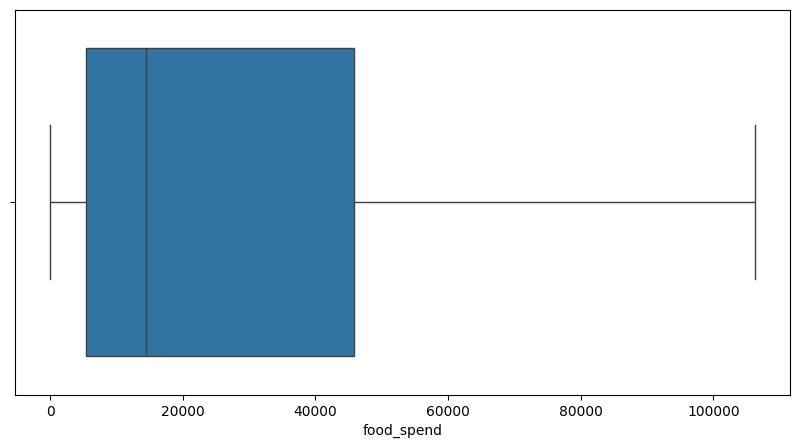

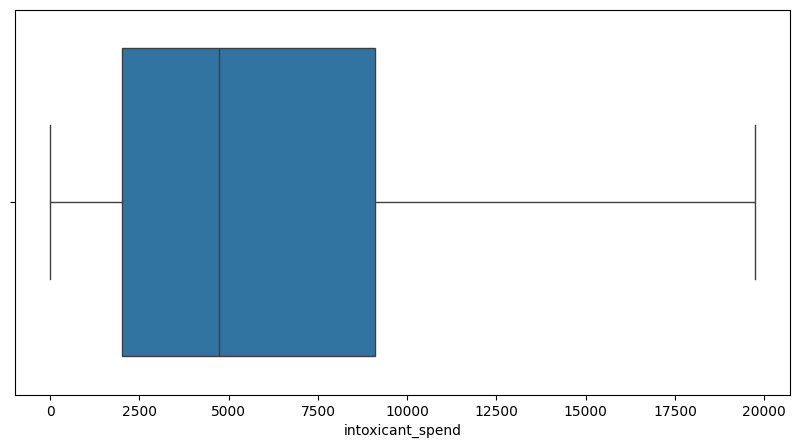

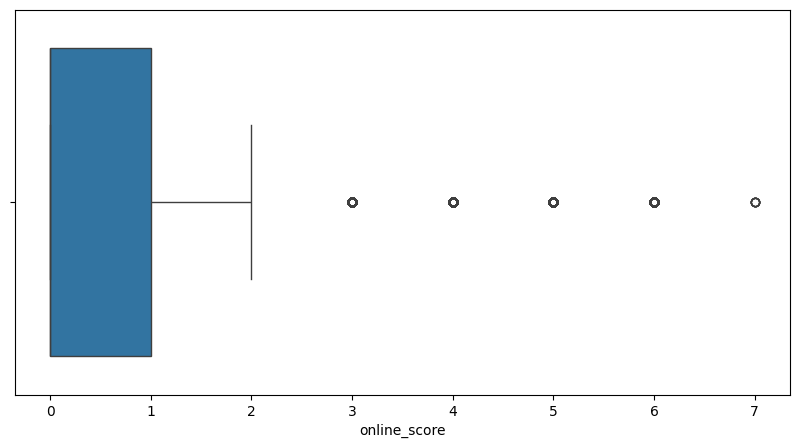

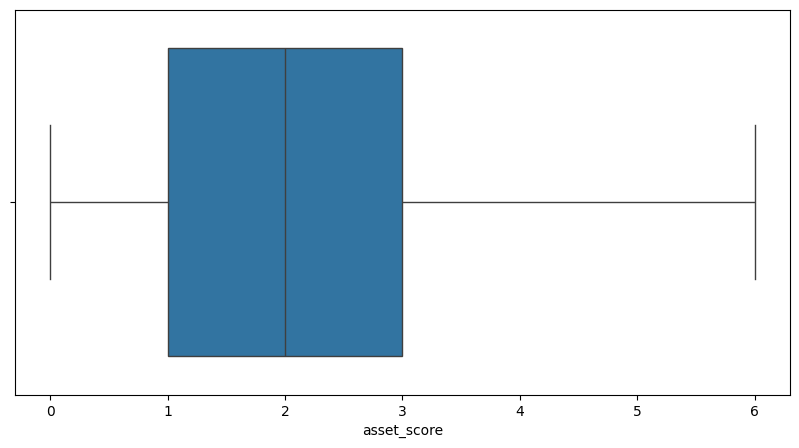

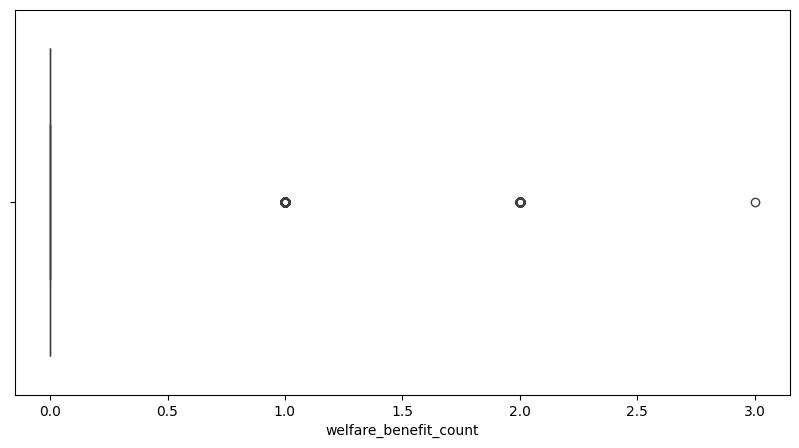

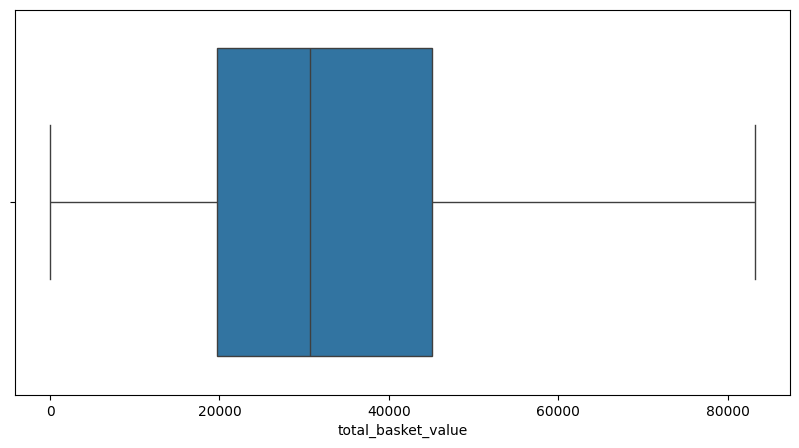

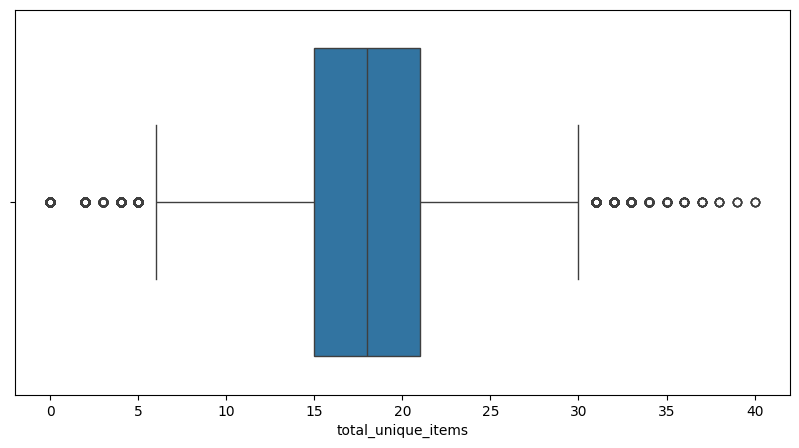

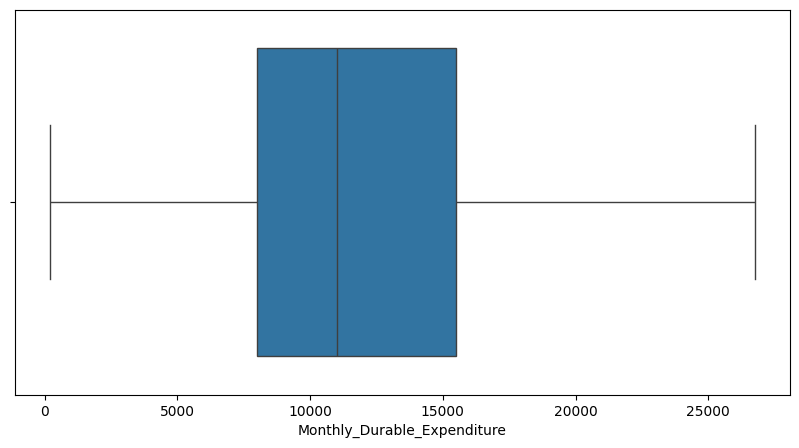

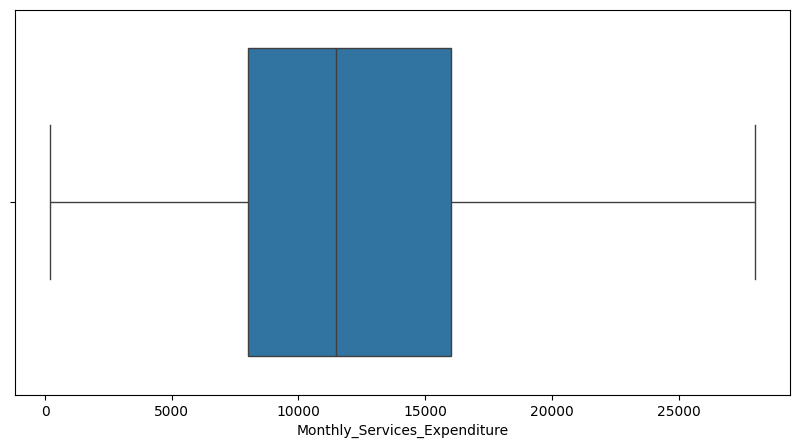

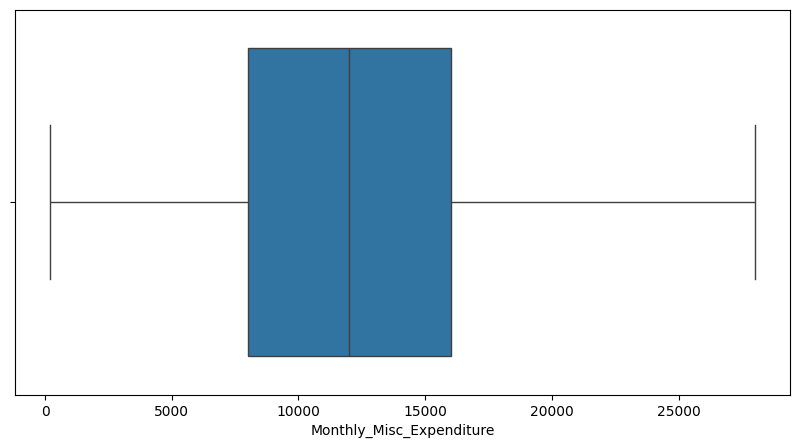

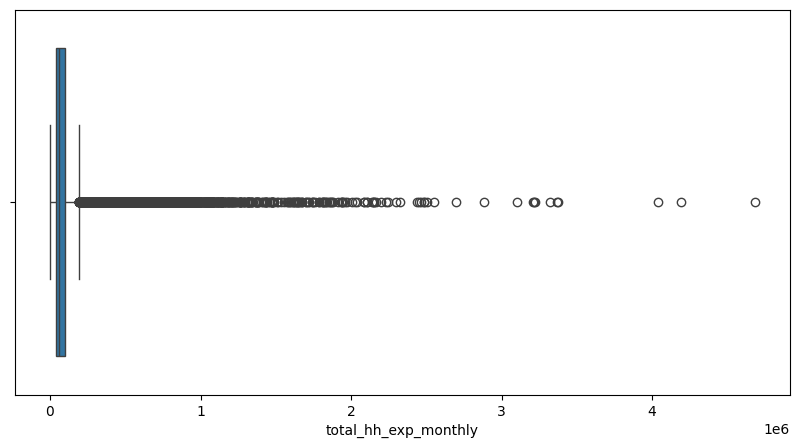

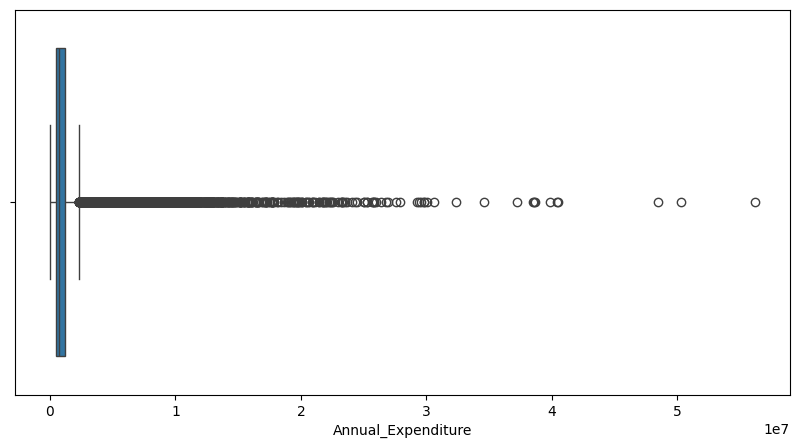

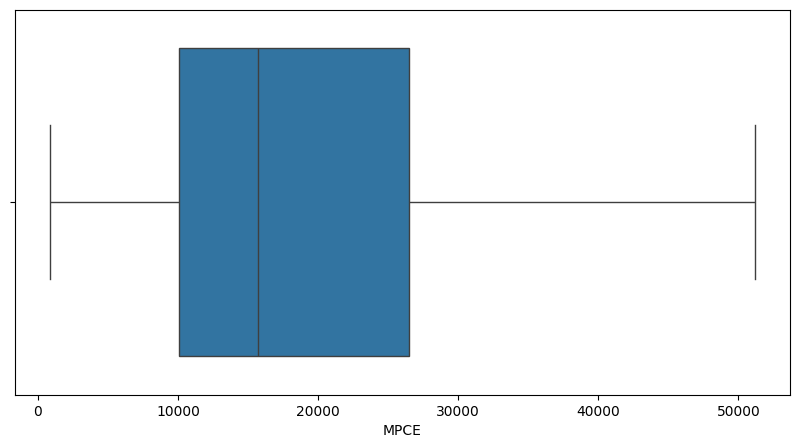

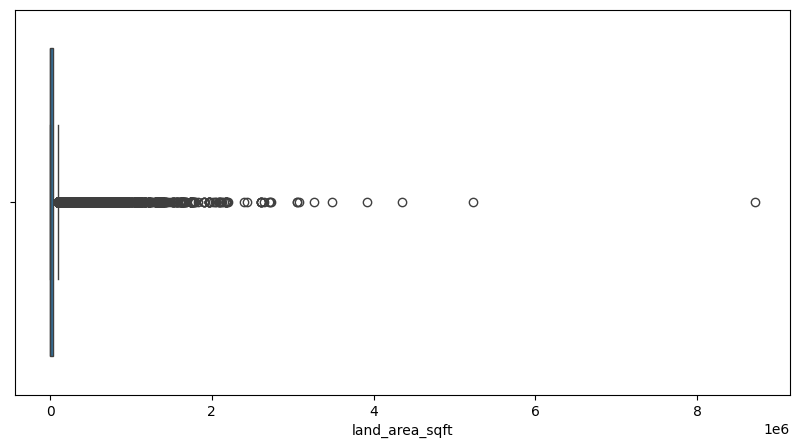

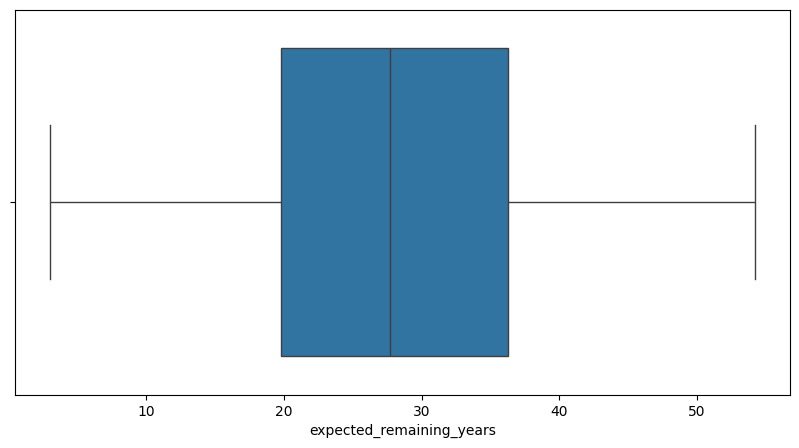

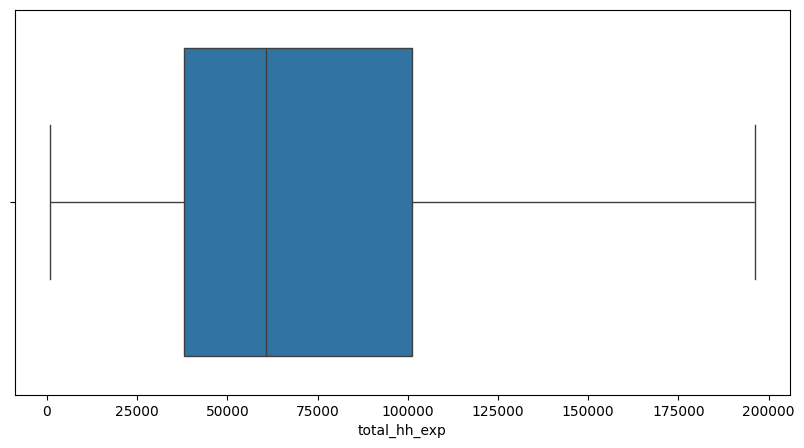

In [ ]:
#checking with box plots to all numeric coluns
for i in df2.select_dtypes(include=['int64', 'float64']).columns:
  plt.figure(figsize=(10,5))
  sns.boxplot(x=df2[i])
  plt.show()


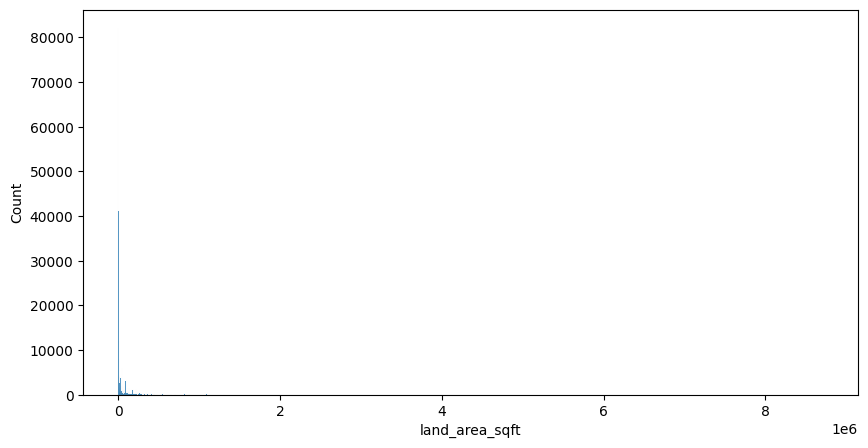

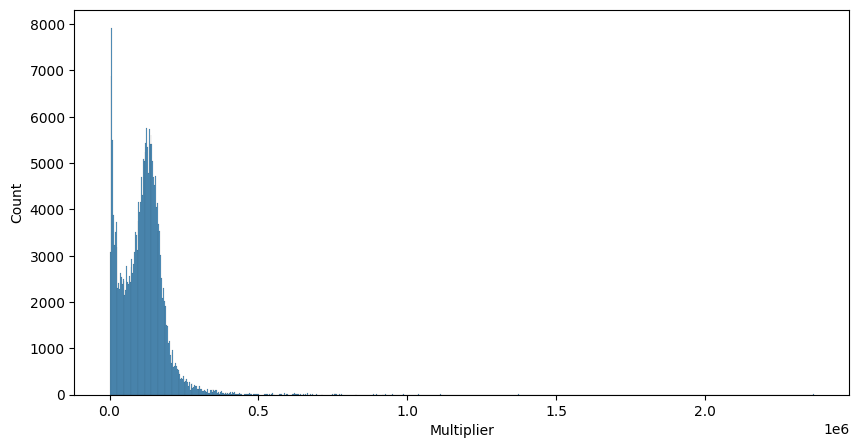

In [ ]:
#checking for multiplier and land area in sqft with histplot
for i in ['land_area_sqft','Multiplier']:
  plt.figure(figsize=(10,5))
  sns.histplot(df2[i])
  plt.show()


In [ ]:
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,total_hh_exp
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,154613,1855356,38653.25,South,871.20,19.80,154613.00
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,135594,1627128,33898.50,South,435.60,27.70,135594.00
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754.00,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South,435.60,19.80,77844.00
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144.00,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South,1306.80,10.30,81664.00
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,109149,1309788,51155.43,South,871.20,27.70,109149.00


**Inferences**

Since multiplier define the  number of typical households in that particular area, hence we do not treat the outliers and land owned by consumers can be high since in rural side most consumers are into farming and agriculture hence we do not treat the outliers

In [ ]:
#treating the outliers for annual expenditure
df2['Annual_Expenditure'] = handle_outliers_iqr(df2, 'Annual_Expenditure')
print(f"\nMax Annual Expenditure after treatment: {df2['Annual_Expenditure'].max()}")

Treated Annual_Expenditure: Lower Fence: -683922.00 | Upper Fence: 2353854.00

Max Annual Expenditure after treatment: 2353854


In [ ]:
#read data
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,total_hh_exp
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,154613,1855356,38653.25,South,871.20,19.80,154613.00
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,135594,1627128,33898.50,South,435.60,27.70,135594.00
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754.00,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South,435.60,19.80,77844.00
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144.00,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South,1306.80,10.30,81664.00
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,109149,1309788,51155.43,South,871.20,27.70,109149.00


##**Graphical Analysis**

**Regionwise Household Consumables Expenditures**

Text(0.5, 0, 'Region')

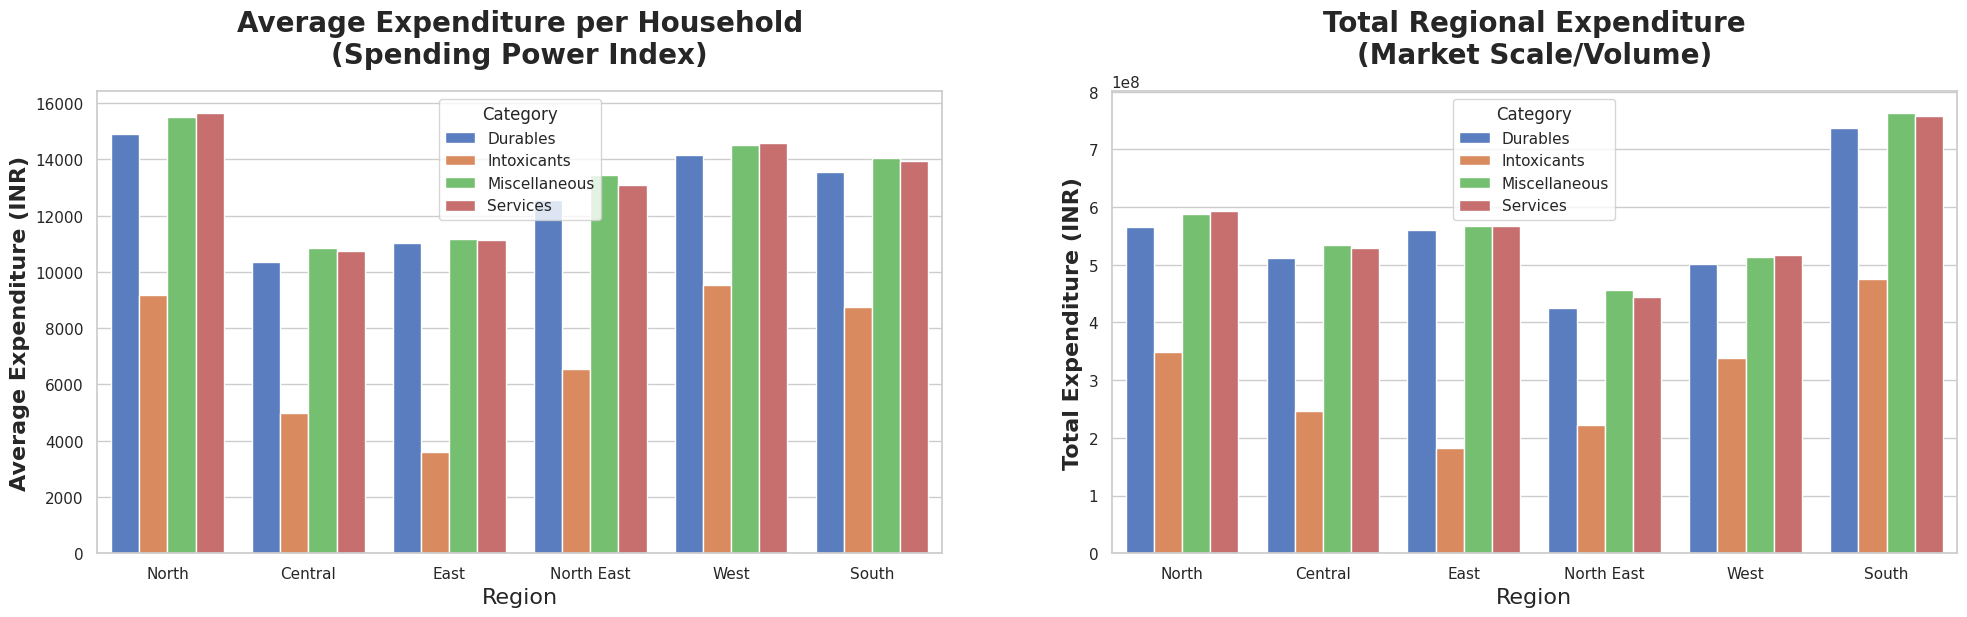

In [ ]:
# Configuration for categories
non_food_categories = {
    'Monthly_Durable_Expenditure': 'Durables',
    'Monthly_Services_Expenditure': 'Services',
    'Monthly_Misc_Expenditure': 'Miscellaneous',
    'intoxicant_spend': 'Intoxicants'
}

region_order = ['North', 'Central', 'East', 'North East', 'West', 'South']

# DATA PREPARATION (MELTING)
melted_df = df.melt(
    id_vars='Region',
    value_vars=list(non_food_categories.keys()),
    var_name='Category_Key',
    value_name='Spending'
)
melted_df['Category'] = melted_df['Category_Key'].map(non_food_categories)

# VISUALIZATION: Side-by-Side (Columnar) Layout
sns.set_theme(style="whitegrid")

# Create a figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(24,6))

# Subplot 1: Average (Intensity of consumption - Per Household)
avg_data = melted_df.groupby(['Region', 'Category'])['Spending'].mean().reset_index()
sns.barplot(
    data=avg_data, x='Region', y='Spending', hue='Category',
    order=region_order, ax=axes[0], palette='muted'
)
axes[0].set_title('Average Expenditure per Household\n(Spending Power Index)', fontsize=20, fontweight='bold', pad=20)
axes[0].set_ylabel('Average Expenditure (INR)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Region', fontsize=16)

# Subplot 2: Total (Market Size - Aggregate Volume)
total_data = melted_df.groupby(['Region', 'Category'])['Spending'].sum().reset_index()
sns.barplot(
    data=total_data, x='Region', y='Spending', hue='Category',
    order=region_order, ax=axes[1], palette='muted'
)
axes[1].set_title('Total Regional Expenditure\n(Market Scale/Volume)', fontsize=20, fontweight='bold', pad=20)
axes[1].set_ylabel('Total Expenditure (INR)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Region', fontsize=16)

**Inferences**

- Households in the Central and East have the lowest average expenditure on consumables comparatively to other regions, with North, South and West being the  highest average expenditures indicating most of the wealthiest houselholds identified.

- In the total expenditure plot south being the largest market distribution for consumables followed by North region with North east being the lowest addressable market.

- For intoxicants the highest average consumption for households are observed in the region North,South and West and lowest in the east and central.

- In the Total Expenditure we observe south being the largest market potential for intoxicants which is good reason to attract investments in manufacturing startups while lowest market potential in the east region due to the lack of population.

- In the plots we also observe that most households have higher expenditures on services and miscellaneous comparatively to durables,also the market size for services and miscellaneous is higher to that of durables.

In [ ]:
#read data
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,total_hh_exp
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,154613,1855356,38653.25,South,871.20,19.80,154613.00
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,135594,1627128,33898.50,South,435.60,27.70,135594.00
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754.00,15090,0,5,0,27820,15,17500,17000,16500,77844,934128,38922.00,South,435.60,19.80,77844.00
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144.00,15020,0,5,0,30940,14,18000,17500,18000,81664,979968,40832.00,South,1306.80,10.30,81664.00
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,109149,1309788,51155.43,South,871.20,27.70,109149.00


In [ ]:
#since we have worked on outliers recalculating the total_hh_exp_monthly values
df2['total_hh_exp_monthly'] = df2['food_spend'] + df2['intoxicant_spend'] + df2['Monthly_Durable_Expenditure'] + df2['Monthly_Services_Expenditure'] + df2['Monthly_Misc_Expenditure']
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,total_hh_exp
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1855356,38653.25,South,871.20,19.80,154613.00
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1627128,33898.50,South,435.60,27.70,135594.00
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754.00,15090,0,5,0,27820,15,17500,17000,16500,77844.00,934128,38922.00,South,435.60,19.80,77844.00
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144.00,15020,0,5,0,30940,14,18000,17500,18000,81664.00,979968,40832.00,South,1306.80,10.30,81664.00
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1309788,51155.43,South,871.20,27.70,109149.00


In [ ]:
#recalculating the annual expenditure
df2['Annual_Expenditure'] = df2['total_hh_exp_monthly'] * 12
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,total_hh_exp
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,154613.00
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,135594.00
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754.00,15090,0,5,0,27820,15,17500,17000,16500,77844.00,934128.00,38922.00,South,435.60,19.80,77844.00
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144.00,15020,0,5,0,30940,14,18000,17500,18000,81664.00,979968.00,40832.00,South,1306.80,10.30,81664.00
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,109149.00


In [ ]:
#dropping total_hh_exp
df2.drop('total_hh_exp',axis=1,inplace=True)
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754.00,15090,0,5,0,27820,15,17500,17000,16500,77844.00,934128.00,38922.00,South,435.60,19.80
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144.00,15020,0,5,0,30940,14,18000,17500,18000,81664.00,979968.00,40832.00,South,1306.80,10.30
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70


**Region Wise Basket Value and MPCE**

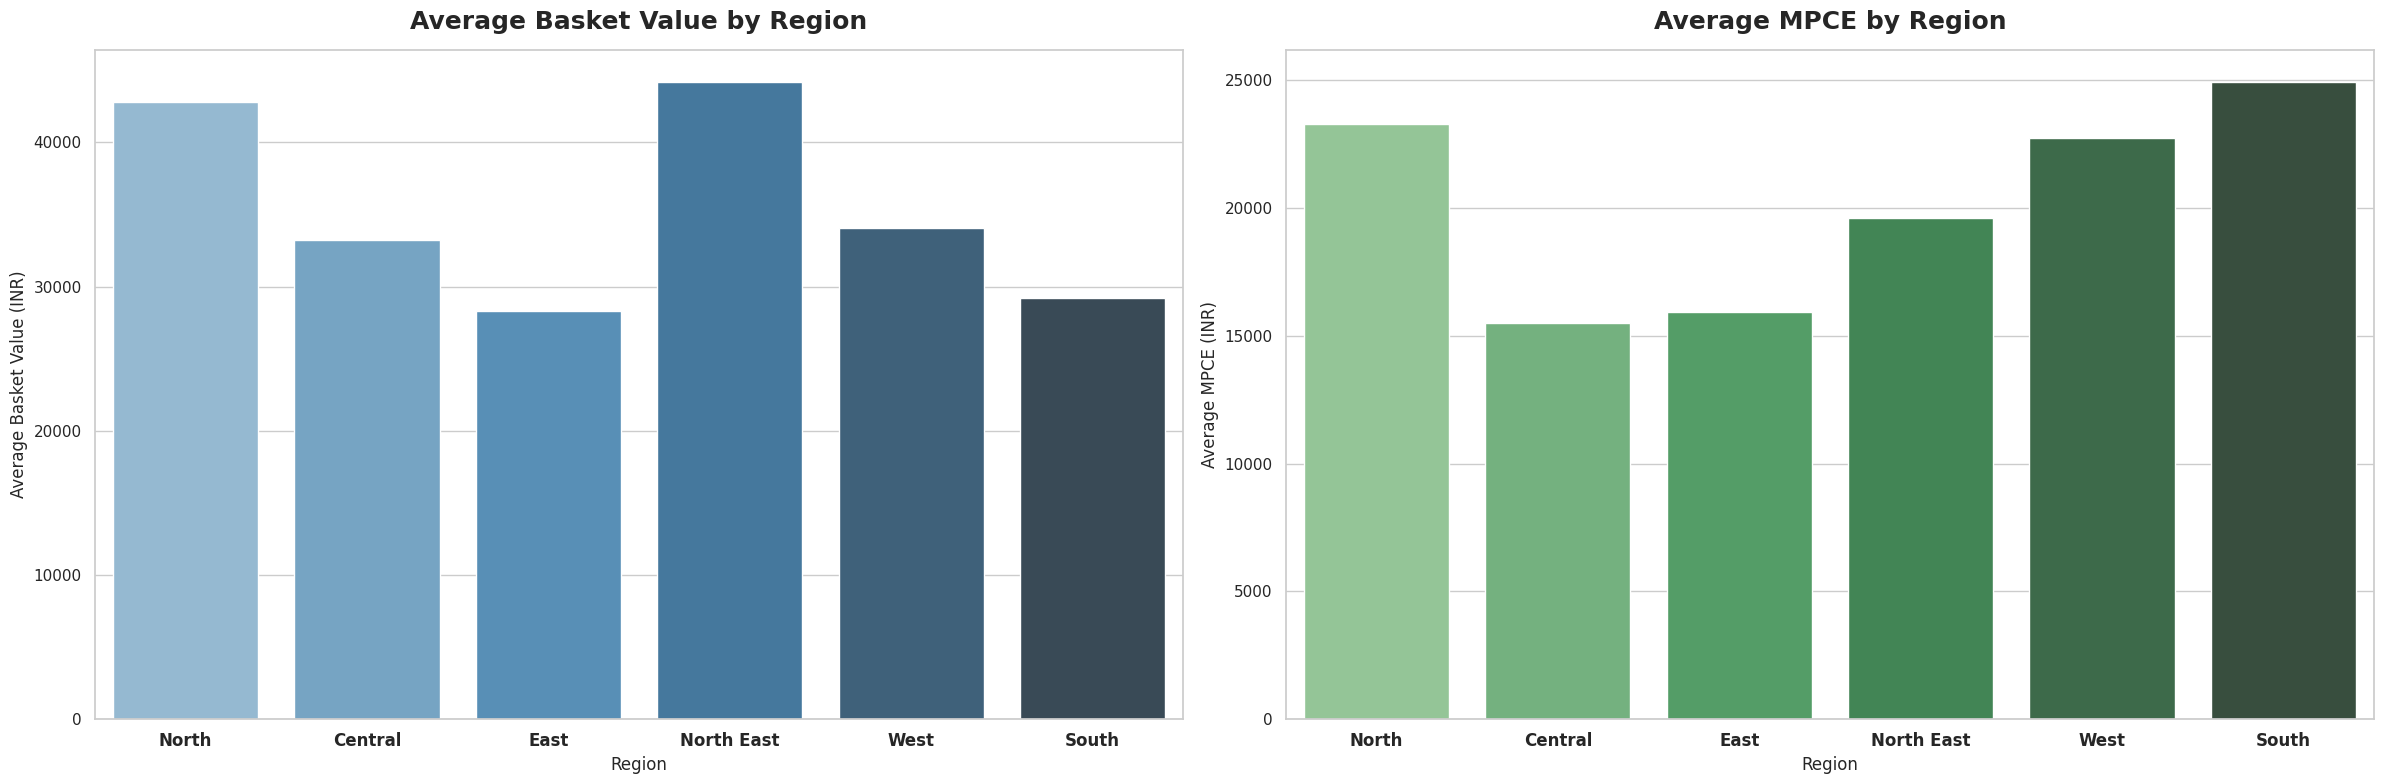

In [ ]:
# Set professional theme
sns.set_theme(style="whitegrid")

# Create a figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(24, 8))

# Subplot 1: Average Total Basket Value by Region
basket_data = df2.groupby('Region')['total_basket_value'].mean().reindex(region_order).reset_index()
sns.barplot(data=basket_data, x='Region', y='total_basket_value', ax=axes[0], palette='Blues_d')
axes[0].set_title('Average Basket Value by Region', fontsize=18, fontweight='bold', pad=15)
axes[0].set_ylabel('Average Basket Value (INR)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), fontweight='bold', fontsize=12)

# Subplot 2: Average MPCE by Region
mpce_data = df2.groupby('Region')['MPCE'].mean().reindex(region_order).reset_index()
sns.barplot(data=mpce_data, x='Region', y='MPCE', ax=axes[1], palette='Greens_d')
axes[1].set_title('Average MPCE by Region', fontsize=18, fontweight='bold', pad=15)
axes[1].set_ylabel('Average MPCE (INR)')
axes[1].set_xticklabels(axes[0].get_xticklabels(), fontweight='bold', fontsize=12)

plt.tight_layout()

**Inferences**

- The North region has a higher basket value and higher mpce which indicates that the region has high buying power within households and are bulk buyers with large family size.

- Central and East region comparatively have lower basket value and mpce which indicates that the market size is lower and expenses are based on price sensitivity.

- The North East region has higher basket value but lower mpce may be due to bulk buying and high storage purchases or limited budget.

- In the West and South mpe is higher but the basket value is lower which reveals that these consumers are inclined towards premium goods and services and generally have household size lower.

**Region Wise Average HH Size and Basket Value**

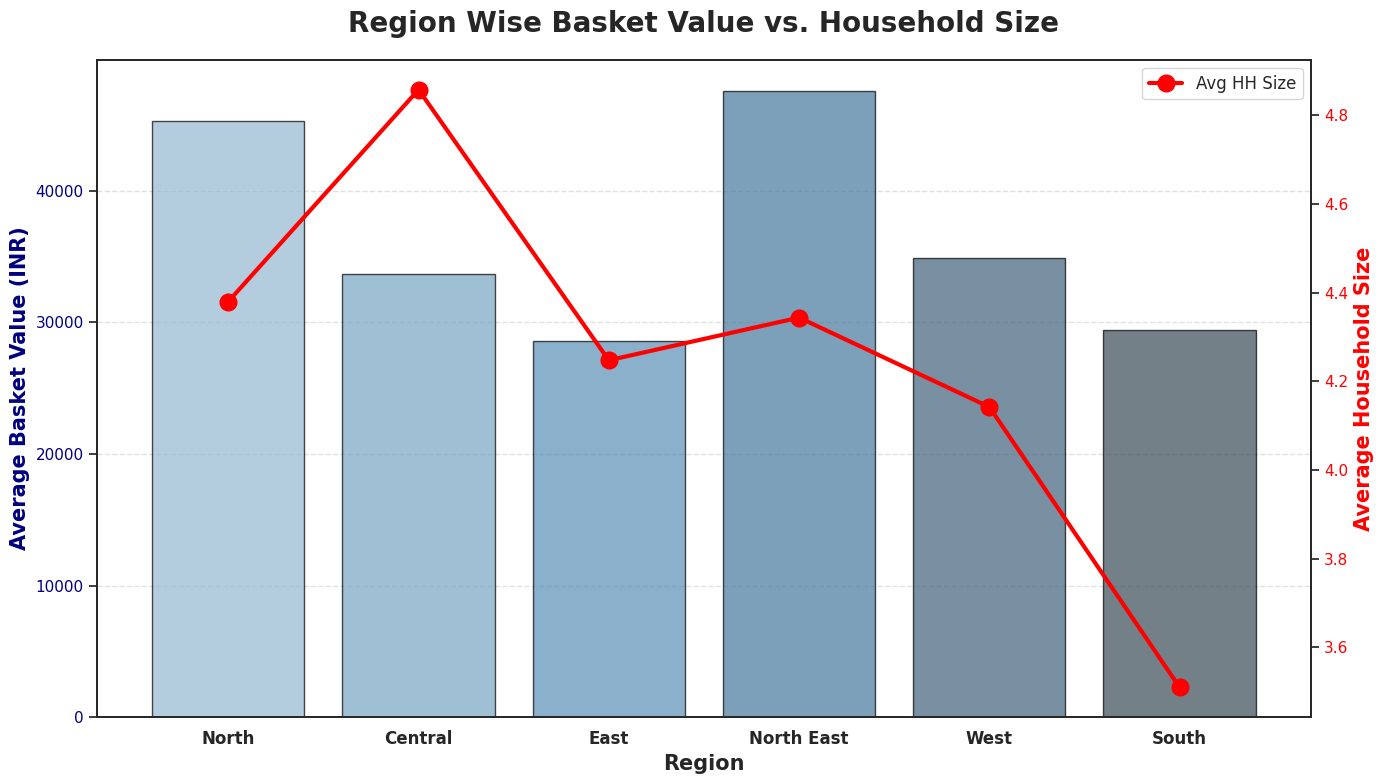

In [ ]:
sns.set_theme(style="white") # White style is cleaner for dual-axis
region_order = ['North', 'Central', 'East', 'North East', 'West', 'South']

# 3. Calculate Regional Averages
stats = df.groupby('Region').agg({
    'total_basket_value': 'mean',
    'hh_size': 'mean'
}).reindex(region_order).reset_index()

# 4. Create the Figure and the first Axis (Bars)
fig, ax1 = plt.subplots(figsize=(14, 8))

# Primary Plot: Average Basket Value (Bar Chart)
sns.barplot(
    data=stats,
    x='Region',
    y='total_basket_value',
    ax=ax1,
    palette='Blues_d',
    alpha=0.7,
    edgecolor='black'
)

# 5. Create the second Axis (Line) sharing the same X-axis
ax2 = ax1.twinx()

# Secondary Plot: Average Household Size (Line with Markers)
ax2.plot(
    stats['Region'],
    stats['hh_size'],
    color='red',
    marker='o',
    linewidth=3,
    markersize=12,
    label='Avg HH Size'
)

# 6. Formatting Labels and Titles
ax1.set_title('Region Wise Basket Value vs. Household Size', fontsize=20, fontweight='bold', pad=20)
ax1.set_xlabel('Region', fontsize=15, fontweight='bold')
ax1.set_ylabel('Average Basket Value (INR)', fontsize=15, fontweight='bold', color='navy')
ax2.set_ylabel('Average Household Size', fontsize=15, fontweight='bold', color='red')

# Adjust tick formatting
ax1.tick_params(axis='y', labelcolor='navy')
ax2.tick_params(axis='y', labelcolor='red')
ax1.set_xticklabels(region_order, fontsize=12, fontweight='bold')

# Adding a legend for the line
ax2.legend(loc='upper right', frameon=True, fontsize=12)

# 7. Add Gridlines for the bars only to keep it clean
ax1.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()

**Inferences**
- North and North East Both have high basket value and higher family size which indicates that these are the frequent bulk buyers and have low storage capacity.

- The Central Region we observe that the basket value is lower but the family size is highest which explains a price sensitive market and purchases are based on daily needs.

- East and the West both have high basket value and high family size indicating a growing and mature stable market respectively.

- South Region is the premium market for businesses where the basket value is higher and the family size is lower this indicates south region households invest much in expensive brands, health-conscious items, or luxury goods.

In [ ]:
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70
2,22300_2_2,Puducherry,urban,2,27497,2,63,male,married,Post Graduate+,1,Urban: Others,Non-Priority (APL),Firewood/Chips,11754.00,15090,0,5,0,27820,15,17500,17000,16500,77844.00,934128.00,38922.00,South,435.60,19.80
3,22300_2_3,Puducherry,urban,2,27497,2,68,male,married,Primary,2,Urban: Others,Non-Priority (APL),Firewood/Chips,13144.00,15020,0,5,0,30940,14,18000,17500,18000,81664.00,979968.00,40832.00,South,1306.80,10.30
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70


 **Sector wise Households Consumables Expenditure**

        Monthly_Durable_Expenditure  Monthly_Services_Expenditure  \
Sector                                                              
rural                      10781.70                      11001.94   
urban                      14281.38                      14886.77   

        Monthly_Misc_Expenditure  intoxicant_spend  
Sector                                              
rural                   11121.45           3748.02  
urban                   15031.14          10011.44  


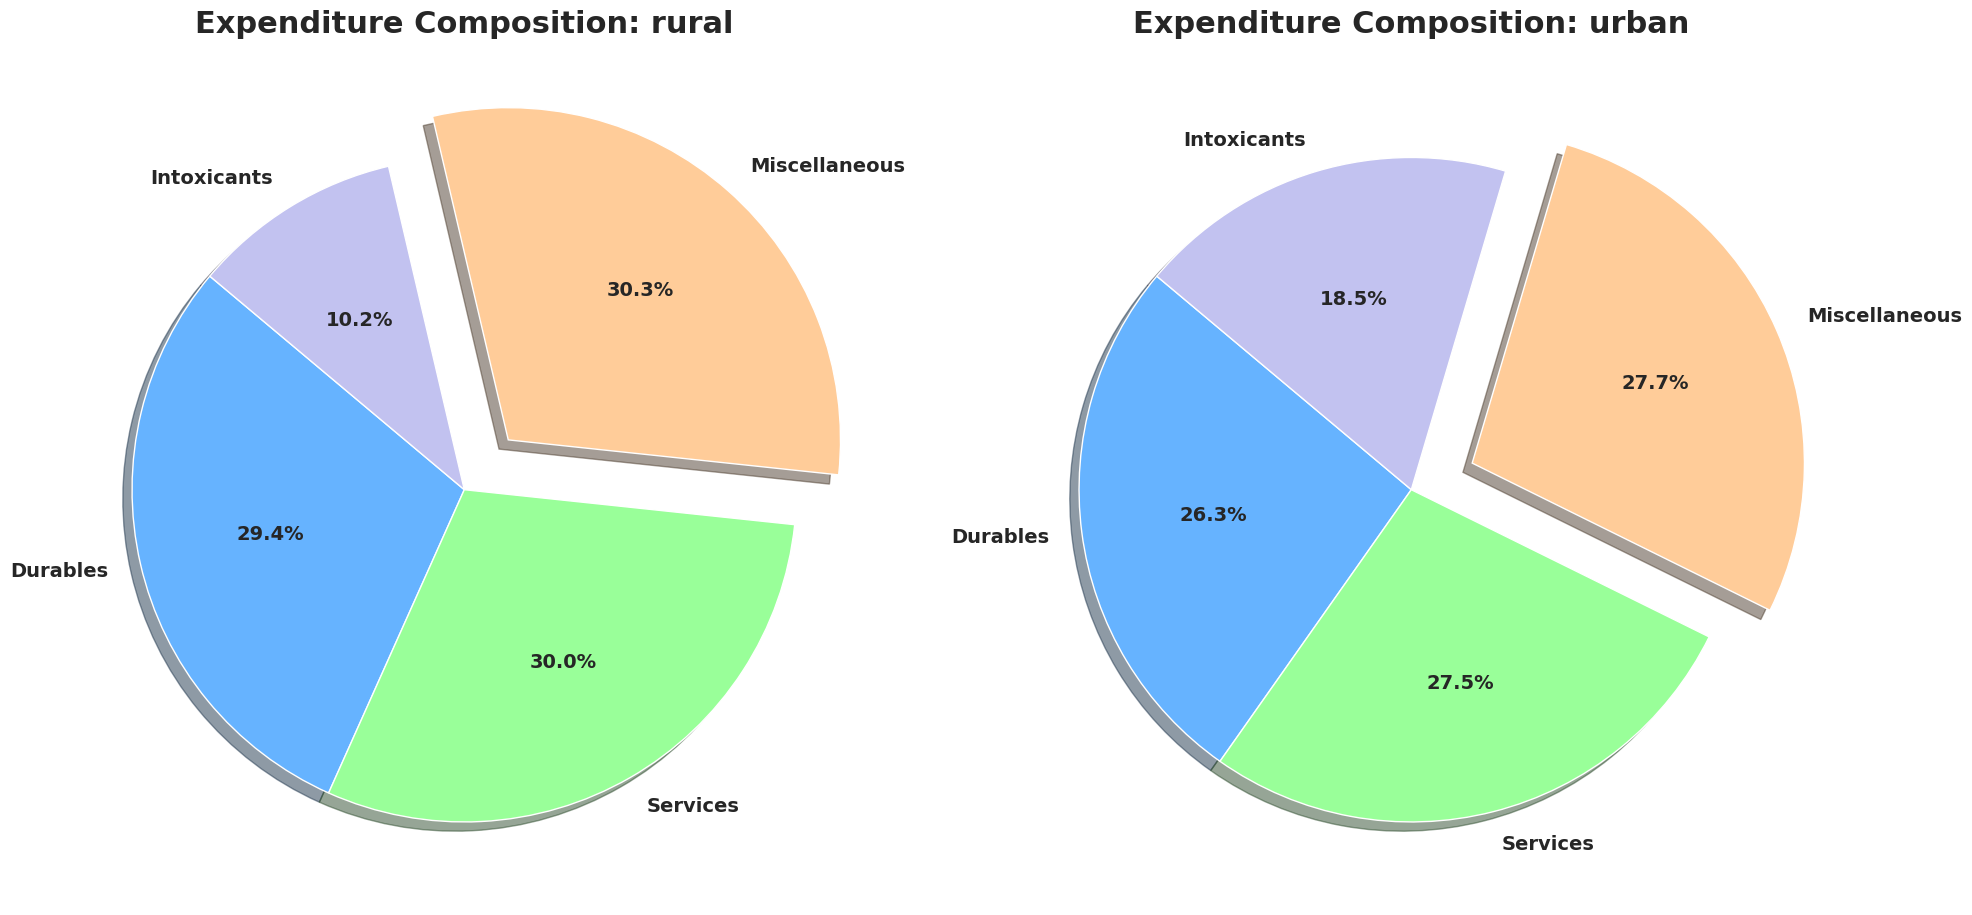

In [ ]:
exp_cols = {
    'Monthly_Durable_Expenditure': 'Durables',
    'Monthly_Services_Expenditure': 'Services',
    'Monthly_Misc_Expenditure': 'Miscellaneous',
    'intoxicant_spend': 'Intoxicants'
}

# 3. Group by your 'Sector' column and calculate the averages
sector_data = df2.groupby('Sector')[list(exp_cols.keys())].mean()

# 4. Create the Visualization
sectors = sector_data.index.tolist()
fig, axes = plt.subplots(1, len(sectors), figsize=(10 * len(sectors), 10))

# Custom professional color palette
colors = [ '#66B3FF', '#99FF99', '#FFCC99', '#C2C2F0']

# Handle cases with single or multiple sectors
if len(sectors) == 1:
    axes = [axes]

for i, sector in enumerate(sectors):
    values = sector_data.loc[sector].values
    labels = list(exp_cols.values())

    # Logic for 'Highest Explode': Automatically find the max value to separate it
    max_val = max(values)
    explode = [0.2 if v == max_val else 0 for v in values]

    # Plotting the Pie Chart
    axes[i].pie(
        values,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        explode=explode,
        shadow=True,
        colors=colors,
        textprops={'fontsize': 14, 'fontweight': 'bold'}
    )
    # The title will use the names you mapped (Rural/Urban) or the existing values
    axes[i].set_title(f'Expenditure Composition: {sector}', fontsize=22, fontweight='bold', pad=30)

plt.tight_layout()
print(sector_data)

**Inferences**

- Household in the rural side value more for quality of life and establish a potential of growing households with the lowest market size for the intoxicants.

- In the Urban side the consumer market expenditure is a stable and mature market where purchases has a pattern for less volume and high price, also purchases on intoxicants is marginally higher by 8%.

**Sector wise basket value and mpce**

        total_basket_value     MPCE
Sector                             
rural             31622.80 15259.12
urban             38237.58 27235.21


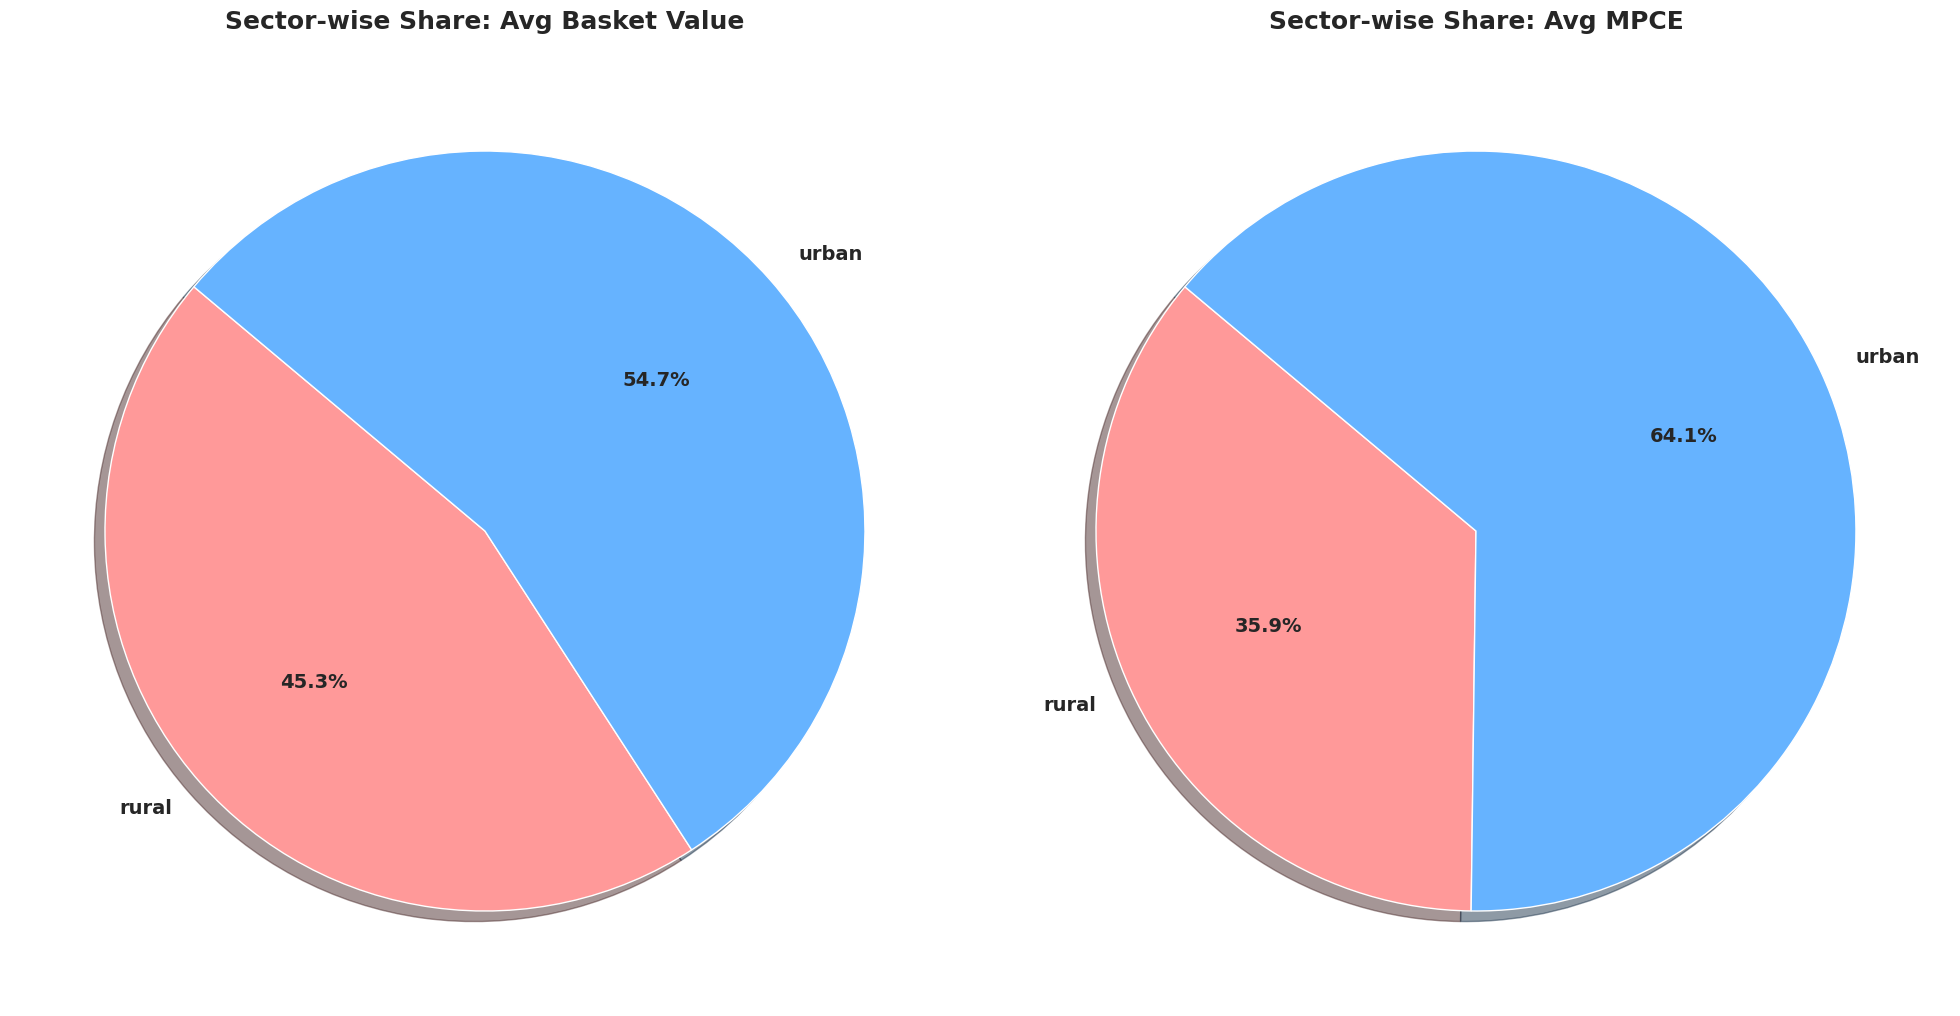

In [ ]:
# Assuming Sector column contains 'Rural' and 'Urban'
sector_metrics = df2.groupby('Sector')[['total_basket_value', 'MPCE']].mean()

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
colors = ['#FF9999','#66B3FF']

# 1. Pie Chart for Total Basket Value
values_bv = sector_metrics['total_basket_value'].values
max_idx_bv = values_bv.argmax()
explode_bv = [0.15 if i == max_idx_bv else 0 for i in range(len(values_bv))]

axes[0].pie(values_bv, labels=sector_metrics.index, autopct='%1.1f%%',
            startangle=140, shadow=True, colors=colors,
            textprops={'fontsize': 14, 'fontweight': 'bold'})
axes[0].set_title('Sector-wise Share: Avg Basket Value', fontsize=18, fontweight='bold', pad=20)

# 2. Pie Chart for MPCE
values_mpce = sector_metrics['MPCE'].values
max_idx_mpce = values_mpce.argmax()
explode_mpce = [0.15 if i == max_idx_mpce else 0 for i in range(len(values_mpce))]

axes[1].pie(values_mpce, labels=sector_metrics.index, autopct='%1.1f%%',
            startangle=140, shadow=True, colors=colors,
            textprops={'fontsize': 14, 'fontweight': 'bold'})
axes[1].set_title('Sector-wise Share: Avg MPCE', fontsize=18, fontweight='bold', pad=20)

plt.tight_layout()
print(sector_metrics)

**Inferences**

- The rural regions have higher basket value but lower mpce which indicates that the consumers in rural regions have larger households that prefer stock pile buying and prefer lower margin products.

- The Urban Sector has a higher basket and high mpce which indicate that the household sizes are generally smaller and prefer premium buying with potential for high margin products.

**Education wise Average Basket and Mpce Value**

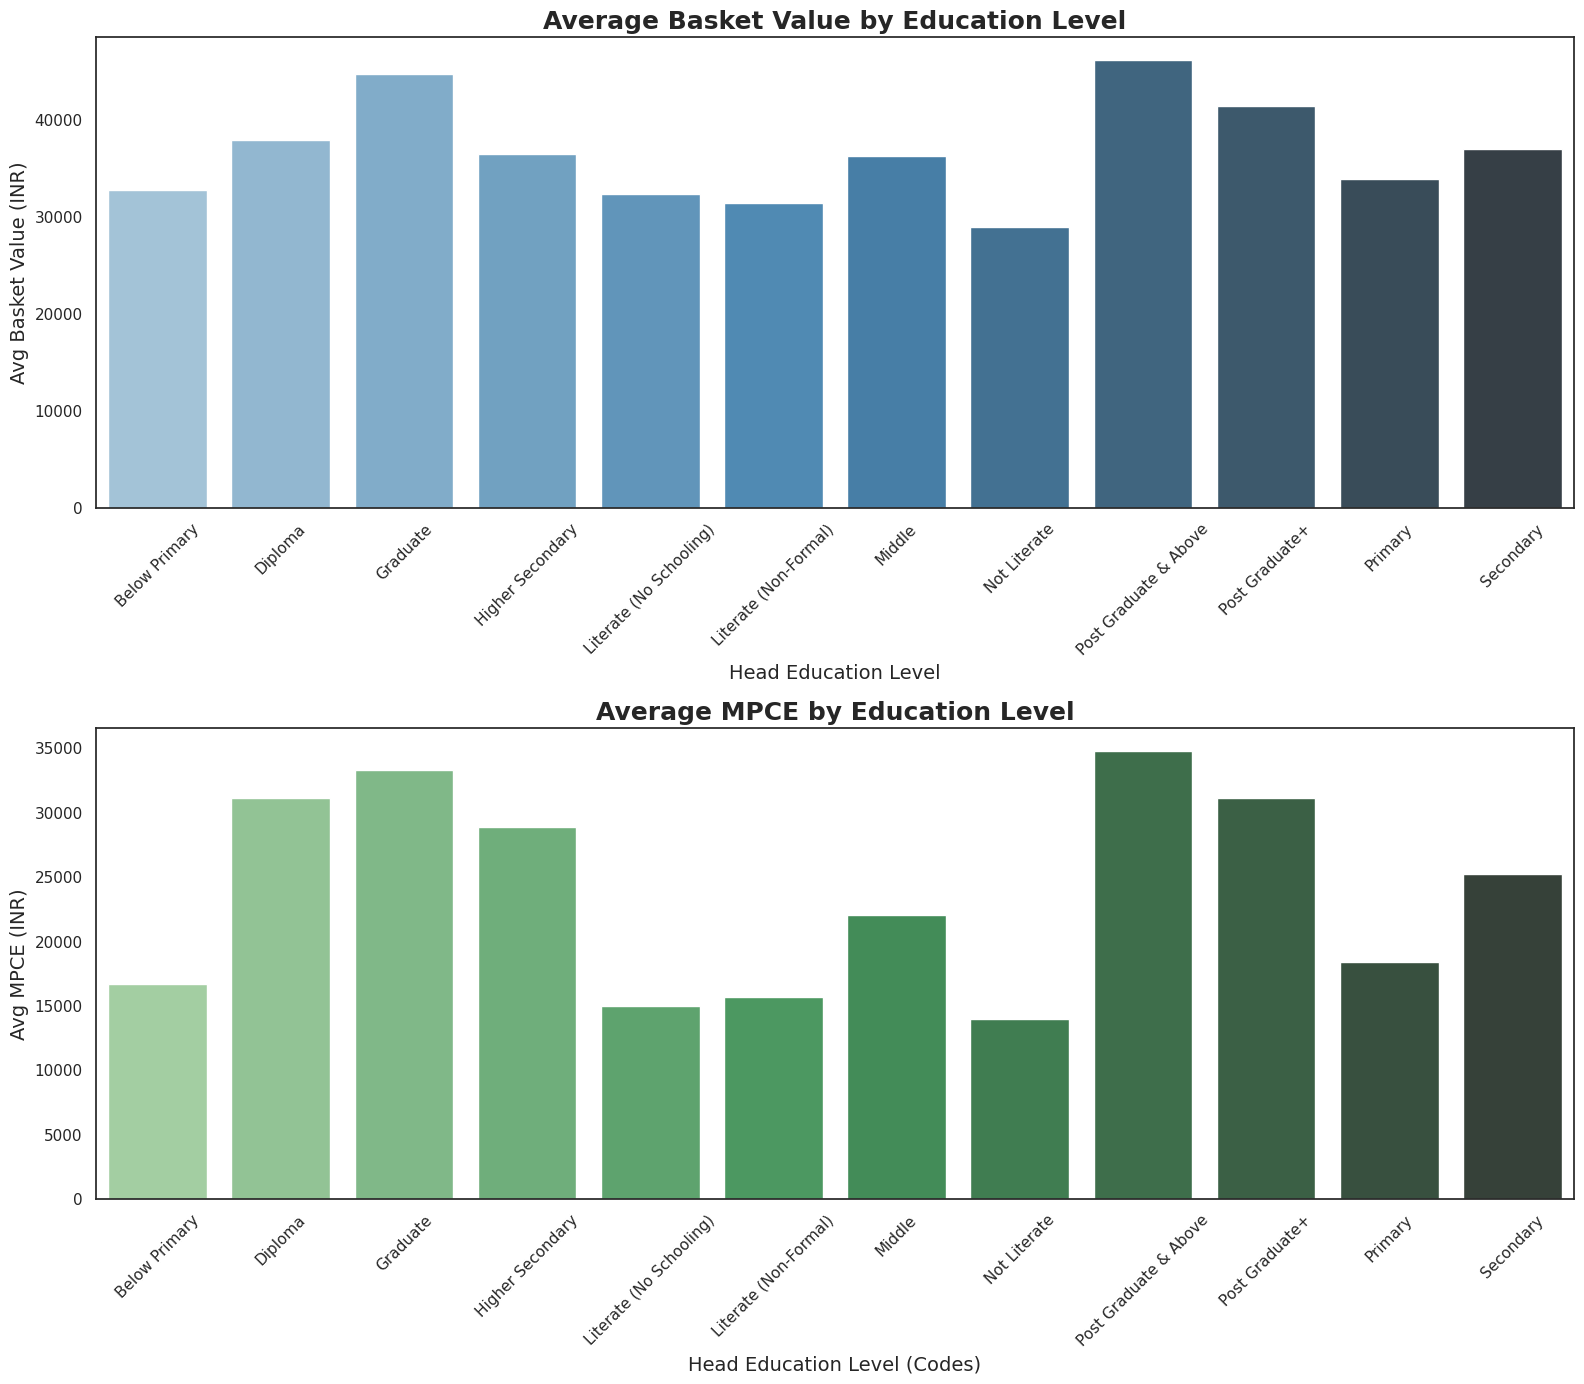

In [ ]:
# 2. Aggregate the data by head_education_level for overall metrics
# This removes the Sector (Rural/Urban) segmentation
overall_stats = df2.groupby('head_education_level')[['total_basket_value', 'MPCE']].mean().reset_index()
overall_stats = overall_stats.sort_values('head_education_level')

# 3. Create the figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 14))

# Chart 1: Overall Average Basket Value by Education Level
sns.barplot(data=overall_stats, x='head_education_level', y='total_basket_value',
            palette='Blues_d', ax=ax1)
ax1.set_title('Average Basket Value by Education Level', fontsize=18, fontweight='bold')
ax1.set_xlabel('Head Education Level', fontsize=14)
ax1.set_ylabel('Avg Basket Value (INR)', fontsize=14)
ax1.tick_params(axis='x',rotation = 45)

# Chart 2: Overall Average MPCE by Education Level
sns.barplot(data=overall_stats, x='head_education_level', y='MPCE',
            palette='Greens_d', ax=ax2)
ax2.set_title('Average MPCE by Education Level', fontsize=18, fontweight='bold')
ax2.set_xlabel('Head Education Level (Codes)', fontsize=14)
ax2.set_ylabel('Avg MPCE (INR)', fontsize=14)
ax2.tick_params(axis='x',rotation = 45)

# 4. Save and display
plt.tight_layout()

**Inferences**

- It is very evidently visible higher the education higher the basket value and mpce this indicates that education is the primary driver for high clv.

- Another observation is that the lower educated households have higher basket value which suggests that these are frequent buyers of low marginal products.

**Gender wise Basket and MPCE Value**

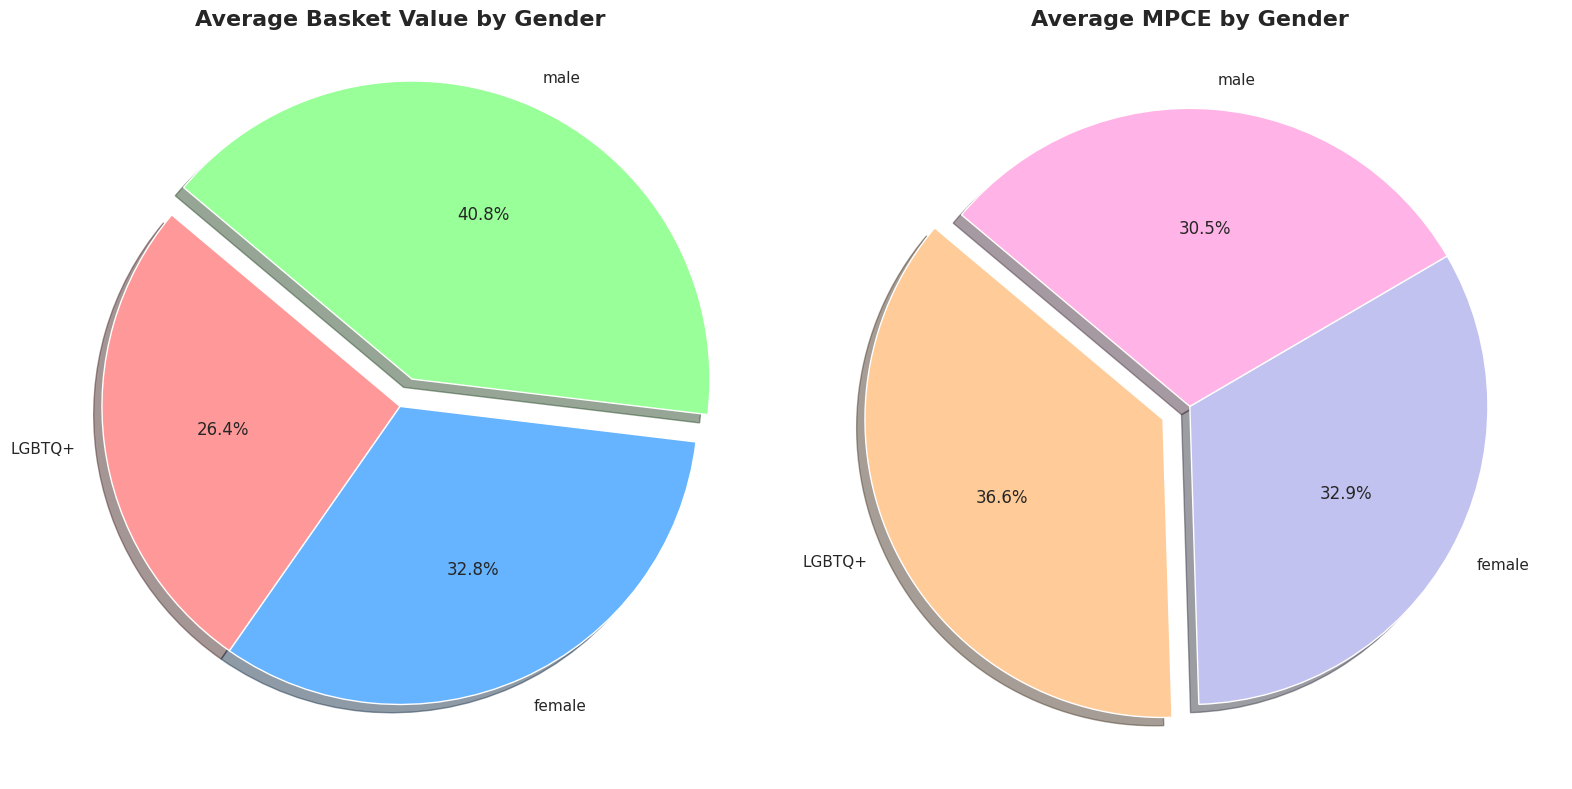

In [ ]:
basket_gender = df2.groupby('head_gender')['total_basket_value'].mean().reset_index()
mpce_gender = df2.groupby('head_gender')['MPCE'].mean().reset_index()

# 3. Create Subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Function to explode the maximum slice
def get_explode(values):
    return [0.1 if v == values.max() else 0 for v in values]

# Pie 1: Gender vs Total Basket Value (Sum)
axes[0].pie(basket_gender['total_basket_value'], labels=basket_gender['head_gender'],
            autopct='%1.1f%%', startangle=140,
            explode=get_explode(basket_gender['total_basket_value']),
            shadow=True, colors=['#ff9999','#66b3ff','#99ff99'])
axes[0].set_title('Average Basket Value by Gender', fontsize=16, fontweight='bold')

# Pie 2: Gender vs MPCE (Average)
axes[1].pie(mpce_gender['MPCE'], labels=mpce_gender['head_gender'],
            autopct='%1.1f%%', startangle=140,
            explode=get_explode(mpce_gender['MPCE']),
            shadow=True, colors=['#ffcc99','#c2c2f0','#ffb3e6'])
axes[1].set_title('Average MPCE by Gender', fontsize=16, fontweight='bold')

plt.tight_layout()

**Inferences**

- In the consumer market male have dominated the market with high spending ratio regardless of expenditure less on per person.

- While the the female market is a balanced market with high spending ratio and high expenditures per person, deriving a potential growth market than males in future.

- The other gender does have a low spending market ratio but high expenditure ratio per person indicating these genders are high value customer segment.

**Gender Wise Consumer Goods Expenditure**

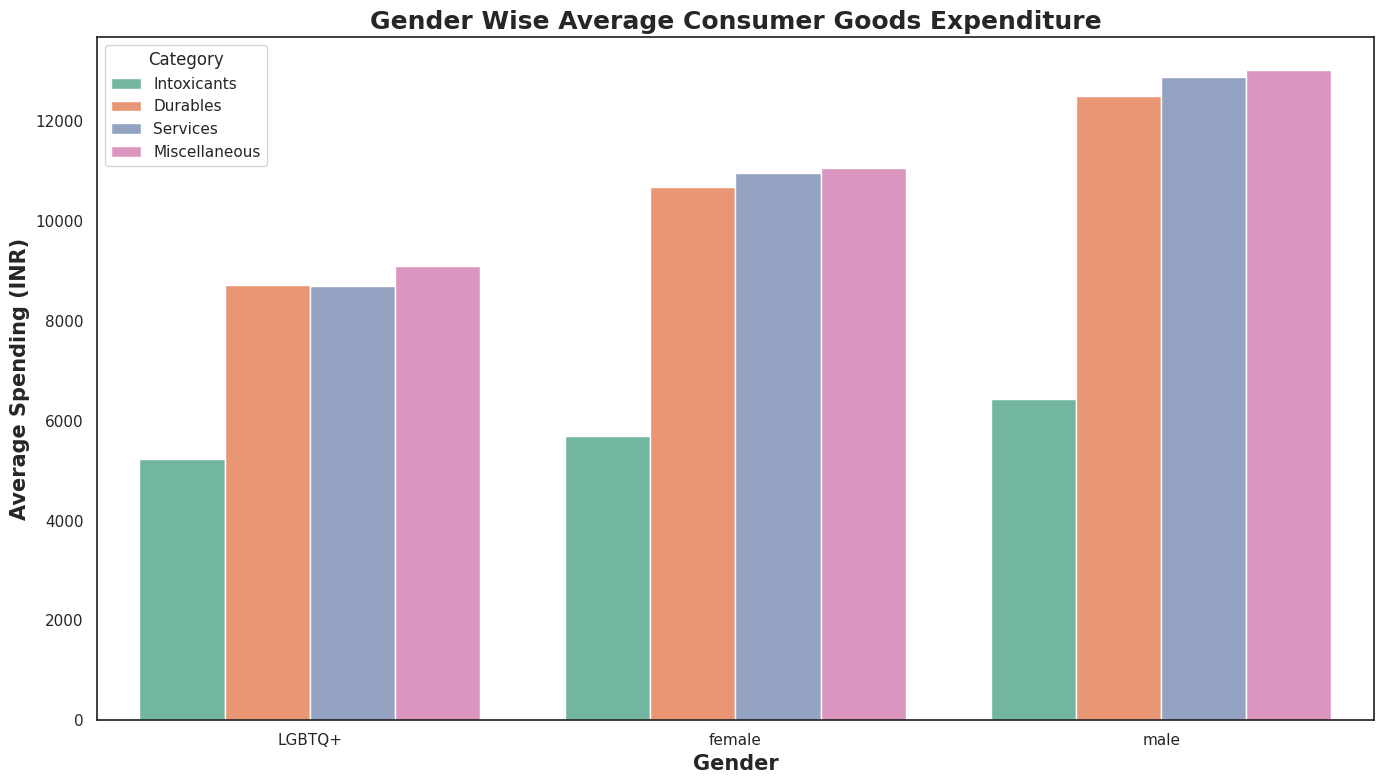

In [ ]:
# Mapping categories for the chart
categories_map = {
    'intoxicant_spend': 'Intoxicants',
    'Monthly_Durable_Expenditure': 'Durables',
    'Monthly_Services_Expenditure': 'Services',
    'Monthly_Misc_Expenditure': 'Miscellaneous'
}

# Grouping data and creating a clustered view
gender_exp = df2.groupby('head_gender')[list(categories_map.keys())].mean().reset_index()
melted_gender = gender_exp.melt(id_vars='head_gender', var_name='Category_Key', value_name='Average_Spending')
melted_gender['Category'] = melted_gender['Category_Key'].map(categories_map)

# Plotting
plt.figure(figsize=(14, 8))
ax = sns.barplot(data=melted_gender, x='head_gender', y='Average_Spending', hue='Category', palette='Set2')
ax.set_title('Gender Wise Average Consumer Goods Expenditure', fontsize=18, fontweight='bold')
plt.xlabel('Gender', fontsize=15, fontweight='bold')
plt.ylabel('Average Spending (INR)', fontsize=15, fontweight='bold')
plt.legend(title='Category')
plt.tight_layout()
plt.show()

**Inferences**

- The expenditure ration on goods for male and female ratio is almost similiar with highest expenditures on misc items.

- Males spend higher on intoxicants compared to other genders with lbtq+ being the lowest market expansion due to lack of population.

**MPCE based on online and asset score**

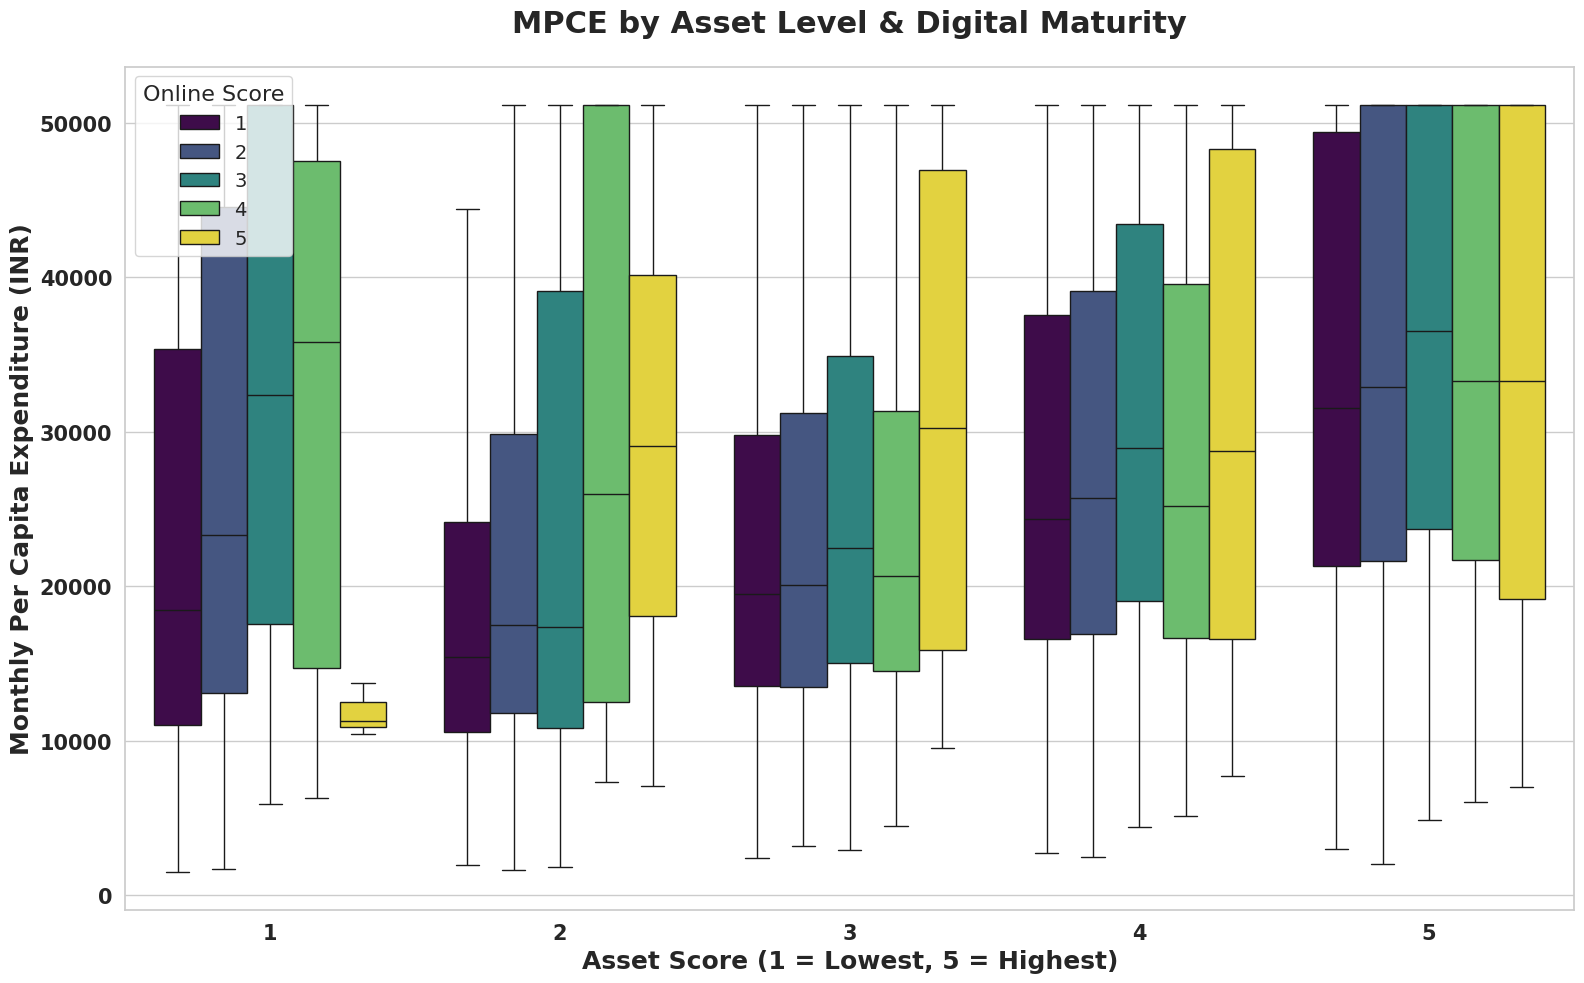

In [ ]:
# 2. Data Preparation
# Ensure spending is numeric and scores are limited to 1-5 range
df2['MPCE'] = pd.to_numeric(df2['MPCE'], errors='coerce')
df2 = df2[df2['asset_score'].between(1, 5) & df2['online_score'].between(1, 5)]

# 3. Create the Grouped Box Plot
plt.figure(figsize=(16, 10))
sns.set_theme(style="whitegrid")

# We use 'showfliers=False' to focus on the interquartile range (IQR)
# and prevent extreme outliers from squashing the visual boxes.
plot = sns.boxplot(
    data=df2,
    x='asset_score',
    y='MPCE',
    hue='online_score',
    palette='viridis',
    showfliers=False
)

# 4. Customization for Dissertation Quality
plt.title('MPCE by Asset Level & Digital Maturity',
          fontsize=22, fontweight='bold', pad=25)
plt.ylabel('Monthly Per Capita Expenditure (INR)', fontsize=18, fontweight='bold')
plt.xlabel('Asset Score (1 = Lowest, 5 = Highest)', fontsize=18, fontweight='bold')
plt.legend(title='Online Score', title_fontsize='16', fontsize='14', loc='upper left')

# Tick formatting for better readability
plt.xticks(fontsize=15, fontweight='bold')
plt.yticks(fontsize=15, fontweight='bold')

plt.tight_layout()

**Inferences**

- the graph describes even with  low asset score if the households are digitally equipped the expenditure on the asset score has more impact leading to increase in purchases.

- we also observe houseolds with an online score between 2-4 have higher expenditure and are most valuable customers.


**House hold Type Average basket and Mpce Value**

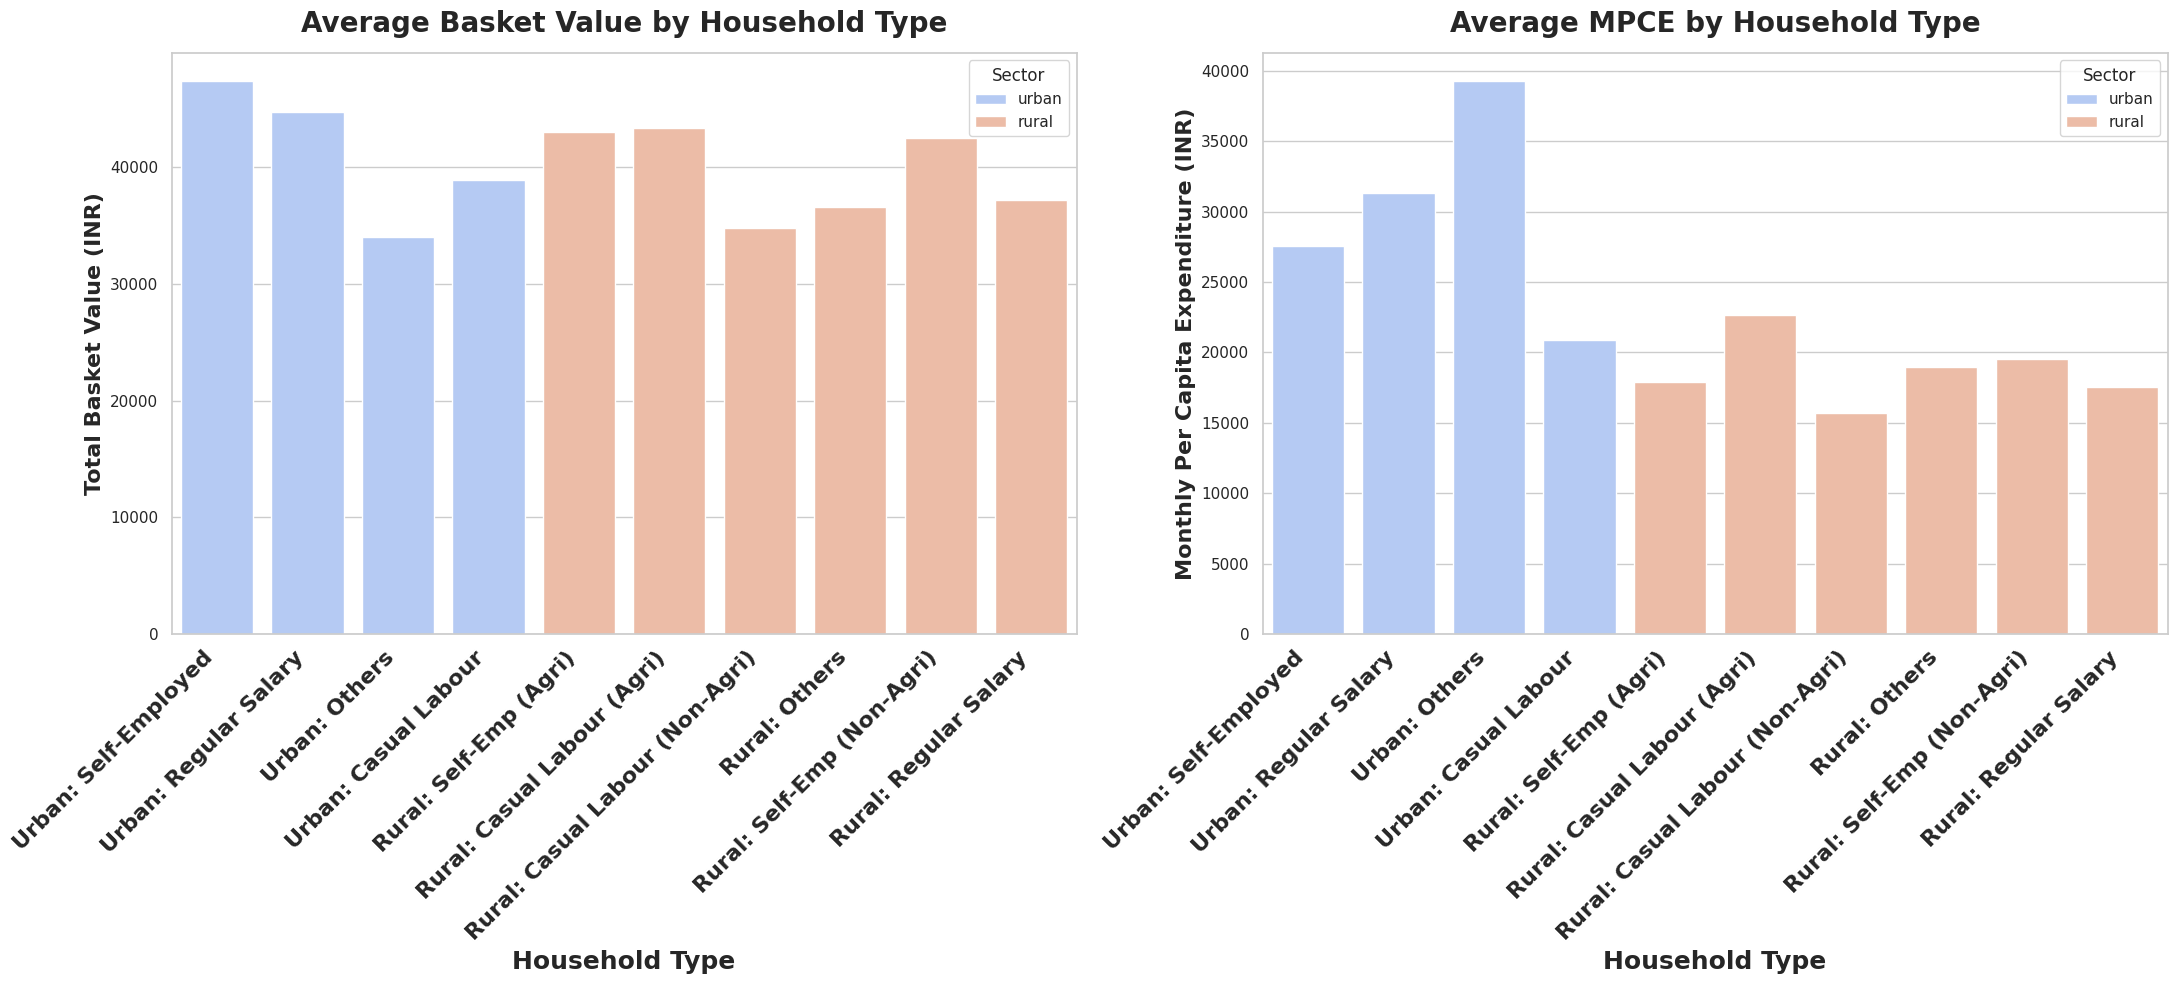

In [ ]:
# 3. Initialize Subplots (1 Row, 2 Columns)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(22, 10))

# --- Plot 1: Average Basket Value ---
sns.barplot(
    data=df2,
    x='Household_Type',
    y='total_basket_value',
    hue='Sector',
    ax=axes[0],
    palette='coolwarm',
    errorbar=None
)
axes[0].set_title('Average Basket Value by Household Type', fontsize=20, fontweight='bold', pad=15)
axes[0].set_ylabel('Total Basket Value (INR)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Household Type', fontsize=18, fontweight='bold')

# UPDATED: Bold and larger font for X-axis labels (Household Types)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right',
                         fontsize=16, fontweight='bold')

# --- Plot 2: Average MPCE ---
sns.barplot(
    data=df2,
    x='Household_Type',
    y='MPCE',
    hue='Sector',
    ax=axes[1],
    palette='coolwarm',
    errorbar=None
)
axes[1].set_title('Average MPCE by Household Type', fontsize=20, fontweight='bold', pad=15)
axes[1].set_ylabel('Monthly Per Capita Expenditure (INR)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Household Type', fontsize=18, fontweight='bold')

# UPDATED: Bold and larger font for X-axis labels (Household Types)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right',
                         fontsize=16, fontweight='bold')

# 4. Final Formatting
plt.tight_layout()
plt.show()

**Inferences**
- In the urban areas households with occupation as business,salaried employees and labours have higher spend ratio while in rural households with agriculture as business and labours have the highest spend ratio.

- In the urban areas urban households with other occupation have the highest family expenditures comparatively other occupation generally these people are rentiers or interest/ dividend earners with a single or nuclear family size.

- Comparison to rural and Urban, Urban households have high buying ratio and nuclear family households which indicate that most of the products purchased are luxury needs while in rural households have high expenditure ratio and huge family size which indicates most of their purchases are basic needs and only important for survival.


**Top 5 Household Types Expenditure By Goods**

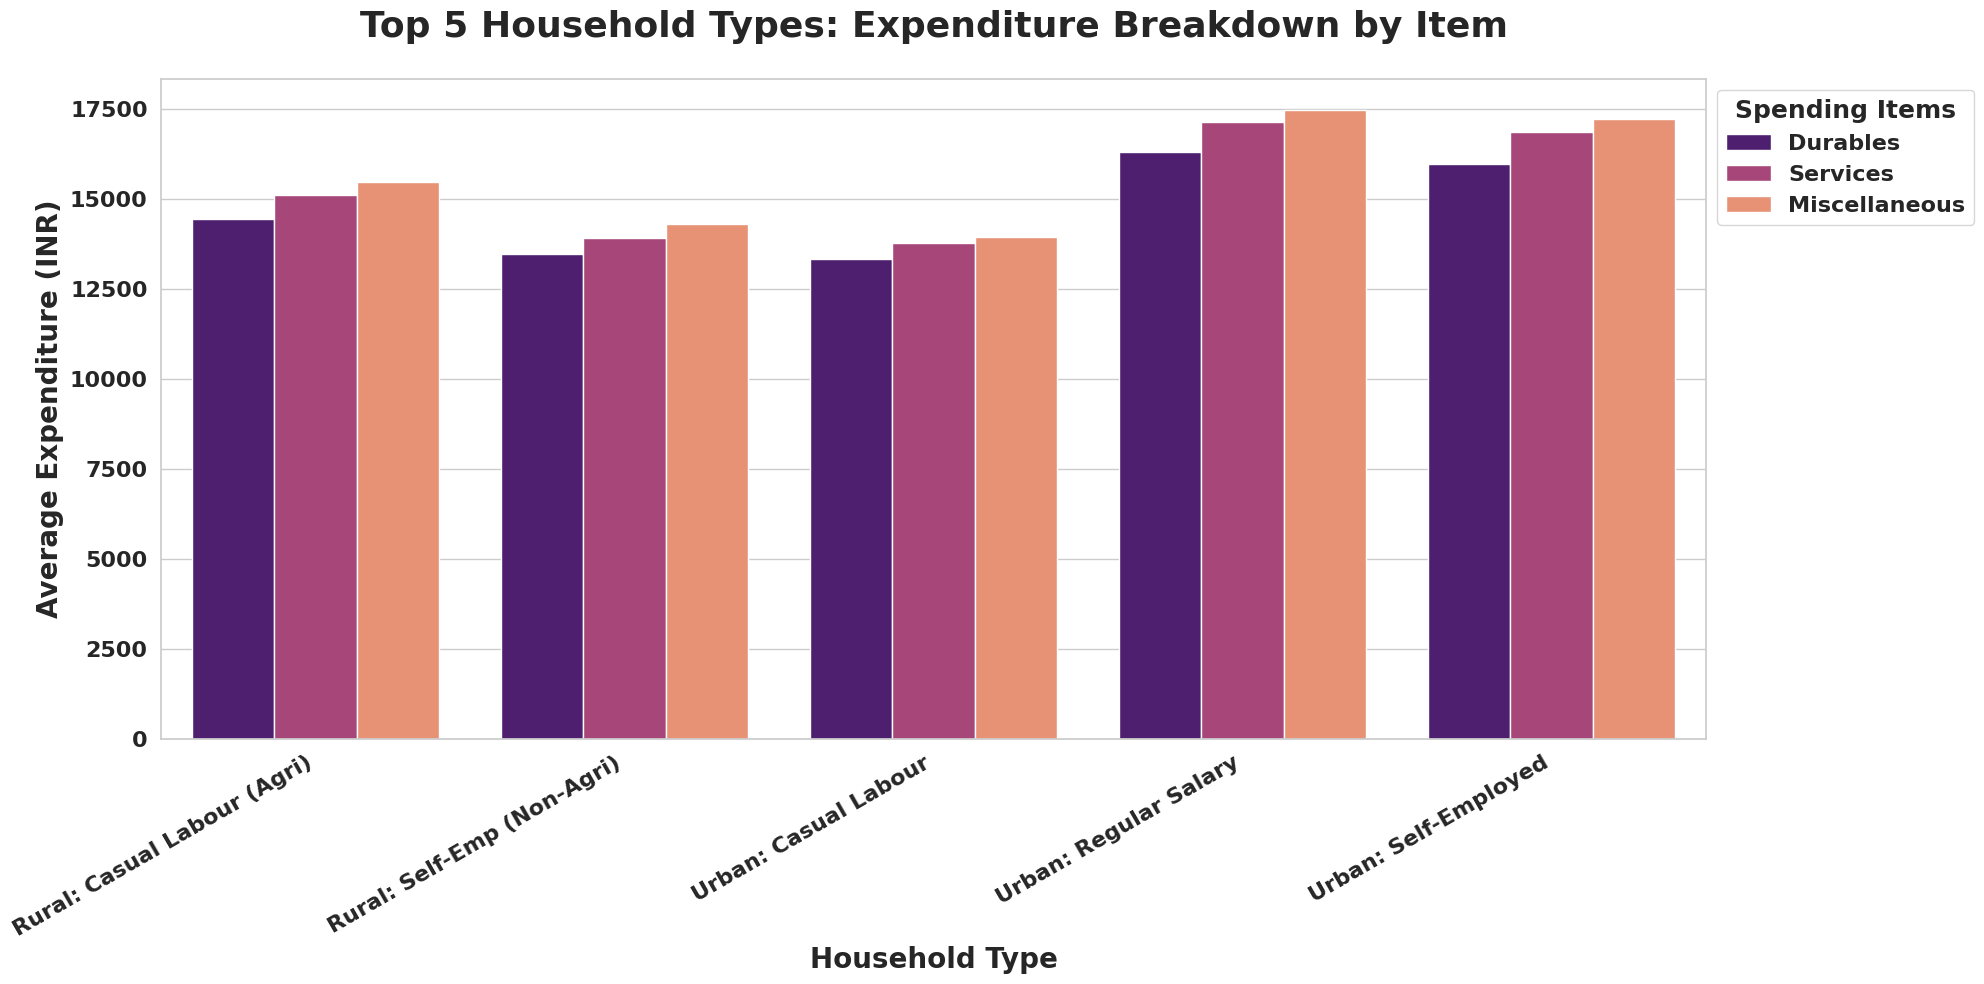

In [ ]:
# 1. Setting professional style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.weight': 'bold', 'axes.labelweight': 'bold'})

# 2. Define the individual spending items
item_cols = {
    'Monthly_Durable_Expenditure': 'Durables',
    'Monthly_Services_Expenditure': 'Services',
    'Monthly_Misc_Expenditure': 'Miscellaneous'
}

# 3. Use item_total as a temporary variable to find the Top 5 Household Types
# We calculate the sum across columns 1, 2, and 3 to determine the "Top 5" earners/spenders
temp_ranking = df2.groupby('Household_Type')[list(item_cols.keys())].mean().mean(axis=1)
top_5_types = temp_ranking.sort_values(ascending=False).head(5).index

# 4. Filter and aggregate only the individual items
plot_data = df2[df2['Household_Type'].isin(top_5_types)].groupby('Household_Type').agg({
    'Monthly_Durable_Expenditure': 'mean',
    'Monthly_Services_Expenditure': 'mean',
    'Monthly_Misc_Expenditure': 'mean'
}).reset_index()

# Rename for legend clarity
plot_data = plot_data.rename(columns=item_cols)

# 5. Melt data for grouped bar chart (only contains Durables, Services, Miscellaneous)
df_melted = plot_data.melt(id_vars='Household_Type', var_name='Items', value_name='Average Expenditure')

# 6. Create the Visualization
plt.figure(figsize=(20, 10))
bar_plot = sns.barplot(
    data=df_melted,
    x='Household_Type',
    y='Average Expenditure',
    hue='Items',
    palette='magma'
)

# 7. Large Bold Formatting
plt.title('Top 5 Household Types: Expenditure Breakdown by Item', fontsize=26, fontweight='bold', pad=30)
plt.ylabel('Average Expenditure (INR)', fontsize=20, fontweight='bold')
plt.xlabel('Household Type', fontsize=20, fontweight='bold')

# Bold and large X-axis tick labels
plt.xticks(fontsize=16, fontweight='bold', rotation=30, ha='right')
plt.yticks(fontsize=16, fontweight='bold')

# Legend styling
plt.legend(title='Spending Items', title_fontsize='18', fontsize='16', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

**Inferences**

- We observe that in the urban areas salaried employees and businessmen households are direct target consumers for the luxury goods.

- In the rural areas households that own lands for farming business and businessmen non agriculture are the direct target for luxury goods.

- regardless of rural or urban households generally have higher expenditure on miscellaneous items which indicates households choose comforts.

**Household Wise Basket And MPCE Plot**

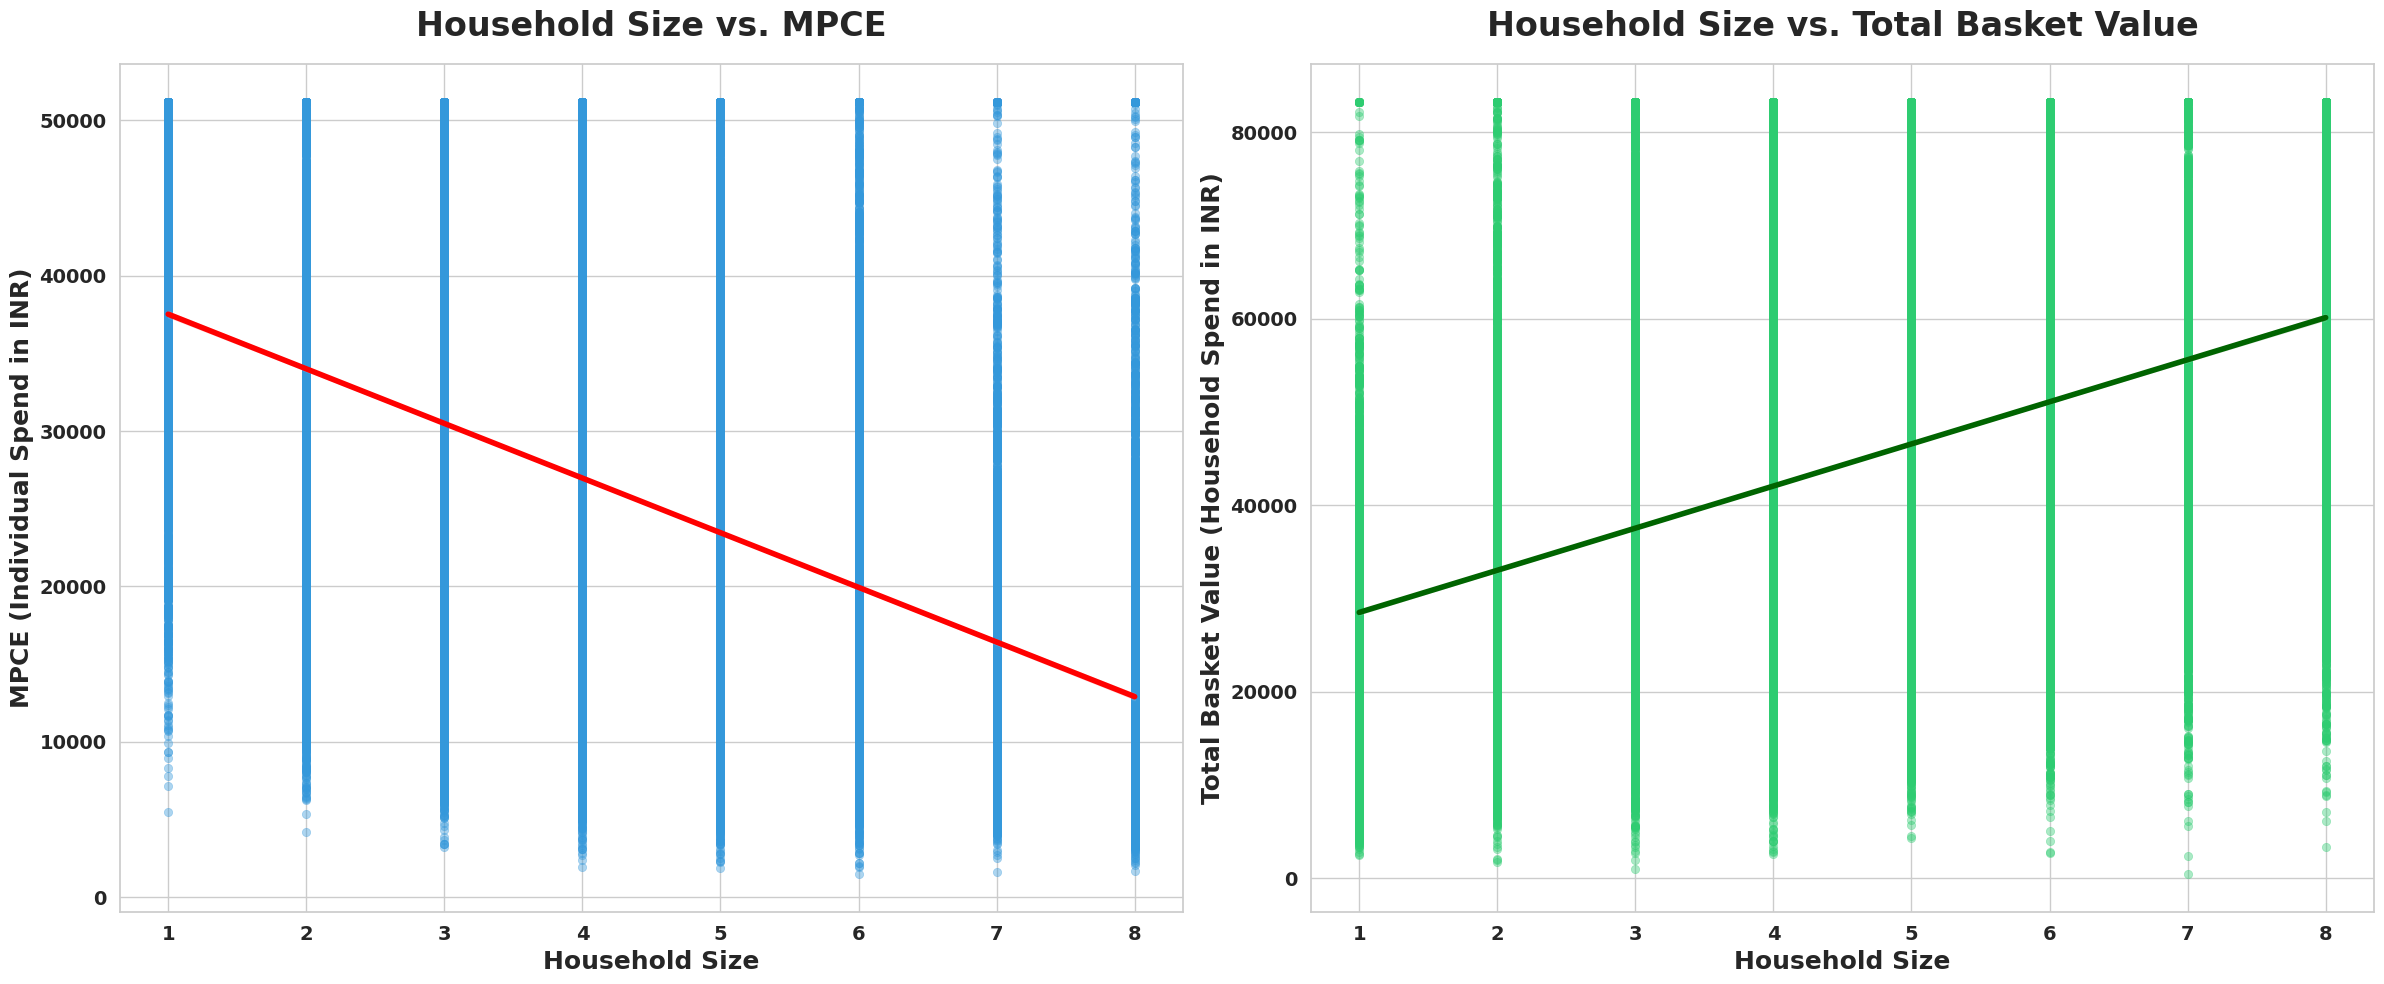

In [ ]:

# 1. Setting professional style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.weight': 'bold', 'axes.labelweight': 'bold'})

# 2. Initialize Subplots (1 Row, 2 Columns)
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

# --- Plot A: Household Size vs. MPCE ---
# This shows how individual spending power changes with family size
sns.scatterplot(
    data=df2,
    x='hh_size',
    y='MPCE',
    ax=axes[0],
    color='#3498db',
    alpha=0.4,
    edgecolor=None
)
sns.regplot(
    data=df2,
    x='hh_size',
    y='MPCE',
    scatter=False,
    ax=axes[0],
    color='red',
    line_kws={"linewidth": 4}
)
axes[0].set_title('Household Size vs. MPCE', fontsize=24, fontweight='bold', pad=20)
axes[0].set_ylabel('MPCE (Individual Spend in INR)', fontsize=18, fontweight='bold')
axes[0].set_xlabel('Household Size', fontsize=18, fontweight='bold')

# --- Plot B: Household Size vs. Total Basket Value ---
# This shows how the total shopping cart grows with family size
sns.scatterplot(
    data=df2,
    x='hh_size',
    y='total_basket_value',
    ax=axes[1],
    color='#2ecc71',
    alpha=0.4,
    edgecolor=None
)
sns.regplot(
    data=df2,
    x='hh_size',
    y='total_basket_value',
    scatter=False,
    ax=axes[1],
    color='darkgreen',
    line_kws={"linewidth": 4}
)
axes[1].set_title('Household Size vs. Total Basket Value', fontsize=24, fontweight='bold', pad=20)
axes[1].set_ylabel('Total Basket Value (Household Spend in INR)', fontsize=18, fontweight='bold')
axes[1].set_xlabel('Household Size', fontsize=18, fontweight='bold')

# 3. Global Formatting for both subplots
for ax in axes:
    ax.tick_params(labelsize=14)
    for label in (ax.get_xticklabels() + ax.get_yticklabels()):
        label.set_fontweight('bold')

plt.tight_layout()
plt.show()

**Inferences**
- According to the plots the nuclear families that is household size from 1-4 have high spending ratio but low basket value which describes that nuclear families are part of the premium market and major consumer of luxury goods.

- while the joint families or households that is size more than 5 members the spending ratio is lesser but high basket values, that describes belong to the mass market and are major consumer of low margin goods.

**Households Wise MPCE and Basket Value Plot**

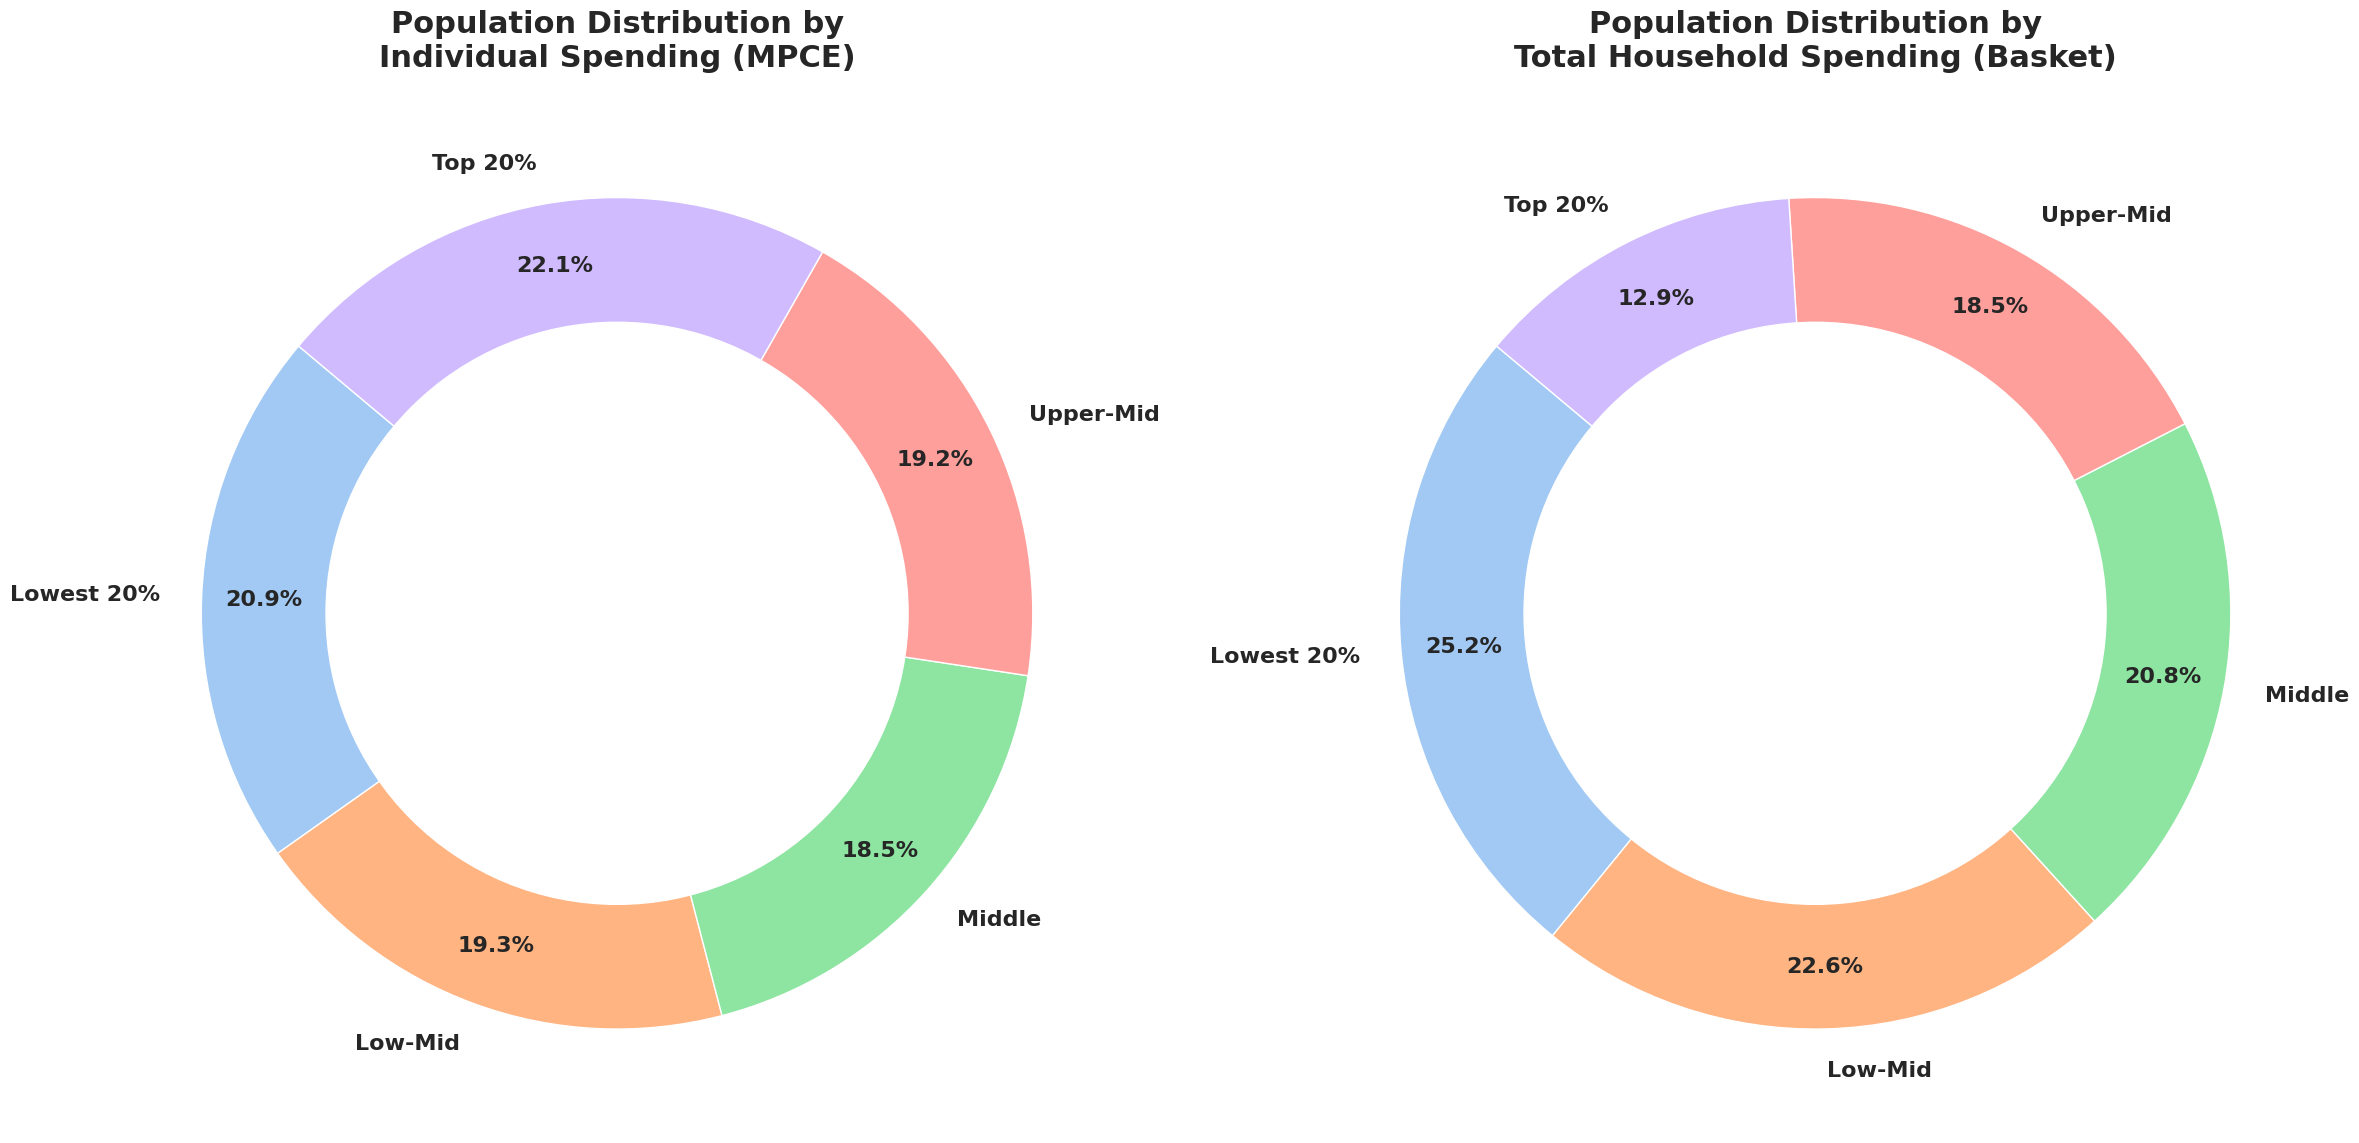

In [ ]:
# 1. Setting professional style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.weight': 'bold', 'axes.labelweight': 'bold'})

# 2. Creating Spending Groups (Quintiles) for both metrics
# This divides the data into 5 equal-sized groups from lowest to highest spenders
df2['mpce_group'] = pd.qcut(df2['MPCE'], 5,
                             labels=['Lowest 20%', 'Low-Mid', 'Middle', 'Upper-Mid', 'Top 20%'])

df2['basket_group'] = pd.qcut(df2['total_basket_value'], 5,
                               labels=['Lowest 20%', 'Low-Mid', 'Middle', 'Upper-Mid', 'Top 20%'])

# 3. Summing the Multiplier (Population Weight) for each group
mpce_pop = df2.groupby('mpce_group')['Multiplier'].sum()
basket_pop = df2.groupby('basket_group')['Multiplier'].sum()

# 4. Initialize Subplots (1 Row, 2 Columns)
fig, axes = plt.subplots(1, 2, figsize=(24, 12))
colors = sns.color_palette('pastel')[0:5]

# --- Chart 1: MPCE Population Distribution ---
axes[0].pie(
    mpce_pop, labels=mpce_pop.index, autopct='%1.1f%%',
    startangle=140, colors=colors, pctdistance=0.85,
    textprops={'fontsize': 16, 'fontweight': 'bold'}
)
# Make it a donut
axes[0].add_artist(plt.Circle((0,0), 0.70, fc='white'))
axes[0].set_title('Population Distribution by\nIndividual Spending (MPCE)',
                  fontsize=22, fontweight='bold', pad=20)

# --- Chart 2: Basket Value Population Distribution ---
axes[1].pie(
    basket_pop, labels=basket_pop.index, autopct='%1.1f%%',
    startangle=140, colors=colors, pctdistance=0.85,
    textprops={'fontsize': 16, 'fontweight': 'bold'}
)
# Make it a donut
axes[1].add_artist(plt.Circle((0,0), 0.70, fc='white'))
axes[1].set_title('Population Distribution by\nTotal Household Spending (Basket)',
                  fontsize=22, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

**Inferences**
- We observe that our data is uniformly distributed with similiar households which avoids any biased prediction for the model.

- The lower-mid,middle and upper middle have merely close distribution of mpce and basket forming the largest concentration about 60% for low margin products and also a whale market.

- The plot also indicates that most of the households fall into the whale market with different perspectives of luxury.

In [ ]:
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,mpce_group,basket_group
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,Upper-Mid,Low-Mid
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,Upper-Mid,Top 20%
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,Top 20%,Top 20%
7,22300_3_11,Puducherry,urban,2,28599,4,56,male,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,Upper-Mid,Middle
8,22300_3_12,Puducherry,urban,2,28599,6,69,male,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,Upper-Mid,Middle


In [ ]:
#calculating CLVt for next year
# 2. Define the rates found in your data
# These are the components of your 10% Discount Rate
risk_free_rate = 0.067  # 6.7%
risk_premium = 0.02     # 2.0%
inflation = 0.013       # 1.3%

total_discount_rate = risk_free_rate + risk_premium + inflation # 0.10 or 10%

# 2. Calculate CLVT using the Multi-Year Annuity Formula
# This assumes your column is named 'Expected_Remaining_Years'
r = total_discount_rate
n = df2['expected_remaining_years']
annual_spend = df2['MPCE'] * 12

# 3. Calculate clvt
# Formula for customer lifetime value for remaining years
df2['clvt'] = annual_spend *((1-(1+r)**-n)/r)
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,mpce_group,basket_group,clvt
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,Upper-Mid,Low-Mid,3935654.17
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,Upper-Mid,Top 20%,3777561.90
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,Top 20%,Top 20%,5700629.36
7,22300_3_11,Puducherry,urban,2,28599,4,56,male,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,Upper-Mid,Middle,3419429.36
8,22300_3_12,Puducherry,urban,2,28599,6,69,male,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,Upper-Mid,Middle,2776065.40


**Calculating CLVT**

CLVT = Annual Spend * [(1 -(1+r)^-n)/r)]

Annual Spend = MPCE * 12

r = Discount Ratios
- Risk-Free Rate: 6.70 %
- Risk-Premium: 2.00 %
- Inflation: 1.30 %

n = Expected Remaining Years

Formula derived From Modern Portfolio theory and Time Value of Money Formalized later By Irving fisher Later applied to marketing By Peter fader and Bruce Hardie.

In [ ]:
#print the avg, max and min clvt
print("Average CLVT:", df2['clvt'].mean())
print("Maximum CLVT:", df2['clvt'].max())
print("Minimum CLVT:", df2['clvt'].min())

Average CLVT: 2830562.5947702574
Maximum CLVT: 6103608.957854877
Minimum CLVT: 123492.64750071564


In [ ]:
#export to csv
df2.to_csv('clvt.csv', index=False)

In [ ]:
#labeling the clvt
df2['clvt_label'] = pd.cut(df2['clvt'],
                           bins=[0, 1000000, 3000000, 5000000, np.inf],
                           labels=['Price Sensitive Asset','Budgeted Asset','Emerging Asset','High Value Asset'])
df2.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,mpce_group,basket_group,clvt,clvt_label
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,Upper-Mid,Low-Mid,3935654.17,Emerging Asset
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,Upper-Mid,Top 20%,3777561.90,Emerging Asset
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,Top 20%,Top 20%,5700629.36,High Value Asset
7,22300_3_11,Puducherry,urban,2,28599,4,56,male,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,Upper-Mid,Middle,3419429.36,Emerging Asset
8,22300_3_12,Puducherry,urban,2,28599,6,69,male,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,Upper-Mid,Middle,2776065.40,Budgeted Asset


**CLVT Distribution Chart By Region**

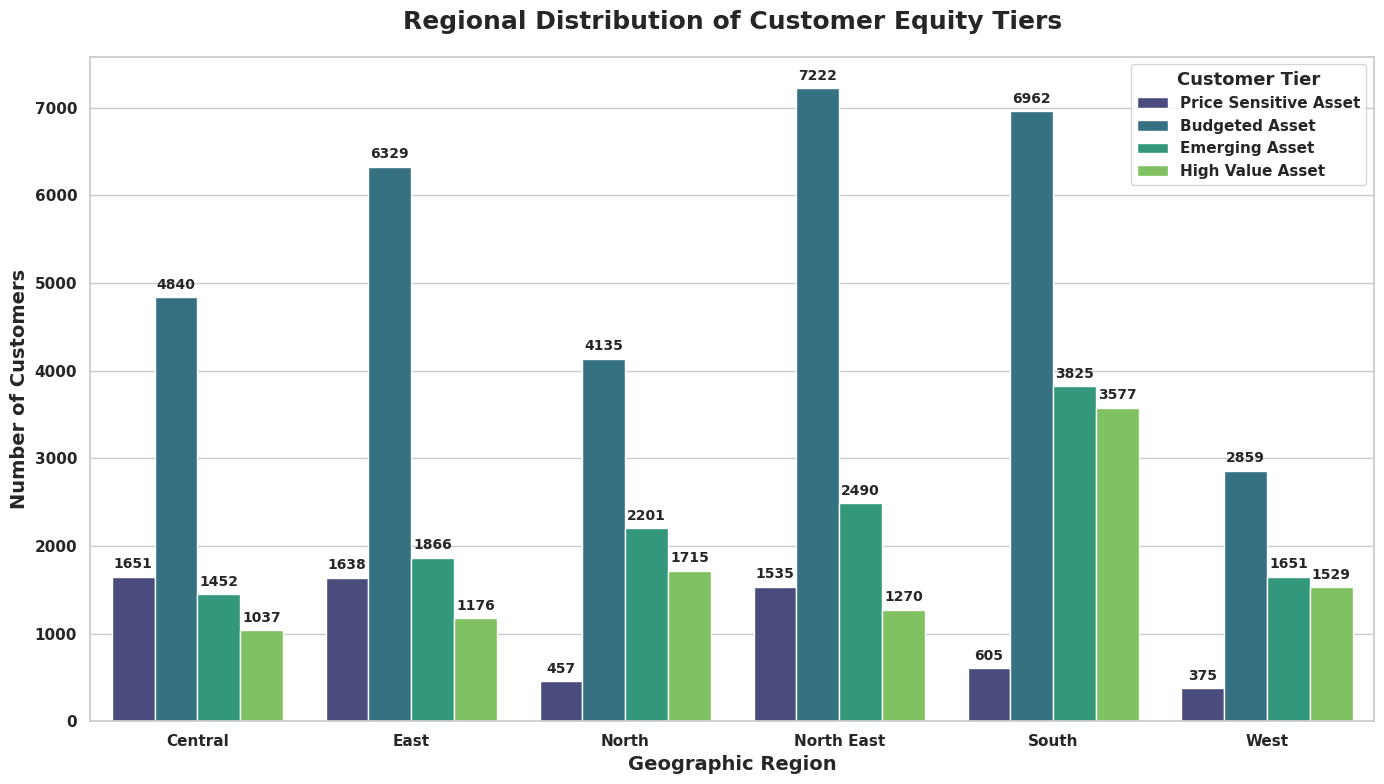

In [ ]:

# 2. Prepare Data for Clustered Chart
chart_data = df2.groupby(['Region', 'clvt_label'], observed=False).size().reset_index(name='Customer_Count')

# 3. Generate Visualization
plt.figure(figsize=(14, 8))
sns.set_style("whitegrid")

# Create Clustered Bar Plot
ax = sns.barplot(
    data=chart_data,
    x='Region',
    y='Customer_Count',
    hue='clvt_label',
    palette='viridis'
)

# 4. Enhance Chart Professionalism & Fix Legend
plt.title('Regional Distribution of Customer Equity Tiers', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Geographic Region', fontsize=14)
plt.ylabel('Number of Customers', fontsize=14)

# FIX: Explicitly get handles and labels to ensure only the 4 categories appear
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles=handles, labels=labels, title='Customer Tier',
           title_fontsize='13', fontsize='11', loc='upper right')

# Add data labels on top of each bar
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(format(p.get_height(), '.0f'),
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha = 'center', va = 'center',
                    xytext = (0, 9),
                    textcoords = 'offset points',
                    fontsize=10,
                    fontweight='semibold')

plt.tight_layout()
plt.show()

**Inferences**

- In the given clustered chart we can observe that from all over India consumers fall into the segments Budgeted and Emerging tiers which indicate that Middle and Upper middle class comprisse the most of population.

- South Region has the highest High asset value consumers with West region having the lowest price sensitive customers and Central region with highest price sensitive customers.

**Region Wise Heatmap Expenditure on Durables Based On ClVT Labels**

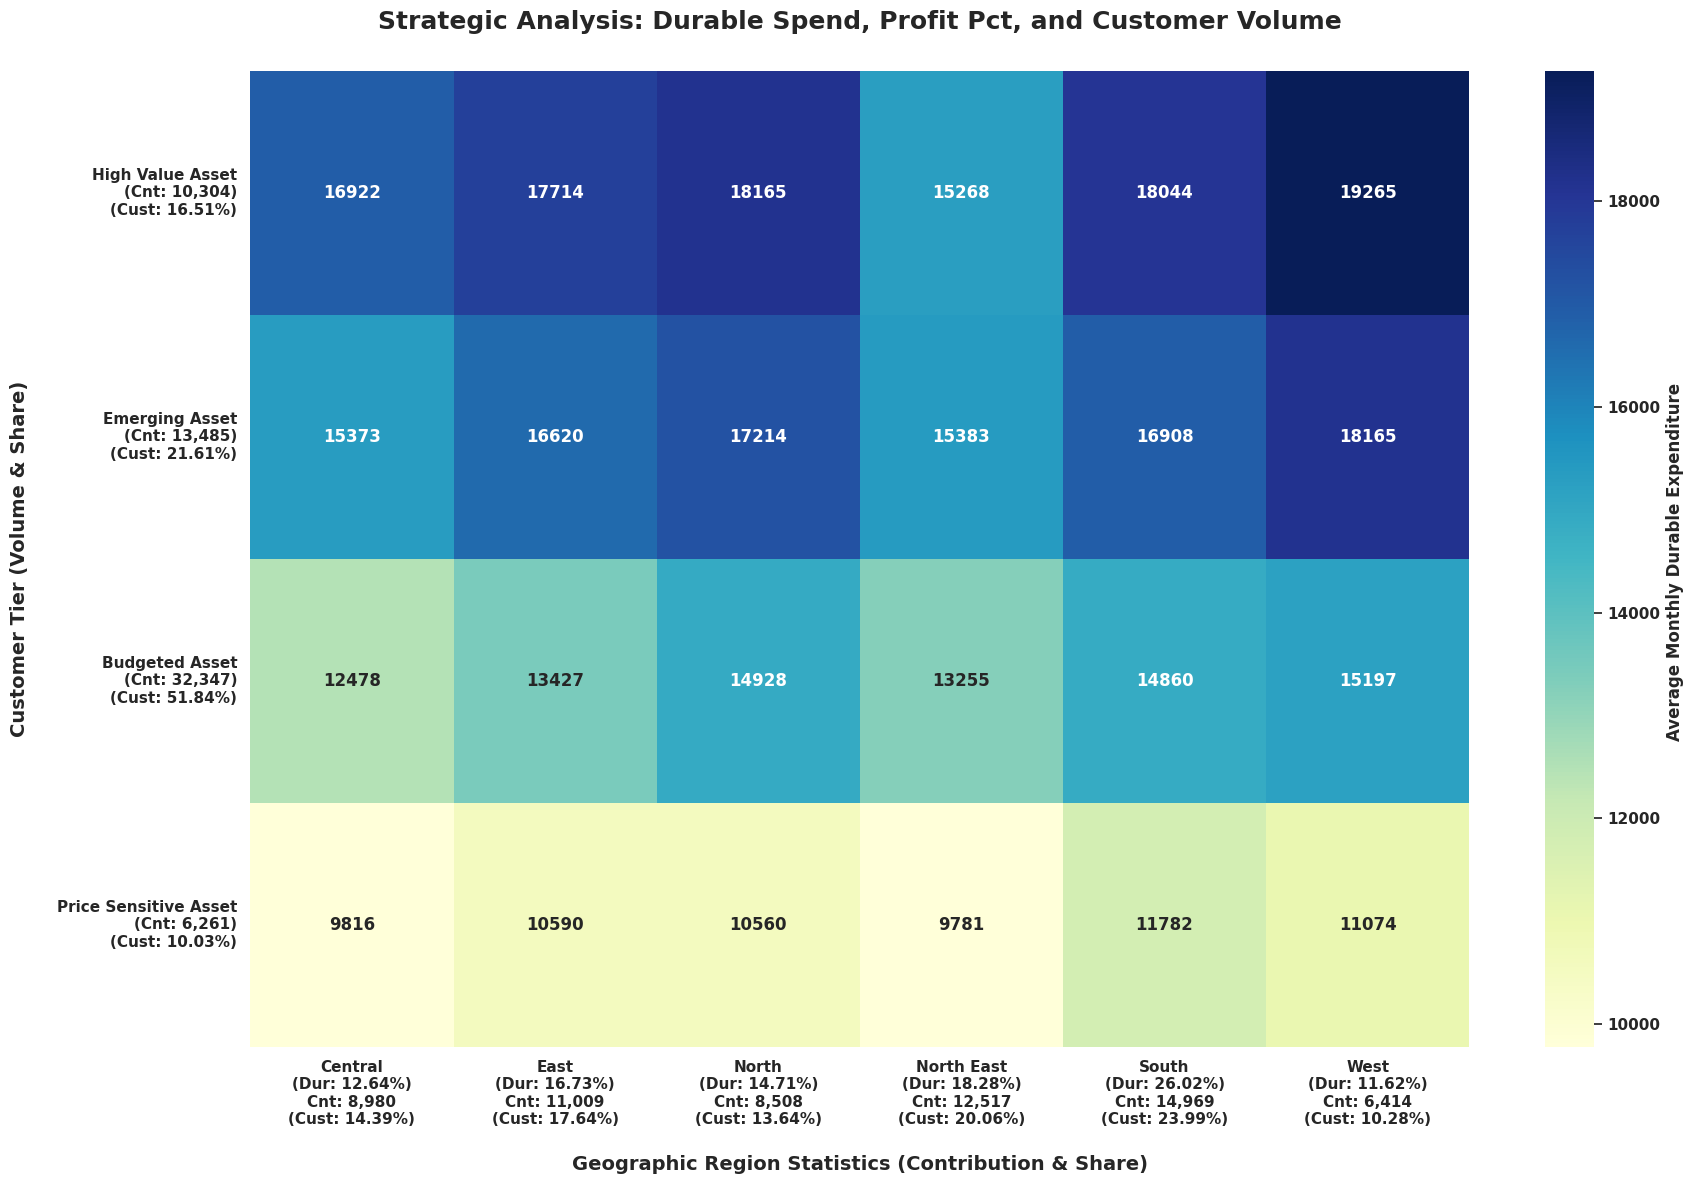

In [ ]:
# 1. Calculate Strategic Metrics for Regional Labels
total_durable_spend = df2['Monthly_Durable_Expenditure'].sum()
region_durable_spend = df2.groupby('Region')['Monthly_Durable_Expenditure'].sum()
profit_pct = (region_durable_spend / total_durable_spend) * 100

total_customers = len(df2)
region_counts = df2.groupby('Region').size()
cust_base_pct = (region_counts / total_customers) * 100

# Create Multi-line Region Labels for the X-axis
region_labels_expanded = {
    region: f"{region}\n(Dur: {profit_pct[region]:.2f}%)\nCnt: {region_counts[region]:,}\n(Cust: {cust_base_pct[region]:.2f}%)"
    for region in profit_pct.index
}

# 2. Calculate Strategic Metrics for Tier Labels (Y-Axis)
tier_counts = df2['clvt_label'].value_counts()
tier_cust_pct = (tier_counts / total_customers) * 100

# Create Multi-line Tier Labels (adding Count and % to the names)
prof_labels = ['Price Sensitive Asset', 'Budgeted Asset', 'Emerging Asset', 'High Value Asset']
tier_labels_expanded = {
    tier: f"{tier}\n(Cnt: {tier_counts[tier]:,})\n(Cust: {tier_cust_pct[tier]:.2f}%)"
    for tier in prof_labels
}

# 3. Prepare Heatmap Data
# Assign expanded labels to the dataframe for plotting
df2['Region_Display'] = df2['Region'].map(region_labels_expanded)
df2['Tier_Display'] = df2['clvt_label'].map(tier_labels_expanded)

heatmap_data = df2.pivot_table(
    index='Tier_Display',
    columns='Region_Display',
    values='Monthly_Durable_Expenditure',
    aggfunc='mean'
)

# Reorder tiers (High Value at the top) using the expanded strings
reorder_list = [tier_labels_expanded[tier] for tier in reversed(prof_labels)]
heatmap_data = heatmap_data.reindex(reorder_list)

# 4. Generate Visualization
plt.figure(figsize=(18, 12))
sns.heatmap(
    heatmap_data,
    annot=True,        # Average spend in cells
    fmt=".0f",         # Whole numbers
    cmap="YlGnBu",
    cbar_kws={'label': 'Average Monthly Durable Expenditure '}
)

plt.title('Strategic Analysis: Durable Spend, Profit Pct, and Customer Volume', fontsize=18, fontweight='bold', pad=30)
plt.ylabel('Customer Tier (Volume & Share)', fontsize=14, labelpad=20)
plt.xlabel('Geographic Region Statistics (Contribution & Share)', fontsize=14, labelpad=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Inferences**
- For durables most of the consumers are inbetween the emerging and high value assets with West and North dominating with most profitable markets.

- The Central and North East region represent the lowest expenditure on chart suggesting that the market is saturated.

- There is marginal difference between price sensitive and Budgeted asset consumers, indicating a slight discounted reward system can lead to substantial revenue growth.

- The West Region having the highest expenditure margin on durable still has lower contribution margin comapred to south at 26% due to lower number of price sensitive customers, this indicates the South region is the best market for the business.

- Since the price sensitive customers make an impact on the contribution percentage in the durables market any durable item less than or equal to a lakh must be discounted to generate volume.

**Region Wise Heatmap Expenditure on Services Based On ClVT Labels**

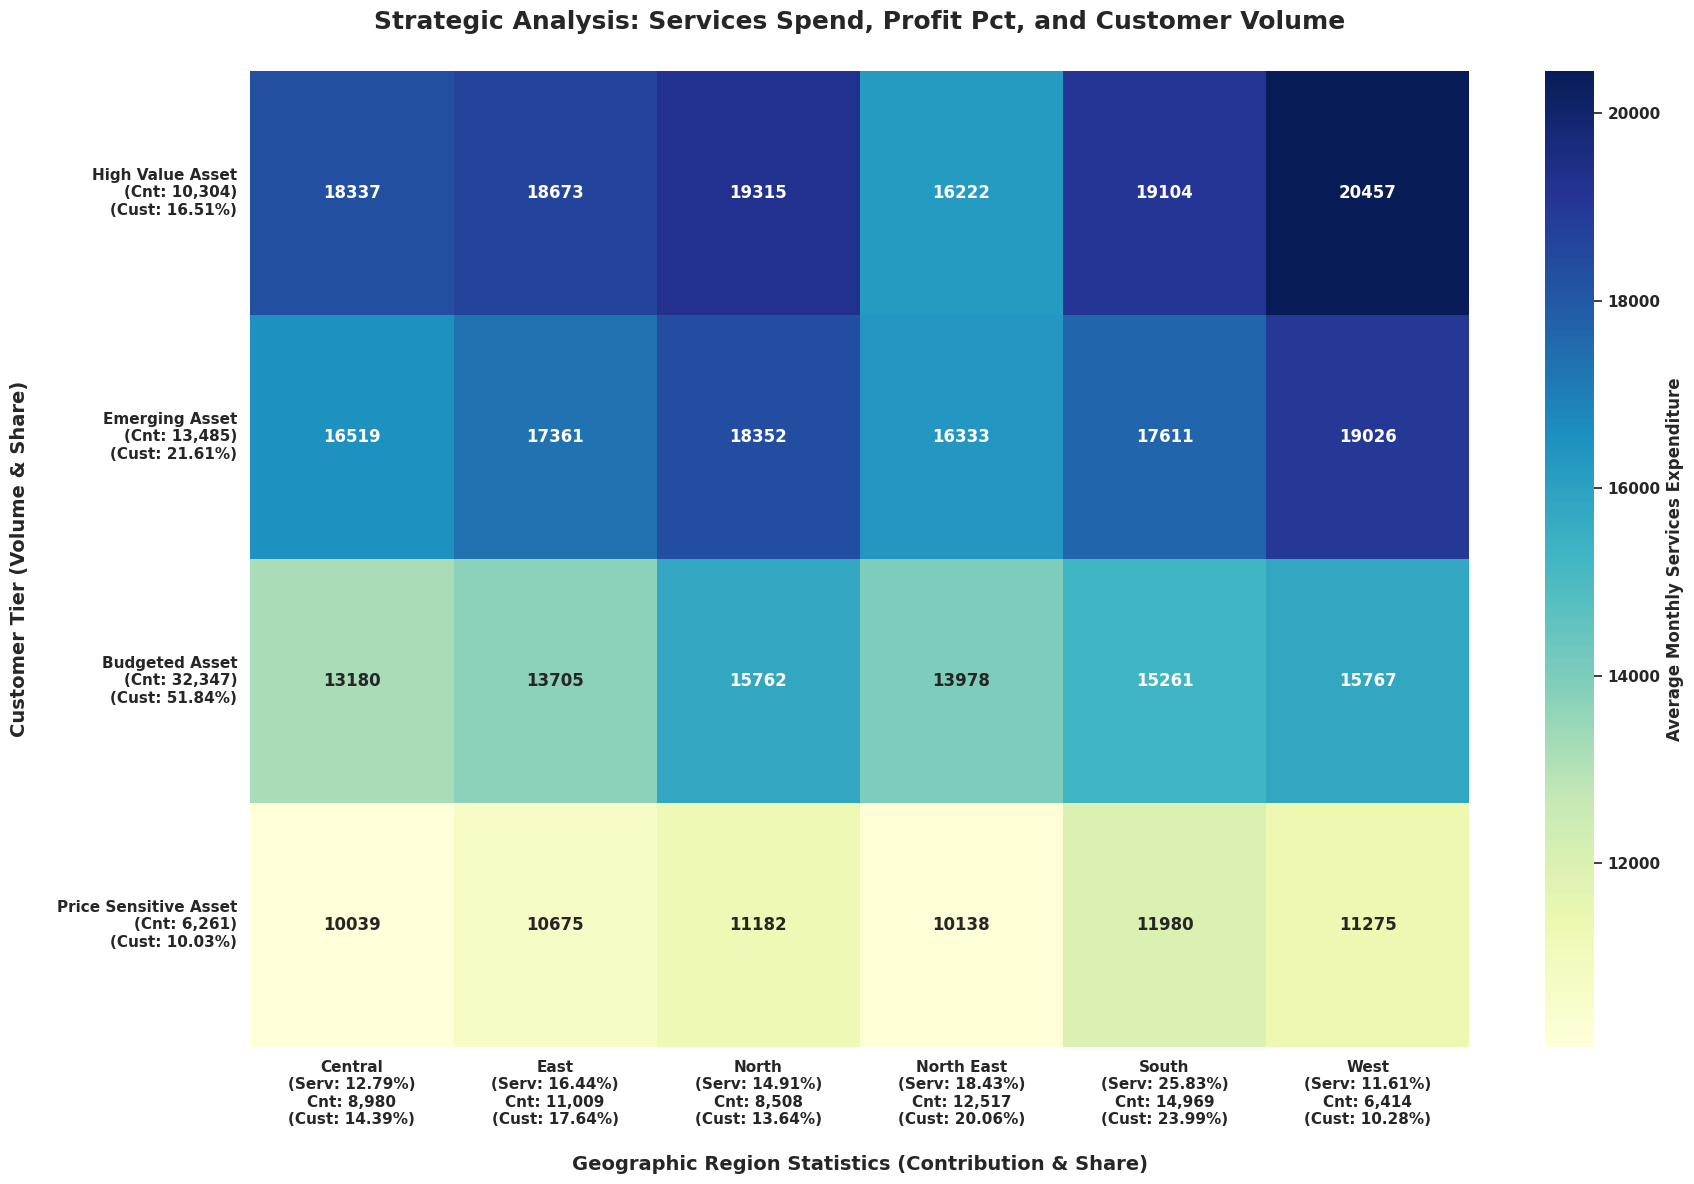

In [ ]:
# 1. Global Metrics
total_services_spend = df2['Monthly_Services_Expenditure'].sum()
total_customers = len(df2)

# 2. Regional Calculations (X-Axis Labels)
region_services_spend = df2.groupby('Region')['Monthly_Services_Expenditure'].sum()
region_profit_pct = (region_services_spend / total_services_spend) * 100
region_counts = df2.groupby('Region').size()
region_cust_base_pct = (region_counts / total_customers) * 100

# Create Multi-line Region Labels
region_labels_expanded = {
    region: f"{region}\n(Serv: {region_profit_pct[region]:.2f}%)\nCnt: {region_counts[region]:,}\n(Cust: {region_cust_base_pct[region]:.2f}%)"
    for region in region_profit_pct.index
}

# 3. Tier Calculations (Y-Axis Labels)
tier_counts = df2['clvt_label'].value_counts()
tier_cust_pct = (tier_counts / total_customers) * 100

# Create Multi-line Tier Labels
# Uses the exact names from your prompt: High Value Asset, Emerging Asset, etc.
tier_labels_expanded = {
    tier: f"{tier}\n(Cnt: {tier_counts[tier]:,})\n(Cust: {tier_cust_pct[tier]:.2f}%)"
    for tier in tier_counts.index
}

# 4. Prepare Heatmap Data
# Map labels to new expanded strings
df2['Region_Display'] = df2['Region'].map(region_labels_expanded)
df2['Tier_Display'] = df2['clvt_label'].map(tier_labels_expanded)

heatmap_data = df2.pivot_table(
    index='Tier_Display',
    columns='Region_Display',
    values='Monthly_Services_Expenditure',
    aggfunc='mean'
)

# Reorder tiers (High Value at the top)
# We look up the expanded string using the original key
reorder_keys = ['High Value Asset', 'Emerging Asset', 'Budgeted Asset', 'Price Sensitive Asset']
reorder_list = [tier_labels_expanded[key] for key in reorder_keys if key in tier_labels_expanded]
heatmap_data = heatmap_data.reindex(reorder_list)

# 5. Generate Visualization
plt.figure(figsize=(18, 12))
sns.heatmap(
    heatmap_data,
    annot=True,        # Show the average spend values in the cells
    fmt=".0f",         # Format as whole numbers
    cmap="YlGnBu",     # Professional color scheme
    cbar_kws={'label': 'Average Monthly Services Expenditure'}
)

plt.title( 'Strategic Analysis: Services Spend, Profit Pct, and Customer Volume', fontsize=18, fontweight='bold', pad=30)
plt.ylabel('Customer Tier (Volume & Share)', fontsize=14, labelpad=20)
plt.xlabel('Geographic Region Statistics (Contribution & Share)', fontsize=14, labelpad=20)
plt.yticks(rotation=0) # Keep region info easy to read
plt.tight_layout()
plt.show()

**Inferences**
- The south and the North East regions are the main consumers of Services indicating a balanced market with most of the consumers are from emerging and Budgeted Asset.

- The west contribute with highest spending ratio but still it stands lowest return on profits this might be due to west has the least volume of purchases.

- the primary profit regions for services are South,North East and East regions with high volume of customers.

**Region Wise Heatmap Expenditure on Miscellaneous Based On ClVT Labels**

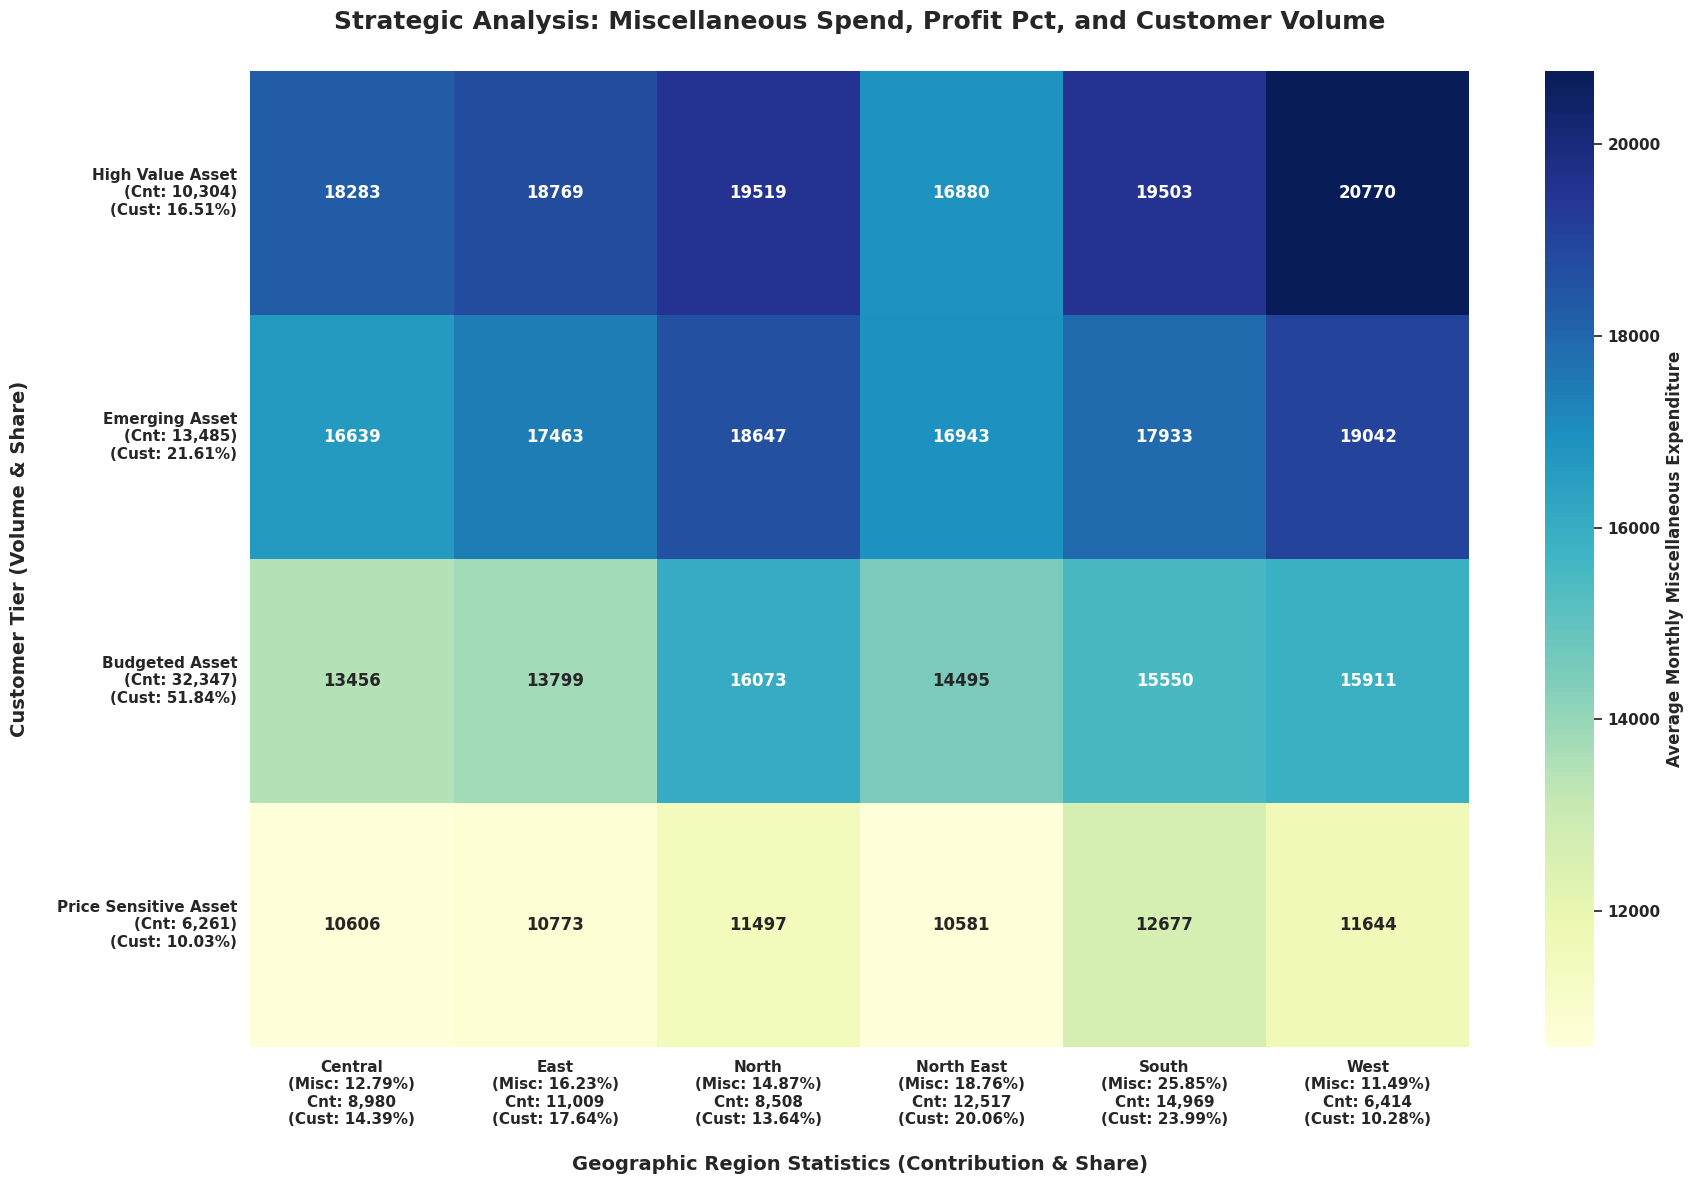

In [ ]:
# 1. Global Metrics (Miscellaneous Spend Focus)
total_misc_spend = df2['Monthly_Misc_Expenditure'].sum()
total_customers = len(df2)

# 2. Regional Calculations (X-Axis Labels)
region_misc_spend = df2.groupby('Region')['Monthly_Misc_Expenditure'].sum()
# Changed to .2f for 2 decimal places
profit_pct = (region_misc_spend / total_misc_spend) * 100
region_counts = df2.groupby('Region').size()
region_cust_base_pct = (region_counts / total_customers) * 100

# Create Multi-line Region Labels
region_labels_expanded = {
    region: f"{region}\n(Misc: {profit_pct[region]:.2f}%)\nCnt: {region_counts[region]:,}\n(Cust: {region_cust_base_pct[region]:.2f}%)"
    for region in profit_pct.index
}

# 3. Tier Calculations (Y-Axis Labels)
tier_counts = df2['clvt_label'].value_counts()
tier_cust_pct = (tier_counts / total_customers) * 100

# Create Multi-line Tier Labels
prof_labels = ['Price Sensitive Asset', 'Budgeted Asset', 'Emerging Asset', 'High Value Asset']
tier_labels_expanded = {
    tier: f"{tier}\n(Cnt: {tier_counts[tier]:,})\n(Cust: {tier_cust_pct[tier]:.2f}%)"
    for tier in prof_labels
}

# 4. Prepare Heatmap Data
df2['Region_Display'] = df2['Region'].map(region_labels_expanded)
df2['Tier_Display'] = df2['clvt_label'].map(tier_labels_expanded)

heatmap_data = df2.pivot_table(
    index='Tier_Display',
    columns='Region_Display',
    values='Monthly_Misc_Expenditure',
    aggfunc='mean'
)

# Reorder tiers (High Value at the top)
reorder_list = [tier_labels_expanded[tier] for tier in reversed(prof_labels)]
heatmap_data = heatmap_data.reindex(reorder_list)

# 5. Generate Visualization
plt.figure(figsize=(18, 12))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    cbar_kws={'label': 'Average Monthly Miscellaneous Expenditure'}
)

plt.title('Strategic Analysis: Miscellaneous Spend, Profit Pct, and Customer Volume', fontsize=18, fontweight='bold', pad=30)
plt.ylabel('Customer Tier (Volume & Share)', fontsize=14, labelpad=20)
plt.xlabel('Geographic Region Statistics (Contribution & Share)', fontsize=14, labelpad=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Inferences**

- The South,East and the North East are the most profitable regions towards expenses in miscellaneous activities, these regions prefer maintaining a certain life style.

- The North and the West have on purchases of miscellaneous lifestyle but in low volumes which indicates that targeted marketing would be effective here.

**Relation With CLVT and Expected Remaining Years**

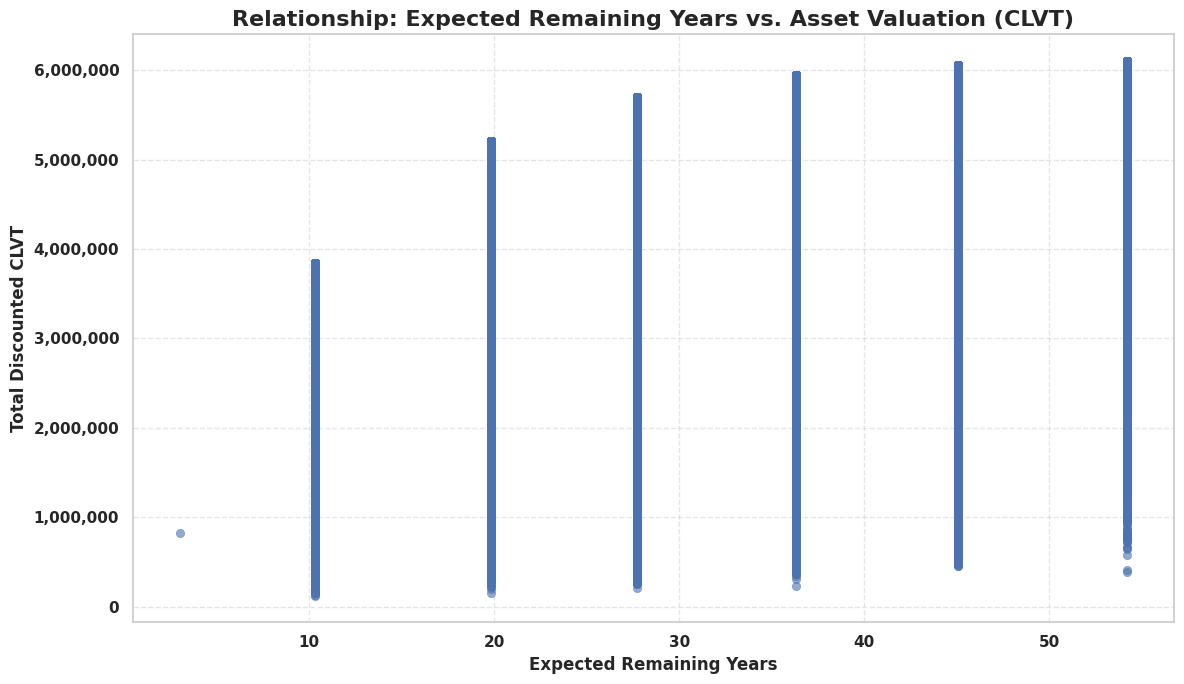

In [ ]:
# 3. Simple Scatter Plot (No Legend)
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df2,
    x='expected_remaining_years',
    y='clvt',
    alpha=0.6,
    edgecolor=None
)

# 4. Formatting for Clarity
plt.title('Relationship: Expected Remaining Years vs. Asset Valuation (CLVT)', fontsize=16, fontweight='bold')
plt.xlabel('Expected Remaining Years', fontsize=12)
plt.ylabel('Total Discounted CLVT', fontsize=12)

# Format Y-axis with commas for readability
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, p: format(int(x), ',')))

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

**Inferences**
- The Customer Lifetime Value increases as the expected remaining years increases.

In [ ]:
#export to csv
df2.to_csv('clvt_final_analysis.csv', index=False)

**Heatmap analysis By MPCE Group**

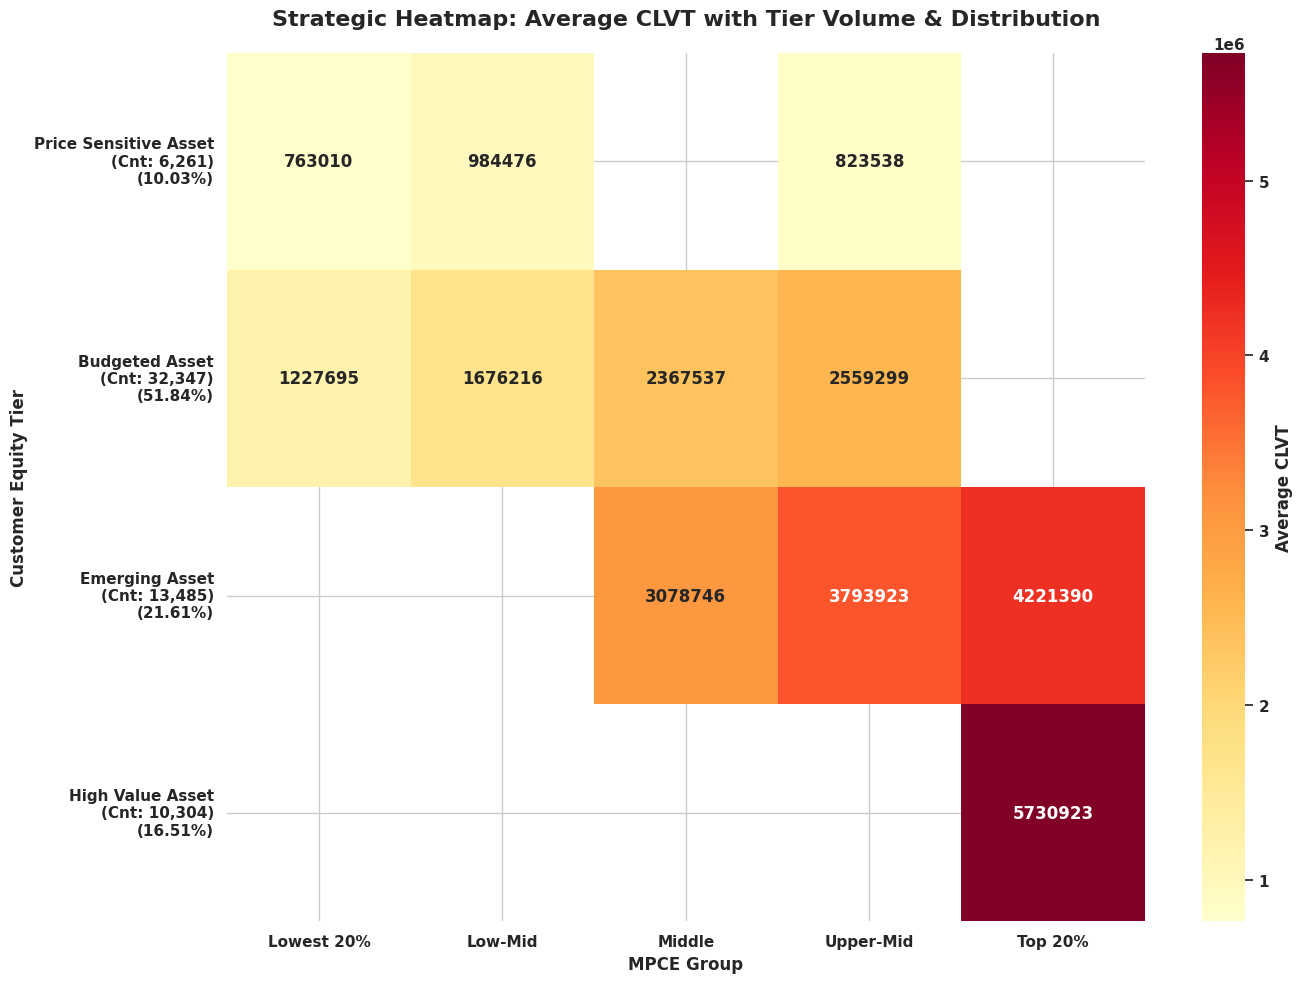

In [ ]:
# 2. Define logical ordering for axes
mpce_order = ['Lowest 20%', 'Low-Mid', 'Middle', 'Upper-Mid', 'Top 20%']
clvt_label_order = ['Price Sensitive Asset', 'Budgeted Asset', 'Emerging Asset', 'High Value Asset']

# 3. Calculate Counts and Percentages for Y-axis (CLVT Labels)
clvt_counts = df2['clvt_label'].value_counts()
clvt_pcts = (clvt_counts / len(df2)) * 100

# Format Y-axis labels with Name, Count, and Percentage
new_y_labels = [f"{l}\n(Cnt: {int(clvt_counts.get(l, 0)):,})\n({clvt_pcts.get(l, 0):.2f}%)" for l in clvt_label_order]

# 4. Prepare Heatmap Data (Average CLVT)
heatmap_data = df2.pivot_table(
    index='clvt_label',
    columns='mpce_group',
    values='clvt',
    aggfunc='mean'
).reindex(index=clvt_label_order, columns=mpce_order)

# 5. Plotting
plt.figure(figsize=(14, 10))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    cbar_kws={'label': 'Average CLVT'},
    xticklabels=mpce_order,
    yticklabels=new_y_labels
)

plt.title('Strategic Heatmap: Average CLVT with Tier Volume & Distribution', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Customer Equity Tier', fontsize=12, fontweight='bold')
plt.xlabel('MPCE Group', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Inferences**

-  The upper middle class and top 20% are under the high asset value that comprises of 23% indicates that these customer are more invested in luxury products that describes low volume and high revenue.

- The Budgeted and the Emerging asset customer form the largest revenue driver that include lowest 20% to Top 20% with a distribution of 72% which indicates high volume but medium or low margin purchases.

- The price sensitive customers comprise of 5% of total distribution but have the potential of converting them to Budgeted customers by targeted marketing on low margin products.

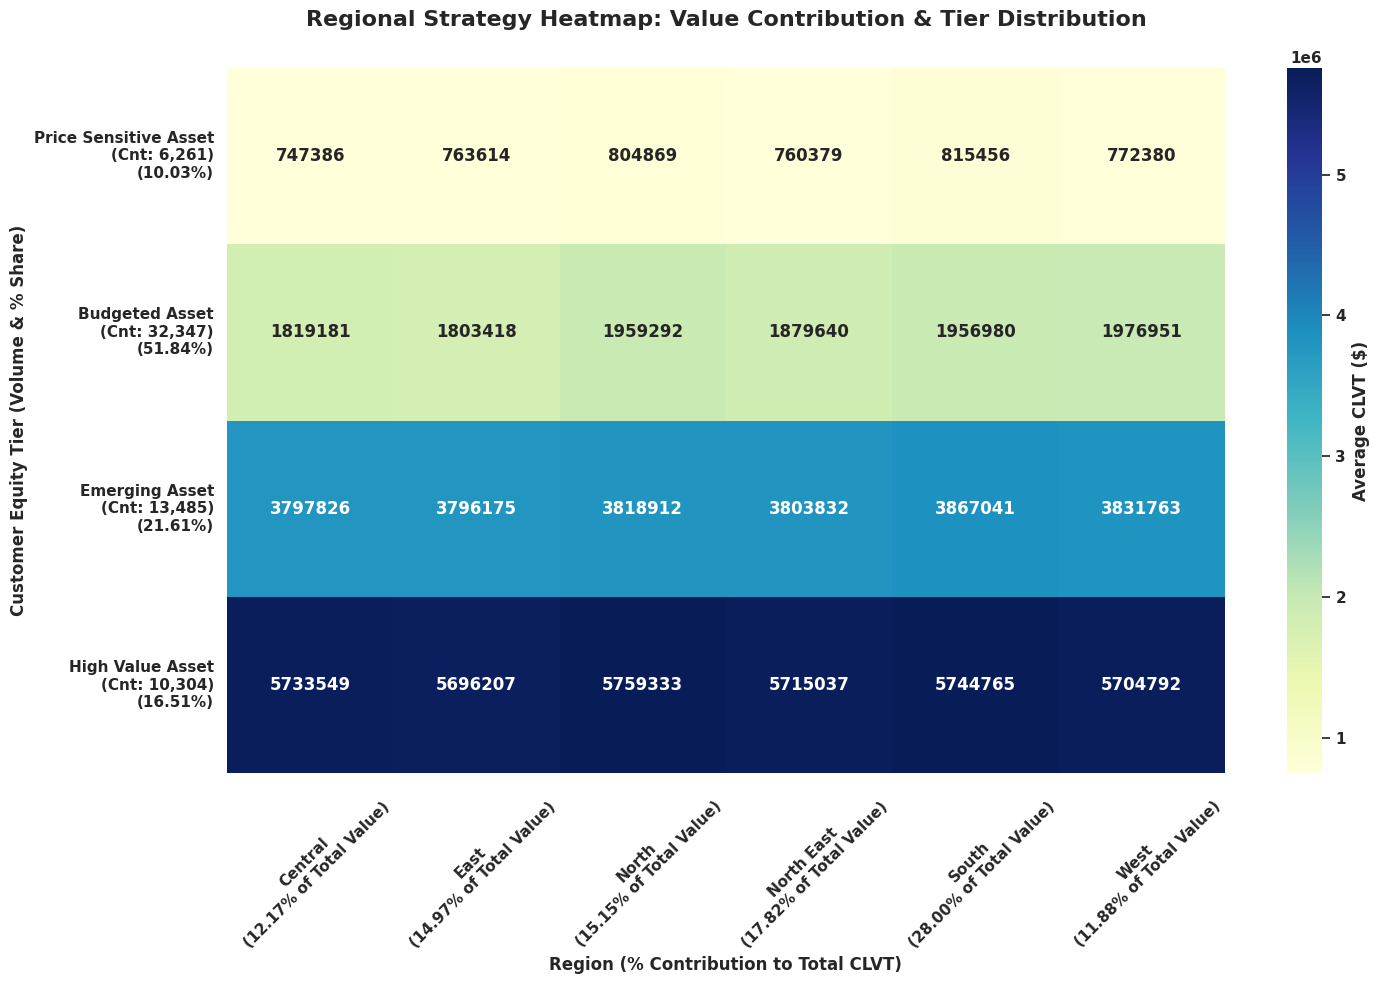

In [ ]:
# 2. Setup Y-axis Labels (Tier Name + Count + Percentage)
clvt_label_order = ['Price Sensitive Asset', 'Budgeted Asset', 'Emerging Asset', 'High Value Asset']
clvt_counts = df2['clvt_label'].value_counts()
clvt_pcts = (clvt_counts / len(df2)) * 100

new_y_labels = [
    f"{l}\n(Cnt: {int(clvt_counts.get(l, 0)):,})\n({clvt_pcts.get(l, 0):.2f}%)"
    for l in clvt_label_order
]

# 3. Calculate Regional CLVT Contribution for X-axis
total_clvt = df2['clvt'].sum()
region_clvt_sum = df2.groupby('Region')['clvt'].sum()
region_clvt_pct = (region_clvt_sum / total_clvt) * 100

# Get sorted list of regions to ensure alignment
regions = sorted(df2['Region'].unique())

# Create formatted X-axis labels
new_x_labels = [f"{r}\n({region_clvt_pct.get(r, 0):.2f}% of Total Value)" for r in regions]

# 4. Prepare Heatmap Data (Average CLVT)
heatmap_data = df2.pivot_table(
    index='clvt_label',
    columns='Region',
    values='clvt',
    aggfunc='mean'
).reindex(index=clvt_label_order, columns=regions)

# 5. Plotting
plt.figure(figsize=(15, 10))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    cbar_kws={'label': 'Average CLVT ($)'},
    xticklabels=new_x_labels,
    yticklabels=new_y_labels
)

plt.title('Regional Strategy Heatmap: Value Contribution & Tier Distribution', fontsize=16, fontweight='bold', pad=30)
plt.ylabel('Customer Equity Tier (Volume & % Share)', fontsize=12, fontweight='bold')
plt.xlabel('Region (% Contribution to Total CLVT)', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Inferences**
- The South Region is the major market for Business value contributing the highest customer lifetime value at 31.13%.

- The North and The North East Regions are marginally closer to each other which indicates that the pricing and marketing strategies are similiar, hence restructuring required.

- Price sensitive customer regardless low on contribution percentage potray potential to promoted to higher tiers in the regions like South and North.


#Clustering Using Kmeans

In [ ]:
df3 = df2.copy()

In [ ]:
df3.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,mpce_group,basket_group,clvt,clvt_label,Region_Display,Tier_Display
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,Upper-Mid,Low-Mid,3935654.17,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)"
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,Upper-Mid,Top 20%,3777561.90,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)"
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,Top 20%,Top 20%,5700629.36,High Value Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","High Value Asset\n(Cnt: 10,304)\n(Cust: 16.51%)"
7,22300_3_11,Puducherry,urban,2,28599,4,56,male,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,Upper-Mid,Middle,3419429.36,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)"
8,22300_3_12,Puducherry,urban,2,28599,6,69,male,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,Upper-Mid,Middle,2776065.40,Budgeted Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Budgeted Asset\n(Cnt: 32,347)\n(Cust: 51.84%)"


In [ ]:
#dropping all categorical columns
df3 = df3.select_dtypes(exclude=['object', 'category'])
df3.head()

,Multiplier,hh_size,head_age,is_digital_hh,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt
0,57436,4,56,1,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,871.20,19.80,3935654.17
1,27497,4,48,1,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,435.60,27.70,3777561.90
4,27497,2,53,1,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,871.20,27.70,5700629.36
7,28599,4,56,2,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,435.60,19.80,3419429.36
8,28599,6,69,2,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,871.20,10.30,2776065.40


In [ ]:
#dropping is_digital_hh,asset_score,welfare_benefit_count,total_unique_items
df3 = df3.drop(columns=['is_digital_hh','asset_score','welfare_benefit_count','total_unique_items'])
df3.head()

,Multiplier,hh_size,head_age,food_spend,intoxicant_spend,online_score,total_basket_value,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt
0,57436,4,56,13923.00,19730,3,31570,26750,28000,28000,116403.00,1396836.00,38653.25,871.20,19.80,3935654.17
1,27497,4,48,10894.00,19730,2,63520,26750,28000,28000,113374.00,1360488.00,33898.50,435.60,27.70,3777561.90
4,27497,2,53,11929.00,19730,1,65980,25000,24500,24000,105159.00,1261908.00,51155.43,871.20,27.70,5700629.36
7,28599,4,56,9843.00,19730,2,35800,26750,28000,28000,112323.00,1347876.00,33583.25,435.60,19.80,3419429.36
8,28599,6,69,88950.00,13520,2,41280,26750,28000,28000,185220.00,2222640.00,36995.00,871.20,10.30,2776065.40


In [ ]:
#drop multiplier column
df3 = df3.drop(columns=['Multiplier'])
df3.head()

,hh_size,head_age,food_spend,intoxicant_spend,online_score,total_basket_value,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt
0,4,56,13923.00,19730,3,31570,26750,28000,28000,116403.00,1396836.00,38653.25,871.20,19.80,3935654.17
1,4,48,10894.00,19730,2,63520,26750,28000,28000,113374.00,1360488.00,33898.50,435.60,27.70,3777561.90
4,2,53,11929.00,19730,1,65980,25000,24500,24000,105159.00,1261908.00,51155.43,871.20,27.70,5700629.36
7,4,56,9843.00,19730,2,35800,26750,28000,28000,112323.00,1347876.00,33583.25,435.60,19.80,3419429.36
8,6,69,88950.00,13520,2,41280,26750,28000,28000,185220.00,2222640.00,36995.00,871.20,10.30,2776065.40


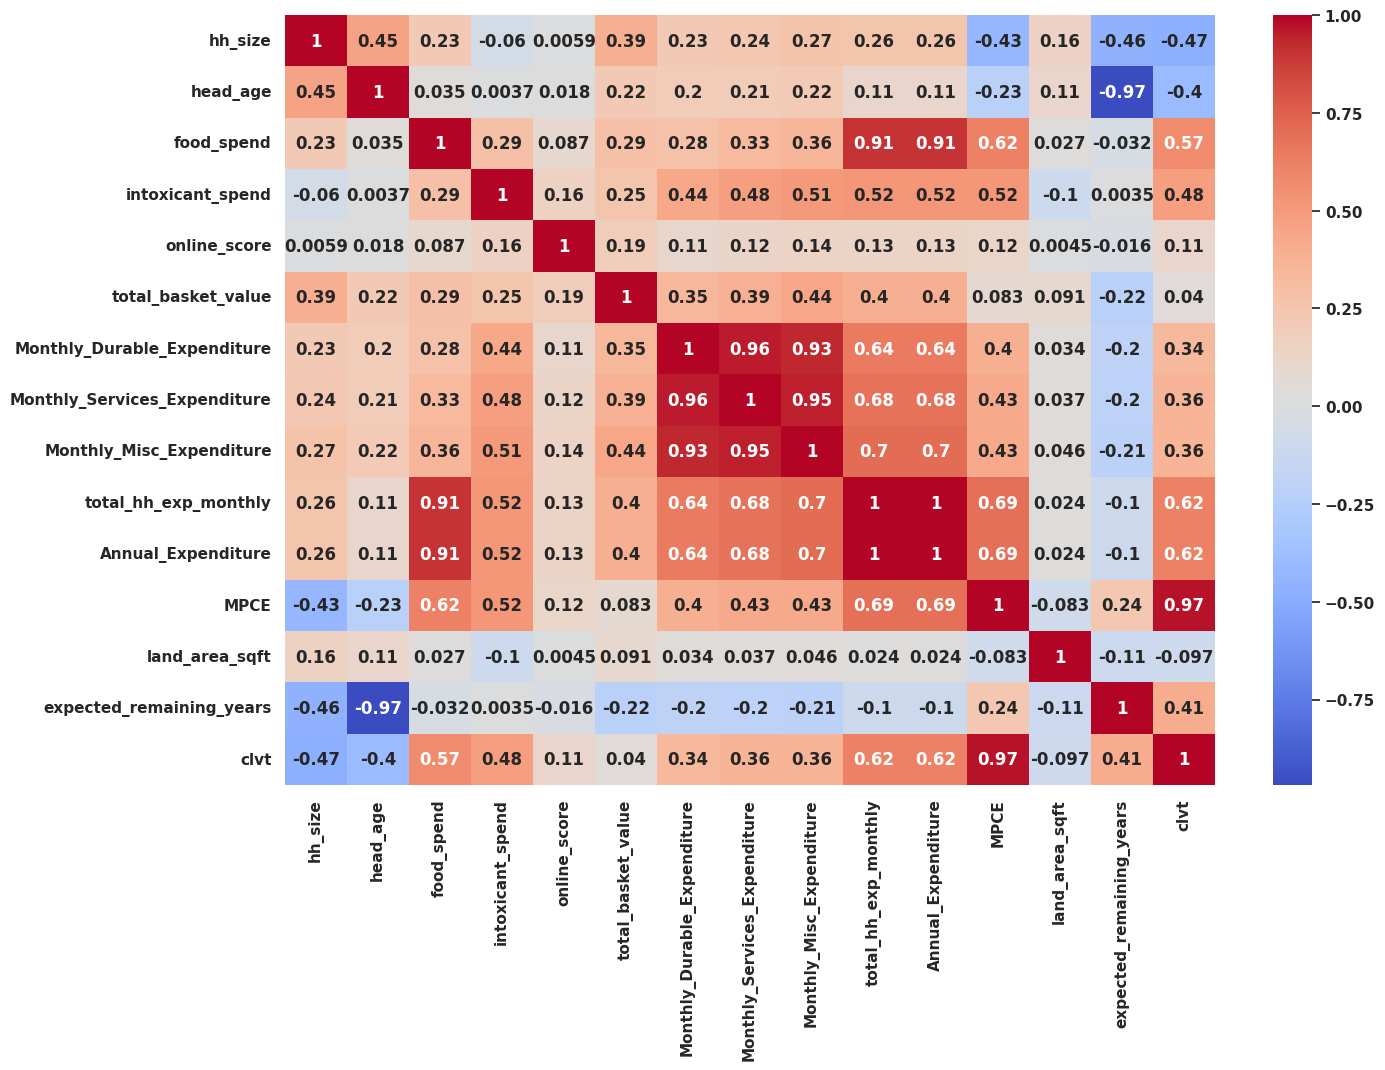

In [ ]:
#checking with correlation map
plt.figure(figsize=(15,10))
sns.heatmap(df3.corr(),annot=True,cmap='coolwarm')
plt.show()


In [ ]:
#dropping hh_size and head_age and total_hh_exp_monthly and annual_exp
df3 = df3.drop(columns=['hh_size','head_age','Annual_Expenditure','expected_remaining_years'])
df3.head()

,food_spend,intoxicant_spend,online_score,total_basket_value,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,MPCE,land_area_sqft,clvt
0,13923.00,19730,3,31570,26750,28000,28000,116403.00,38653.25,871.20,3935654.17
1,10894.00,19730,2,63520,26750,28000,28000,113374.00,33898.50,435.60,3777561.90
4,11929.00,19730,1,65980,25000,24500,24000,105159.00,51155.43,871.20,5700629.36
7,9843.00,19730,2,35800,26750,28000,28000,112323.00,33583.25,435.60,3419429.36
8,88950.00,13520,2,41280,26750,28000,28000,185220.00,36995.00,871.20,2776065.40


In [ ]:
#dropping  multiplier, land area sqft, monthly_durable_expenditure,monthly_services_expenditure,
#monthly_misc_expenditure,food_spend and intoxicant_spend,online score , total basket value
df3 = df3.drop(columns=['land_area_sqft','Monthly_Durable_Expenditure','Monthly_Services_Expenditure','food_spend','intoxicant_spend','online_score','total_basket_value','Monthly_Misc_Expenditure'])
df3.head()

,total_hh_exp_monthly,MPCE,clvt
0,116403.00,38653.25,3935654.17
1,113374.00,33898.50,3777561.90
4,105159.00,51155.43,5700629.36
7,112323.00,33583.25,3419429.36
8,185220.00,36995.00,2776065.40


In [ ]:
#applying the standard scaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df3 = pd.DataFrame(scaler.fit_transform(df3), columns=df3.columns)
df3.head()

,total_hh_exp_monthly,MPCE,clvt
0,0.38,0.87,0.67
1,0.32,0.54,0.57
2,0.15,1.74,1.74
3,0.30,0.52,0.36
4,1.77,0.75,-0.03


Elbow plot for Dataframe


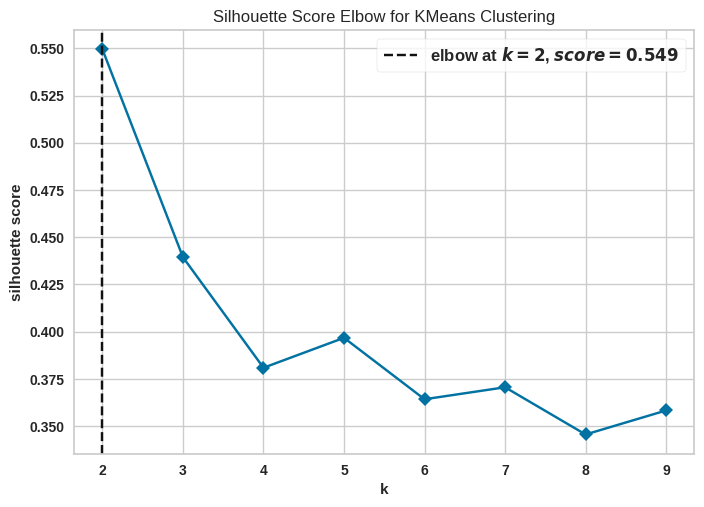

In [ ]:
#visualizing silhouette score with Kelbow visualizer
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
model = KMeans(random_state=0,max_iter=500,init = 'k-means++')
visualizer = KElbowVisualizer(model,k =(2,10),metric = 'silhouette',timings = False)
print('Elbow plot for Dataframe')
visualizer.fit(df3)
visualizer.show()
plt.show()

In [ ]:
#clustering the num_df using k = 2
from sklearn.cluster import KMeans
kmeans_mod = KMeans(n_clusters=2,random_state = 42,max_iter=500,init = 'k-means++')
kmeans_mod.fit(df3)

KMeans(max_iter=500, n_clusters=2, random_state=42)

In [ ]:
#cheking with kmeans inertia
kmeans_mod.inertia_

68661.40893659432

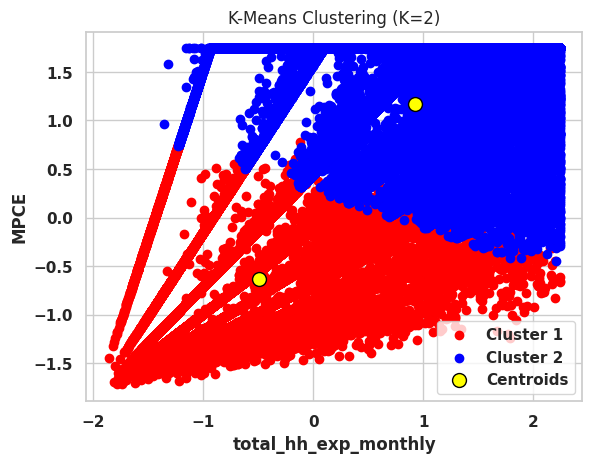

In [ ]:
# Checking the clusters with the scatter plot for 3 classes
plt.scatter(df3.loc[kmeans_mod.labels_==0, df3.columns[0]], df3.loc[kmeans_mod.labels_==0, df3.columns[1]], c='red', label='Cluster 1')
plt.scatter(df3.loc[kmeans_mod.labels_==1, df3.columns[0]], df3.loc[kmeans_mod.labels_==1, df3.columns[1]], c='blue', label='Cluster 2')
# The centroid plot remains the same, as it automatically plots all 3 centroids
plt.scatter(kmeans_mod.cluster_centers_[:,0], kmeans_mod.cluster_centers_[:,1], s=100, c='yellow', label='Centroids', edgecolors='black')

plt.legend()
plt.xlabel(df3.columns[0])
plt.ylabel(df3.columns[1])
plt.title('K-Means Clustering (K=2)')
plt.show()

#Clustering Using PCA

In [ ]:
pc_df = df2.copy()
pc_df.head()

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,mpce_group,basket_group,clvt,clvt_label,Region_Display,Tier_Display
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,Upper-Mid,Low-Mid,3935654.17,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)"
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,Upper-Mid,Top 20%,3777561.90,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)"
4,22300_2_4,Puducherry,urban,2,27497,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,Top 20%,Top 20%,5700629.36,High Value Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","High Value Asset\n(Cnt: 10,304)\n(Cust: 16.51%)"
7,22300_3_11,Puducherry,urban,2,28599,4,56,male,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,Upper-Mid,Middle,3419429.36,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)"
8,22300_3_12,Puducherry,urban,2,28599,6,69,male,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,Upper-Mid,Middle,2776065.40,Budgeted Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Budgeted Asset\n(Cnt: 32,347)\n(Cust: 51.84%)"


In [ ]:
#dropping all categorical columns
pc_df = pc_df.select_dtypes(exclude=['object', 'category'])
pc_df.head()

,Multiplier,hh_size,head_age,is_digital_hh,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt
0,57436,4,56,1,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,871.20,19.80,3935654.17
1,27497,4,48,1,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,435.60,27.70,3777561.90
4,27497,2,53,1,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,871.20,27.70,5700629.36
7,28599,4,56,2,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,435.60,19.80,3419429.36
8,28599,6,69,2,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,871.20,10.30,2776065.40


In [ ]:
#shape
pc_df.shape

(62397, 20)

In [ ]:
#applying standard scaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
pc_df = pd.DataFrame(scaler.fit_transform(pc_df), columns=pc_df.columns)
pc_df.head()

,Multiplier,hh_size,head_age,is_digital_hh,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt
0,-0.44,-0.13,0.56,-0.61,-0.76,1.82,1.97,1.49,-0.08,-0.58,0.13,1.90,1.91,1.87,0.38,0.38,0.87,-0.35,-0.79,0.67
1,-0.77,-0.13,-0.01,-0.61,-0.85,1.82,0.53,1.49,-0.08,1.02,-0.31,1.90,1.91,1.87,0.32,0.32,0.54,-0.35,-0.11,0.57
2,-0.77,-1.28,0.34,-0.61,-0.82,1.82,-0.92,1.49,-0.08,1.15,-0.09,1.63,1.37,1.26,0.15,0.15,1.74,-0.35,-0.11,1.74
3,-0.76,-0.13,0.56,1.64,-0.87,1.82,0.53,-0.16,-0.08,-0.37,-0.53,1.90,1.91,1.87,0.30,0.30,0.52,-0.35,-0.79,0.36
4,-0.76,1.02,1.49,1.64,1.26,0.73,0.53,0.67,-0.08,-0.09,-0.53,1.90,1.91,1.87,1.77,1.77,0.75,-0.35,-1.60,-0.03


In [ ]:
#applying pca on the dataframe
from sklearn.decomposition import PCA
pca = PCA(n_components=10)
pc_results = pd.DataFrame(pca.fit_transform(pc_df),columns=['pc1','pc2','pc3','pc4','pc5','pc6','pc7','pc8','pc9','pc10'])
pc_results.head()

,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,pc10
0,3.29,-0.22,-2.64,-1.67,-0.33,0.65,0.99,-0.09,0.63,0.27
1,3.19,-0.07,-2.17,-2.22,0.15,-0.35,0.01,0.23,0.04,-0.16
2,3.08,1.10,-2.14,-1.41,-0.42,-0.75,-0.43,0.77,-0.94,-1.79
3,2.36,-0.84,-2.86,-0.17,0.06,-0.56,-0.00,0.21,1.65,-0.70
4,4.18,-2.15,-1.49,1.45,-0.65,-0.63,-0.05,0.11,1.34,0.66


In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns= ['pc1','pc2','pc3','pc4','pc5','pc6','pc7','pc8','pc9','pc10'],
    index=pc_df.columns
)

# Ranking features for PC1 (The most important component)
print("Top features contributing to PC1:")
print(loadings['pc1'].abs().sort_values(ascending=False))

Top features contributing to PC1:
total_hh_exp_monthly           0.37
Annual_Expenditure             0.37
Monthly_Misc_Expenditure       0.34
Monthly_Services_Expenditure   0.33
Monthly_Durable_Expenditure    0.32
food_spend                     0.28
MPCE                           0.27
intoxicant_spend               0.25
clvt                           0.25
asset_score                    0.22
total_basket_value             0.20
total_unique_items             0.12
hh_size                        0.08
online_score                   0.08
is_digital_hh                  0.07
head_age                       0.06
expected_remaining_years       0.06
Multiplier                     0.01
land_area_sqft                 0.01
welfare_benefit_count          0.01
Name: pc1, dtype: float64


<Axes: xlabel='pc1', ylabel='pc2'>

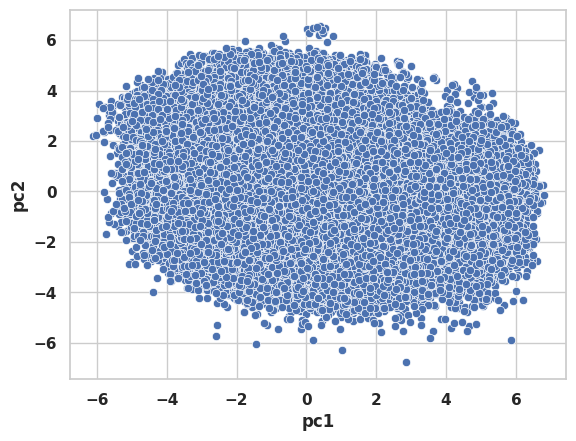

In [ ]:
#plotting scatter plot
sns.scatterplot(x=pc_results.pc1,y=pc_results.pc2,palette='dark')

In [ ]:
#checking with explained variance for our columns
var = (pca.explained_variance_ratio_)
var

array([0.32292012, 0.17953634, 0.07504701, 0.07055652, 0.05744295,
       0.04991435, 0.04927816, 0.04525925, 0.03999762, 0.03352296])

In [ ]:
#checking with cumulative variance
cum_var = pd.DataFrame(np.cumsum(np.round(var,decimals=2)*100))
cum_var

,0
0,32.00
1,50.00
2,58.00
3,65.00
4,71.00
5,76.00
6,81.00
7,86.00
8,90.00
9,93.00


Text(0.5, 1.0, 'Explained variance by each component')

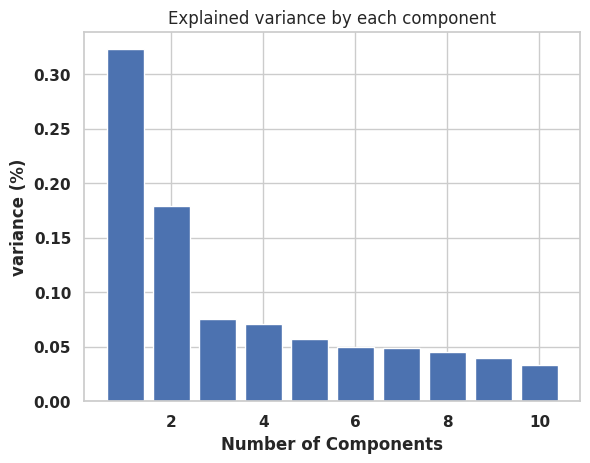

In [ ]:
#plotting against variance for components
plt.bar(range(1, len(var)+1),var)
plt.xlabel('Number of Components')
plt.ylabel('variance (%)')
plt.title('Explained variance by each component')

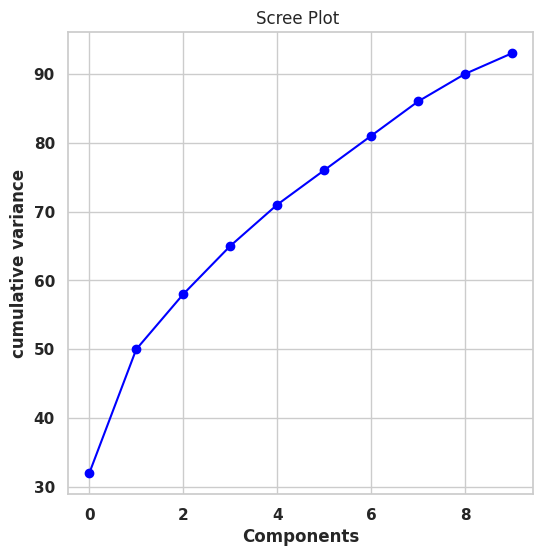

In [ ]:
#plotting scree plot
plt.figure(figsize=(6,6))
plt.plot(cum_var,color = 'blue',marker = 'o')
plt.title('Scree Plot ')
plt.xlabel('Components')
plt.ylabel('cumulative variance')
plt.show()

**We can observe that with 2 component we are getting variance over 60%**

In [ ]:
#selecting our top 2 features
pca_2 = PCA(n_components=2)
pca_final = pd.DataFrame(pca_2.fit_transform(pc_df),columns=['pc1','pc2'])

pca_final.head()

,pc1,pc2
0,3.29,-0.22
1,3.19,-0.07
2,3.08,1.10
3,2.36,-0.84
4,4.18,-2.15


Elbow plot for Dataframe


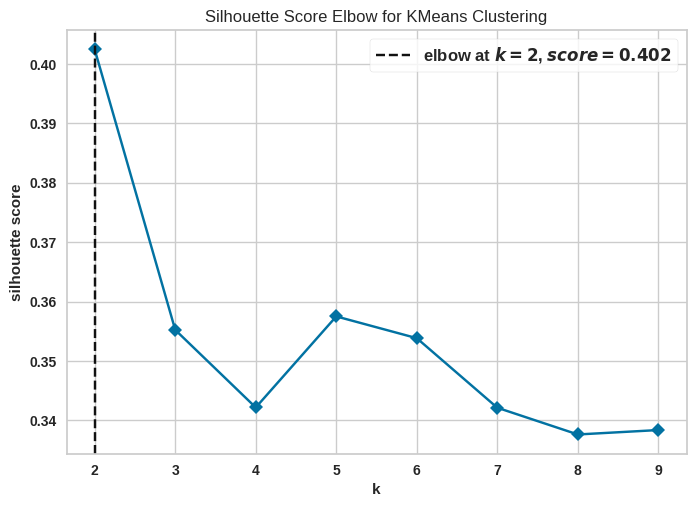

In [ ]:
model = KMeans(random_state=0,max_iter=500,init = 'k-means++')
visualizer = KElbowVisualizer(model,k =(2,10),metric = 'silhouette',timings = False)
print('Elbow plot for Dataframe')
visualizer.fit(pca_final)
visualizer.show()
plt.show()

In [ ]:
#clustering the num_df using k = 5
from sklearn.cluster import KMeans
kmeans_mod = KMeans(n_clusters=5,random_state = 42,max_iter=500,init = 'k-means++')
kmeans_mod.fit(pca_final)

KMeans(max_iter=500, n_clusters=5, random_state=42)

In [ ]:
#cheking with kmeans inertia
kmeans_mod.inertia_

156525.93333932463

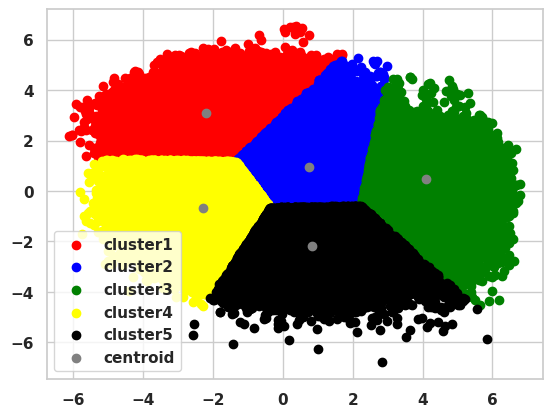

In [ ]:
#cheking the clusters with the scatter plot for both classes
plt.scatter(pca_final.loc[kmeans_mod.labels_==0, pca_final.columns[0]], pca_final.loc[kmeans_mod.labels_==0, pca_final.columns[1]], c='red',label='cluster1')
plt.scatter(pca_final.loc[kmeans_mod.labels_==1, pca_final.columns[0]], pca_final.loc[kmeans_mod.labels_==1, pca_final.columns[1]], c='blue',label='cluster2')
plt.scatter(pca_final.loc[kmeans_mod.labels_==2, pca_final.columns[0]], pca_final.loc[kmeans_mod.labels_==2, pca_final.columns[1]], c='green',label='cluster3')
plt.scatter(pca_final.loc[kmeans_mod.labels_==3, pca_final.columns[0]], pca_final.loc[kmeans_mod.labels_==3, pca_final.columns[1]], c='yellow',label='cluster4')
plt.scatter(pca_final.loc[kmeans_mod.labels_==4, pca_final.columns[0]], pca_final.loc[kmeans_mod.labels_==4, pca_final.columns[1]], c='black',label='cluster5')
plt.scatter(kmeans_mod.cluster_centers_[:,0],kmeans_mod.cluster_centers_[:,1],c='grey',label='centroid')
plt.legend()
plt.show()


**Inferences**

- After all the ways of application of clustering algorithm with and without pca we finally select the model with pca since our clusters have been perfectly distributed

In [ ]:
#checking with our labels
kmeans_mod.labels_

array([2, 2, 2, ..., 3, 3, 3], dtype=int32)

In [ ]:
#checking with centroids of the clusters
kmeans_mod.cluster_centers_

array([[-2.19611339,  3.10732488],
       [ 0.73830917,  0.95178908],
       [ 4.10495301,  0.457341  ],
       [-2.29230443, -0.69416512],
       [ 0.82943616, -2.19824692]])

In [ ]:
#inverse scaling for pcdf
pc_df = pd.DataFrame(scaler.inverse_transform(pc_df), columns=pc_df.columns)
pc_df.head()

,Multiplier,hh_size,head_age,is_digital_hh,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt
0,57436.00,4.00,56.00,1.00,13923.00,19730.00,3.00,5.00,-0.00,31570.00,20.00,26750.00,28000.00,28000.00,116403.00,1396836.00,38653.25,871.20,19.80,3935654.17
1,27497.00,4.00,48.00,1.00,10894.00,19730.00,2.00,5.00,-0.00,63520.00,18.00,26750.00,28000.00,28000.00,113374.00,1360488.00,33898.50,435.60,27.70,3777561.90
2,27497.00,2.00,53.00,1.00,11929.00,19730.00,1.00,5.00,-0.00,65980.00,19.00,25000.00,24500.00,24000.00,105159.00,1261908.00,51155.43,871.20,27.70,5700629.36
3,28599.00,4.00,56.00,2.00,9843.00,19730.00,2.00,3.00,-0.00,35800.00,17.00,26750.00,28000.00,28000.00,112323.00,1347876.00,33583.25,435.60,19.80,3419429.36
4,28599.00,6.00,69.00,2.00,88950.00,13520.00,2.00,4.00,-0.00,41280.00,17.00,26750.00,28000.00,28000.00,185220.00,2222640.00,36995.00,871.20,10.30,2776065.40


In [ ]:
#labeling our cluster to our original dataset
pc_df['kmeans_label_std'] = kmeans_mod.labels_

In [ ]:
# Group data by Clusters (K=2)
pc_df.groupby('kmeans_label_std').agg(['mean'])

,Multiplier,hh_size,head_age,is_digital_hh,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt
,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean,mean
kmeans_label_std,,,,,,,,,,,,,,,,,,,,
0,112627.94,1.73,28.17,1.03,22845.60,8186.97,1.56,2.02,0.00,24039.73,14.86,8922.80,9245.25,9286.85,58487.46,701849.55,33551.38,7655.57,46.40,3964224.32
1,95476.64,3.73,42.67,1.08,53103.92,10994.35,1.64,3.46,0.01,41932.87,19.18,15482.62,16245.34,16528.46,112354.69,1348256.29,32490.55,20884.38,33.51,3663946.91
2,97905.18,4.45,49.19,1.11,87398.15,15306.84,1.86,4.17,0.00,56586.37,21.06,22663.47,24126.79,24529.26,174024.51,2088294.16,44633.60,26637.28,28.17,4797809.95
3,99582.96,4.37,50.60,1.41,18167.39,5485.45,1.50,2.69,0.01,36058.81,18.94,10497.55,10738.22,10983.61,55872.22,670466.60,13722.84,32728.85,26.68,1458883.73
4,87851.14,5.89,61.84,1.54,42690.67,9397.22,1.70,3.59,0.01,56415.05,21.75,17936.71,18880.69,19368.81,108274.10,1299289.19,19624.81,57525.64,17.91,1806223.79


In [ ]:
#saving our average clusters into excel file
kmeans_df = pc_df.groupby('kmeans_label_std').agg(['mean'])
kmeans_df.to_csv('clustering.csv')

In [ ]:
df4 = df2.copy()
df4['kmeans_label_std'] = kmeans_mod.labels_
df4.head(2)

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,mpce_group,basket_group,clvt,clvt_label,Region_Display,Tier_Display,kmeans_label_std
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,Upper-Mid,Low-Mid,3935654.17,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)",2
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,Upper-Mid,Top 20%,3777561.90,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)",2


In [ ]:
#grouping by clvt labels
grouped_df = df4.groupby('kmeans_label_std').agg(
    hh_size=('hh_size', 'mean'),
    head_age=('head_age', 'mean'),
    Annual_Expenditure=('Annual_Expenditure', 'mean'),
    total_basket_value=('total_basket_value', 'mean'),
    mpce=('MPCE', 'mean'),
    expected_remaining_years=('expected_remaining_years', 'mean'),
    online_score=('online_score', 'mean'),
    clvt=('clvt', 'mean'),
    total_unique_items=('total_unique_items', 'mean'),
    region_mode = ('Region', lambda x: x.mode()[0]),
    sector_mode = ('Sector', lambda x: x.mode()[0]),
    head_education_mode = ('head_education_level', lambda x: x.mode()[0]),
    clvt_label_mode = ('clvt_label', lambda x: x.mode()[0])


)
display(grouped_df)

,hh_size,head_age,Annual_Expenditure,total_basket_value,mpce,expected_remaining_years,online_score,clvt,total_unique_items,region_mode,sector_mode,head_education_mode,clvt_label_mode
kmeans_label_std,,,,,,,,,,,,,
0,1.73,28.17,701849.55,24039.73,33551.38,46.40,1.56,3964224.32,14.86,South,urban,Post Graduate+,High Value Asset
1,3.73,42.67,1348256.29,41932.87,32490.55,33.51,1.64,3663946.91,19.18,South,urban,Post Graduate+,Emerging Asset
2,4.45,49.19,2088294.16,56586.37,44633.60,28.17,1.86,4797809.95,21.06,South,urban,Post Graduate+,High Value Asset
3,4.37,50.60,670466.60,36058.81,13722.84,26.68,1.50,1458883.73,18.94,East,rural,Not Literate,Budgeted Asset
4,5.89,61.84,1299289.19,56415.05,19624.81,17.91,1.70,1806223.79,21.75,North East,urban,Not Literate,Budgeted Asset


**Inferences**

Cluster 1
- In the given cluster the household size is smaller with generally most from young households, consumers in this cluster indicate a high mpce ratio despite being smaller in size that explains a high standard of living with high expected remaining years, these consumers are thickly populated in the Urban sector with highest education mode and are future gold mine falling under high value asset. Also the unique items bought in this cluster is lower compared to other clusters which indicates that the youth belives in specific purchases.

Cluster 2

- In the given cluster the household size is generally nuclear families with most of the consumers mid aged with higher basket value and lower mpce due to the family size, these consumers have a better online score comparatively to young consumers because of stable basket and mpce value.Most of the consumers are also from the south region in numbers and are the emerging asset with a potential to reach at high value asset with showing signs of consistent shopping.

Cluster 3

- In the given cluster the household size is higher with mature adults having highest affordability rate.Most of the consumers in this group prefer online shopping and purchase of most unique items. These consumers hav highest customer lifetime value even with lower expectancy year compared to cluster 1 which explains that these consumers are most wealthy and most invested into luxury products.Most wealthy consumers are from south region urban side proving to be the largest profitable markets.

Cluster 4

- In the given cluster the household size and age is marginally higher than cluster 3 inclusive as mature adults with lowest mpce and lowest online score because of large size of family and living in the rural side of regions. These are price sensitive customers and basically would like to invest only on the essential commodities. In this cluster most of the consumers are not literate hence leading to low cutomer lifetime value and being labelled as budgeted assets.

Cluster 5

- In the given cluster the household size is largest of all cluster, households with joint families and old adults  with least expected remaining years. These households have the highest unique items bought compared to all clusters which indicates that these consumers are value oriented consumers. The households in this cluster are having least literacy rate and most households are from the urban side of North East India. These households have the highest buying power but lowest mpce which explains are bulk buyers. The reason having the load of managing financing of large families generally are bundle buyers on a certain  limit hence they are  placed in Budgeted Assets.

In [ ]:
#export to csv
grouped_df.to_csv('cluster_analysis.csv')

#Classification Model

In [ ]:
#copy
df5 = df2.copy()
df5.head(2)

,HHID,State,Sector,District,Multiplier,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,mpce_group,basket_group,clvt,clvt_label,Region_Display,Tier_Display
0,22300_1_1,Puducherry,urban,2,57436,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,Upper-Mid,Low-Mid,3935654.17,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)"
1,22300_2_1,Puducherry,urban,2,27497,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,Upper-Mid,Top 20%,3777561.90,Emerging Asset,"South\n(Misc: 25.85%)\nCnt: 14,969\n(Cust: 23....","Emerging Asset\n(Cnt: 13,485)\n(Cust: 21.61%)"


In [ ]:
#dropping the tier and region display,hhid,multiplier,
df5.drop(['Tier_Display','Region_Display','HHID','Multiplier','mpce_group','basket_group'],axis=1,inplace=True)
df5.head()

,State,Sector,District,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label
0,Puducherry,urban,2,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset
1,Puducherry,urban,2,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset
4,Puducherry,urban,2,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset
7,Puducherry,urban,2,4,56,male,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset
8,Puducherry,urban,2,6,69,male,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset


In [ ]:
#re mapping the state column
state_name_to_code = {
    'Jammu & Kashmir': 1, 'Himachal Pradesh': 2, 'Punjab': 3, 'Chandigarh': 4,
    'Uttarakhand': 5, 'Haryana': 6, 'Delhi': 7, 'Rajasthan': 8, 'Uttar Pradesh': 9,
    'Bihar': 10, 'Sikkim': 11, 'Arunachal Pradesh': 12, 'Nagaland': 13, 'Manipur': 14,
    'Mizoram': 15, 'Tripura': 16, 'Meghalaya': 17, 'Assam': 18, 'West Bengal': 19,
    'Jharkhand': 20, 'Odisha': 21, 'Chhattisgarh': 22, 'Madhya Pradesh': 23,
    'Gujarat': 24, 'Daman & Diu': 25, 'Dadra & Nagar Haveli': 26, 'Maharashtra': 27,
    'Andhra Pradesh': 28, 'Karnataka': 29, 'Goa': 30, 'Lakshadweep': 31, 'Kerala': 32,
    'Tamil Nadu': 33, 'Puducherry': 34, 'Andaman & Nicobar': 35, 'Telangana': 36, 'Ladakh': 37
}

# 3. Apply the mapping to create a 'State_Code' column
df5['State'] = df5['State'].map(state_name_to_code)
df5.head()

,State,Sector,District,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label
0,34,urban,2,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset
1,34,urban,2,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset
4,34,urban,2,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset
7,34,urban,2,4,56,male,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset
8,34,urban,2,6,69,male,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset


In [ ]:
#dummification the sector column as integer
sector_dummies = pd.get_dummies(df5['Sector'], prefix='Sector').astype(int)
df5 = pd.concat([df5, sector_dummies], axis=1)
#drop sector
df5.drop('Sector',axis=1,inplace=True)
df5.head()

,State,District,hh_size,head_age,head_gender,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban
0,34,2,4,56,male,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset,0,1
1,34,2,4,48,male,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset,0,1
4,34,2,2,53,male,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset,0,1
7,34,2,4,56,male,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset,0,1
8,34,2,6,69,male,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset,0,1


In [ ]:
#dummies for gender as int
gender_dummies = pd.get_dummies(df5['head_gender'], prefix='head_gender').astype(int)
df5 = pd.concat([df5, gender_dummies], axis=1)
#drop gender
df5.drop('head_gender',axis=1,inplace=True)
df5.head()

,State,District,hh_size,head_age,head_marital_status,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male
0,34,2,4,56,married,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset,0,1,0,0,1
1,34,2,4,48,married,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset,0,1,0,0,1
4,34,2,2,53,married,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset,0,1,0,0,1
7,34,2,4,56,married,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset,0,1,0,0,1
8,34,2,6,69,married,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset,0,1,0,0,1


In [ ]:
#dummies for marital status as int
marital_dummies = pd.get_dummies(df5['head_marital_status'], prefix='head_marital_status').astype(int)
df5 = pd.concat([df5, marital_dummies], axis=1)
#drop marital status
df5.drop('head_marital_status',axis=1,inplace=True)
df5.head()

,State,District,hh_size,head_age,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married
0,34,2,4,56,Post Graduate+,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset,0,1,0,0,1,0,0,0,1
1,34,2,4,48,Primary,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset,0,1,0,0,1,0,0,0,1
4,34,2,2,53,Post Graduate & Above,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset,0,1,0,0,1,0,0,0,1
7,34,2,4,56,Below Primary,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset,0,1,0,0,1,0,0,0,1
8,34,2,6,69,Primary,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset,0,1,0,0,1,0,0,0,1


In [ ]:
#mapping head_eduction_level
reverse_edu_map = {
    "Not Literate": 1,
    "Literate (No Schooling)": 2,
    "Literate (Non-Formal)": 3,
    "Below Primary": 4,
    "Primary": 5,
    "Middle": 6,
    "Secondary": 7,
    "Higher Secondary": 8,
    "Diploma": 10,
    "Graduate": 11,
    "Post Graduate+": 12,
    "Post Graduate & Above": 13
}

# 2. Apply the mapping to the column
df5['head_education_level'] = df5['head_education_level'].map(reverse_edu_map)
df5.head()

,State,District,hh_size,head_age,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married
0,34,2,4,56,12,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset,0,1,0,0,1,0,0,0,1
1,34,2,4,48,5,1,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset,0,1,0,0,1,0,0,0,1
4,34,2,2,53,13,1,Urban: Regular Salary,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset,0,1,0,0,1,0,0,0,1
7,34,2,4,56,4,2,Urban: Regular Salary,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset,0,1,0,0,1,0,0,0,1
8,34,2,6,69,5,2,Urban: Self-Employed,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset,0,1,0,0,1,0,0,0,1


In [ ]:
def reverse_map_hh_type(value):
    # Combined reverse mapping dictionary
    reverse_map = {
        # Rural codes
        "Rural: Self-Emp (Agri)": 1,
        "Rural: Self-Emp (Non-Agri)": 2,
        "Rural: Regular Salary": 3,
        "Rural: Casual Labour (Agri)": 4,
        "Rural: Casual Labour (Non-Agri)": 5,
        "Rural: Others": 6,
         "Rural: Others":9,

        # Urban codes
        "Urban: Self-Employed": 1,
        "Urban: Regular Salary": 2,
        "Urban: Casual Labour": 3,
        "Urban: Others": 9
    }

    return reverse_map.get(value, 0) # Returns 0 if not found

# Apply the reverse mapping
df5['Household_Type'] = df5['Household_Type'].apply(reverse_map_hh_type)


df5.head()

,State,District,hh_size,head_age,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married
0,34,2,4,56,12,1,1,Non-Priority (APL),Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset,0,1,0,0,1,0,0,0,1
1,34,2,4,48,5,1,1,Non-Priority (APL),Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset,0,1,0,0,1,0,0,0,1
4,34,2,2,53,13,1,2,Non-Priority (APL),Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset,0,1,0,0,1,0,0,0,1
7,34,2,4,56,4,2,2,Priority (BPL),Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset,0,1,0,0,1,0,0,0,1
8,34,2,6,69,5,2,1,Non-Priority (APL),Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset,0,1,0,0,1,0,0,0,1


In [ ]:
# 1. Define the inverse mapping
reverse_ration_map = {
    "Antyodaya (AAY)": 1,
    "Priority (BPL)": 2,
    "Non-Priority (APL)": 3,
    "Others": 4,
    "No Ration Card": 5,
    "No Card/Not Recorded": 0,
    "Not Recorded": 9
}

# 2. Apply the mapping to the column
df5['Ration_Card_Type'] = df5['Ration_Card_Type'].map(reverse_ration_map)
df5.head()

,State,District,hh_size,head_age,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married
0,34,2,4,56,12,1,1,3,Firewood/Chips,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset,0,1,0,0,1,0,0,0,1
1,34,2,4,48,5,1,1,3,Firewood/Chips,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset,0,1,0,0,1,0,0,0,1
4,34,2,2,53,13,1,2,3,Firewood/Chips,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset,0,1,0,0,1,0,0,0,1
7,34,2,4,56,4,2,2,2,Firewood/Chips,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset,0,1,0,0,1,0,0,0,1
8,34,2,6,69,5,2,1,3,Firewood/Chips,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset,0,1,0,0,1,0,0,0,1


In [ ]:
reverse_fuel_map = {
    "LPG": 1,
    "Firewood/Chips": 2,
    "Coke/Coal": 3,
    "Gobar Gas": 4,
    "Dung Cake": 5,
    "Charcoal": 6,
    "Kerosene": 7,
    "Electricity": 8,
    "Solar": 9,
    "Wind": 10,
    "Others": 11,
    "No Cooking arrangement": 12
}

# 2. Apply the mapping to the column
df5['Energy_Source_Cooking'] = df5['Energy_Source_Cooking'].map(reverse_fuel_map)
df5.head()

,State,District,hh_size,head_age,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,Region,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married
0,34,2,4,56,12,1,1,3,2,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,South,871.20,19.80,3935654.17,Emerging Asset,0,1,0,0,1,0,0,0,1
1,34,2,4,48,5,1,1,3,2,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,South,435.60,27.70,3777561.90,Emerging Asset,0,1,0,0,1,0,0,0,1
4,34,2,2,53,13,1,2,3,2,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,South,871.20,27.70,5700629.36,High Value Asset,0,1,0,0,1,0,0,0,1
7,34,2,4,56,4,2,2,2,2,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,South,435.60,19.80,3419429.36,Emerging Asset,0,1,0,0,1,0,0,0,1
8,34,2,6,69,5,2,1,3,2,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,South,871.20,10.30,2776065.40,Budgeted Asset,0,1,0,0,1,0,0,0,1


In [ ]:
#dummies for region as int
region_dummies = pd.get_dummies(df5['Region'], prefix='Region').astype(int)
df5 = pd.concat([df5, region_dummies], axis=1)
#drop region
df5.drop('Region',axis=1,inplace=True)
df5.head()


,State,District,hh_size,head_age,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married,Region_Central,Region_East,Region_North,Region_North East,Region_South,Region_West
0,34,2,4,56,12,1,1,3,2,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,871.20,19.80,3935654.17,Emerging Asset,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,34,2,4,48,5,1,1,3,2,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,435.60,27.70,3777561.90,Emerging Asset,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
4,34,2,2,53,13,1,2,3,2,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,871.20,27.70,5700629.36,High Value Asset,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
7,34,2,4,56,4,2,2,2,2,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,435.60,19.80,3419429.36,Emerging Asset,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
8,34,2,6,69,5,2,1,3,2,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,871.20,10.30,2776065.40,Budgeted Asset,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0


In [ ]:
#mapping the clvt label
# Mapping from lowest potential to highest potential
label_map = {
    'Price Sensitive Asset': 0,
    'Budgeted Asset': 1,
    'Emerging Asset': 2,
    'High Value Asset': 3
}

df5['clvt_label'] = df5['clvt_label'].map(label_map)
df5.head()

,State,District,hh_size,head_age,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married,Region_Central,Region_East,Region_North,Region_North East,Region_South,Region_West
0,34,2,4,56,12,1,1,3,2,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,871.20,19.80,3935654.17,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,34,2,4,48,5,1,1,3,2,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,435.60,27.70,3777561.90,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
4,34,2,2,53,13,1,2,3,2,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,871.20,27.70,5700629.36,3,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
7,34,2,4,56,4,2,2,2,2,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,435.60,19.80,3419429.36,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
8,34,2,6,69,5,2,1,3,2,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,871.20,10.30,2776065.40,1,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0


In [ ]:
#dropping clvt
df5.drop('clvt',axis=1,inplace=True)
df5.head()

,State,District,hh_size,head_age,head_education_level,is_digital_hh,Household_Type,Ration_Card_Type,Energy_Source_Cooking,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,total_hh_exp_monthly,Annual_Expenditure,MPCE,land_area_sqft,expected_remaining_years,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married,Region_Central,Region_East,Region_North,Region_North East,Region_South,Region_West
0,34,2,4,56,12,1,1,3,2,13923.00,19730,3,5,0,31570,20,26750,28000,28000,116403.00,1396836.00,38653.25,871.20,19.80,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,34,2,4,48,5,1,1,3,2,10894.00,19730,2,5,0,63520,18,26750,28000,28000,113374.00,1360488.00,33898.50,435.60,27.70,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
4,34,2,2,53,13,1,2,3,2,11929.00,19730,1,5,0,65980,19,25000,24500,24000,105159.00,1261908.00,51155.43,871.20,27.70,3,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
7,34,2,4,56,4,2,2,2,2,9843.00,19730,2,3,0,35800,17,26750,28000,28000,112323.00,1347876.00,33583.25,435.60,19.80,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
8,34,2,6,69,5,2,1,3,2,88950.00,13520,2,4,0,41280,17,26750,28000,28000,185220.00,2222640.00,36995.00,871.20,10.30,1,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0


In [ ]:
#removing the features obtained from the formula and high cardinality columns
df5.drop(['MPCE','Annual_Expenditure','expected_remaining_years','District','State','total_hh_exp_monthly','Energy_Source_Cooking'
,'Ration_Card_Type','Household_Type'],axis=1,inplace=True)
df5.head()

,hh_size,head_age,head_education_level,is_digital_hh,food_spend,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,land_area_sqft,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married,Region_Central,Region_East,Region_North,Region_North East,Region_South,Region_West
0,4,56,12,1,13923.00,19730,3,5,0,31570,20,26750,28000,28000,871.20,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,4,48,5,1,10894.00,19730,2,5,0,63520,18,26750,28000,28000,435.60,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
4,2,53,13,1,11929.00,19730,1,5,0,65980,19,25000,24500,24000,871.20,3,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
7,4,56,4,2,9843.00,19730,2,3,0,35800,17,26750,28000,28000,435.60,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
8,6,69,5,2,88950.00,13520,2,4,0,41280,17,26750,28000,28000,871.20,1,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0


In [ ]:
#dropping food spend since its very basic needs of households
df5.drop('food_spend',axis=1,inplace=True)
df5.head()

,hh_size,head_age,head_education_level,is_digital_hh,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,land_area_sqft,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married,Region_Central,Region_East,Region_North,Region_North East,Region_South,Region_West
0,4,56,12,1,19730,3,5,0,31570,20,26750,28000,28000,871.20,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,4,48,5,1,19730,2,5,0,63520,18,26750,28000,28000,435.60,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
4,2,53,13,1,19730,1,5,0,65980,19,25000,24500,24000,871.20,3,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
7,4,56,4,2,19730,2,3,0,35800,17,26750,28000,28000,435.60,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
8,6,69,5,2,13520,2,4,0,41280,17,26750,28000,28000,871.20,1,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0


#Feature Selection For Classification

**Chi-Square Test**

In [ ]:
#applying chi square test
from sklearn.feature_selection import chi2, SelectKBest
X = df5.drop('clvt_label', axis=1)
y = df5['clvt_label']
chi2_scores, p_values = chi2(X, y)
print(X.shape, y.shape)

(62397, 29) (62397,)


In [ ]:
#fitting our model on chi test
best_feat = SelectKBest(score_func=chi2,k=6)
feat_sel = best_feat.fit(X,y)

In [ ]:
#summarise scores
scores = feat_sel.scores_
features = feat_sel.transform(X)

In [ ]:
#fiiting our scores in a dataframe
score_df = pd.DataFrame(list(zip(scores,X.columns)),
                       columns = ['score','feature'])
score_df.sort_values(by='score',ascending=False,inplace=True)
score_df

,score,feature
13,123409868.73,land_area_sqft
4,47298204.20,intoxicant_spend
11,23113946.26,Monthly_Services_Expenditure
12,22300282.33,Monthly_Misc_Expenditure
10,19354184.76,Monthly_Durable_Expenditure
8,2332284.51,total_basket_value
1,35305.62,head_age
2,20248.87,head_education_level
0,9323.50,hh_size
20,6611.35,head_marital_status_Single


In [ ]:
#plotting feature selection by extratrees classifier
from sklearn.ensemble import ExtraTreesClassifier
model = ExtraTreesClassifier()
model.fit(X,y)

ExtraTreesClassifier()

In [ ]:
print(model.feature_importances_)

[1.03411100e-01 9.35547151e-02 6.14779794e-02 1.85583392e-02
 9.21890512e-02 3.67384458e-02 4.40040111e-02 2.09594126e-03
 6.43641380e-02 6.10662632e-02 7.17498119e-02 7.67235879e-02
 8.01322710e-02 5.86403260e-02 1.07896934e-02 1.21235518e-02
 9.51138436e-06 6.43897324e-03 6.61695966e-03 1.20652121e-03
 2.37267109e-02 6.62297028e-03 8.96049350e-03 9.42185277e-03
 9.48128265e-03 9.68711020e-03 1.03930807e-02 1.09034849e-02
 8.91182275e-03]


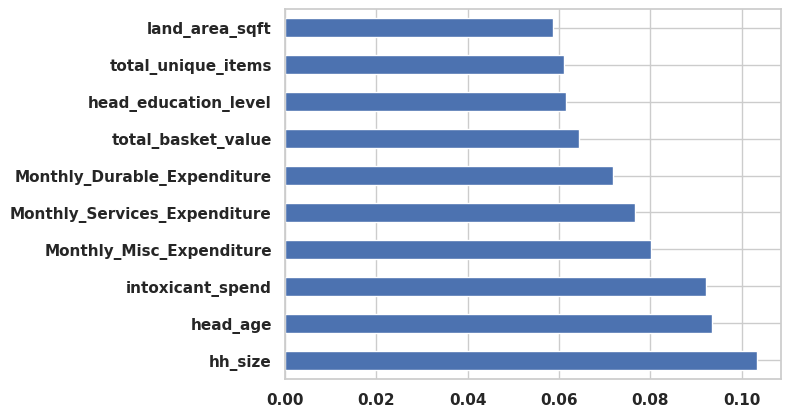

In [ ]:
#selection for our to 5 features
ranked_feat = pd.Series(model.feature_importances_,index=X.columns)
ranked_feat.nlargest(10).plot(kind = 'barh')
plt.show()

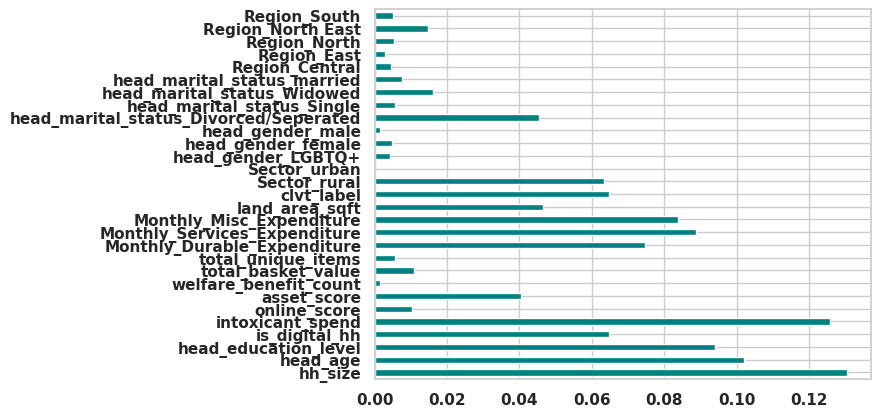

In [ ]:
#plotting with information gain
from sklearn.feature_selection import mutual_info_classif
importances = mutual_info_classif(X,y)
feat_importances = pd.Series(importances,df5.columns[0:len(df5.columns)-1])
feat_importances.plot(kind = 'barh',color ='teal')
plt.show()

In [ ]:
df5.head(2)

,hh_size,head_age,head_education_level,is_digital_hh,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,land_area_sqft,clvt_label,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married,Region_Central,Region_East,Region_North,Region_North East,Region_South,Region_West
0,4,56,12,1,19730,3,5,0,31570,20,26750,28000,28000,871.20,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,4,48,5,1,19730,2,5,0,63520,18,26750,28000,28000,435.60,2,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0


**Recursive Feature Elimination**

In [ ]:
#applying scaler on X
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols_to_scale = ['hh_size', 'head_age',
                  'intoxicant_spend', 'asset_score',
                 'online_score', 'total_basket_value', 'total_unique_items',
                 'Monthly_Durable_Expenditure', 'Monthly_Services_Expenditure',
                 'Monthly_Misc_Expenditure', 'land_area_sqft']
X[cols_to_scale] = scaler.fit_transform(X[cols_to_scale])
X.head()

,hh_size,head_age,head_education_level,is_digital_hh,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,land_area_sqft,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married,Region_Central,Region_East,Region_North,Region_North East,Region_South,Region_West
0,-0.13,0.56,12,1,1.82,1.97,1.49,0,-0.58,0.13,1.90,1.91,1.87,-0.35,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,-0.13,-0.01,5,1,1.82,0.53,1.49,0,1.02,-0.31,1.90,1.91,1.87,-0.35,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
4,-1.28,0.34,13,1,1.82,-0.92,1.49,0,1.15,-0.09,1.63,1.37,1.26,-0.35,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
7,-0.13,0.56,4,2,1.82,0.53,-0.16,0,-0.37,-0.53,1.90,1.91,1.87,-0.35,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
8,1.02,1.49,5,2,0.73,0.53,0.67,0,-0.09,-0.53,1.90,1.91,1.87,-0.35,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0


In [ ]:
#applying rfcev with logistic regression
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
model_r = LogisticRegression()
rfe = RFECV(model_r,step=3,cv=5)
fit = rfe.fit(X,y)

In [ ]:
fit.n_features_

np.int64(5)

In [ ]:
#selected features
fit.support_

array([ True,  True, False, False,  True, False, False, False, False,
       False, False, False,  True, False, False, False, False,  True,
       False, False, False, False, False, False, False, False, False,
       False, False])

In [ ]:
#feature ranking
fit.ranking_

array([1, 1, 8, 9, 1, 9, 8, 4, 5, 7, 3, 2, 1, 8, 3, 2, 9, 1, 2, 6, 3, 4,
       5, 5, 6, 7, 4, 6, 7])

In [ ]:
#checking for columns required
for i,col in zip(range(X.shape[1]),X.columns):
    print(f"{col} selected = {fit.support_[i]} rank = {fit.ranking_[i]}")

hh_size selected = True rank = 1
head_age selected = True rank = 1
head_education_level selected = False rank = 8
is_digital_hh selected = False rank = 9
intoxicant_spend selected = True rank = 1
online_score selected = False rank = 9
asset_score selected = False rank = 8
welfare_benefit_count selected = False rank = 4
total_basket_value selected = False rank = 5
total_unique_items selected = False rank = 7
Monthly_Durable_Expenditure selected = False rank = 3
Monthly_Services_Expenditure selected = False rank = 2
Monthly_Misc_Expenditure selected = True rank = 1
land_area_sqft selected = False rank = 8
Sector_rural selected = False rank = 3
Sector_urban selected = False rank = 2
head_gender_LGBTQ+ selected = False rank = 9
head_gender_female selected = True rank = 1
head_gender_male selected = False rank = 2
head_marital_status_Divorced/Seperated selected = False rank = 6
head_marital_status_Single selected = False rank = 3
head_marital_status_Widowed selected = False rank = 4
head_ma

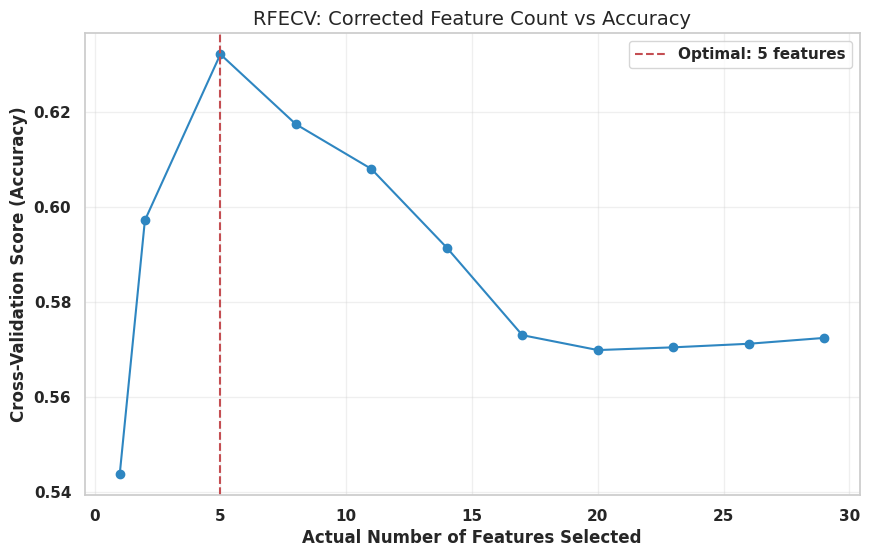

In [ ]:
#It starts from 1 (or your min_features_to_select) and increases by 'step'
step = 3
min_features = 1
n_features = X.shape[1]

# The x-axis should directly represent the number of features at each step of RFECV
x_axis = fit.cv_results_['n_features']

plt.figure(figsize=(10, 6))
plt.title('RFECV: Corrected Feature Count vs Accuracy', fontsize=14)
plt.xlabel('Actual Number of Features Selected', fontsize=12)
plt.ylabel('Cross-Validation Score (Accuracy)', fontsize=12)

# 2. Plot using the corrected x_axis
plt.plot(x_axis, fit.cv_results_['mean_test_score'], marker='o', color='#2E86C1')

# 3. Now the red line and blue line share the same "Feature Count" units
plt.axvline(x=fit.n_features_, color='r', linestyle='--', label=f'Optimal: {fit.n_features_} features')

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print("The best features are:")
print(X.columns[fit.support_])

The best features are:
Index(['hh_size', 'head_age', 'intoxicant_spend', 'Monthly_Misc_Expenditure',
       'head_gender_female'],
      dtype='object')


- After the observations with both the feature selection techniques recursive elimination method has given better results than chi square technique

In [ ]:
X.head(2)

,hh_size,head_age,head_education_level,is_digital_hh,intoxicant_spend,online_score,asset_score,welfare_benefit_count,total_basket_value,total_unique_items,Monthly_Durable_Expenditure,Monthly_Services_Expenditure,Monthly_Misc_Expenditure,land_area_sqft,Sector_rural,Sector_urban,head_gender_LGBTQ+,head_gender_female,head_gender_male,head_marital_status_Divorced/Seperated,head_marital_status_Single,head_marital_status_Widowed,head_marital_status_married,Region_Central,Region_East,Region_North,Region_North East,Region_South,Region_West
0,-0.13,0.56,12,1,1.82,1.97,1.49,0,-0.58,0.13,1.90,1.91,1.87,-0.35,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,-0.13,-0.01,5,1,1.82,0.53,1.49,0,1.02,-0.31,1.90,1.91,1.87,-0.35,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0


In [ ]:
#dropping all features and selecting our 7 features
X = X[['hh_size','head_age','intoxicant_spend','head_gender_female','Monthly_Misc_Expenditure']]

In [ ]:
X.head()

,hh_size,head_age,intoxicant_spend,head_gender_female,Monthly_Misc_Expenditure
0,-0.13,0.56,1.82,0,1.87
1,-0.13,-0.01,1.82,0,1.87
4,-1.28,0.34,1.82,0,1.26
7,-0.13,0.56,1.82,0,1.87
8,1.02,1.49,0.73,0,1.87


In [ ]:
#splitting our data into train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
#print shape
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(49917, 5) (12480, 5) (49917,) (12480,)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

#evaluate algorithms
num_folds = 8
scoring ='accuracy'

#check which algorithm is best
models = []
models.append(('LR',LogisticRegression()))
models.append(('KNN',KNeighborsClassifier()))
models.append(('CART',DecisionTreeClassifier()))
models.append(('NB',GaussianNB()))
models.append(('SVM',SVC()))

results = []
names = []

for name,model in models:
    kfold = KFold(n_splits=num_folds,random_state=None)
    cv_results = cross_val_score(model,
                                X_train,
                                y_train,
                                cv=kfold,
                                scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s:%f (%f)" %(name,cv_results.mean(),cv_results.std())
    print(msg)

LR:0.654346 (0.005622)
KNN:0.656350 (0.005767)
CART:0.586093 (0.008295)
NB:0.627582 (0.005603)
SVM:0.683815 (0.006722)


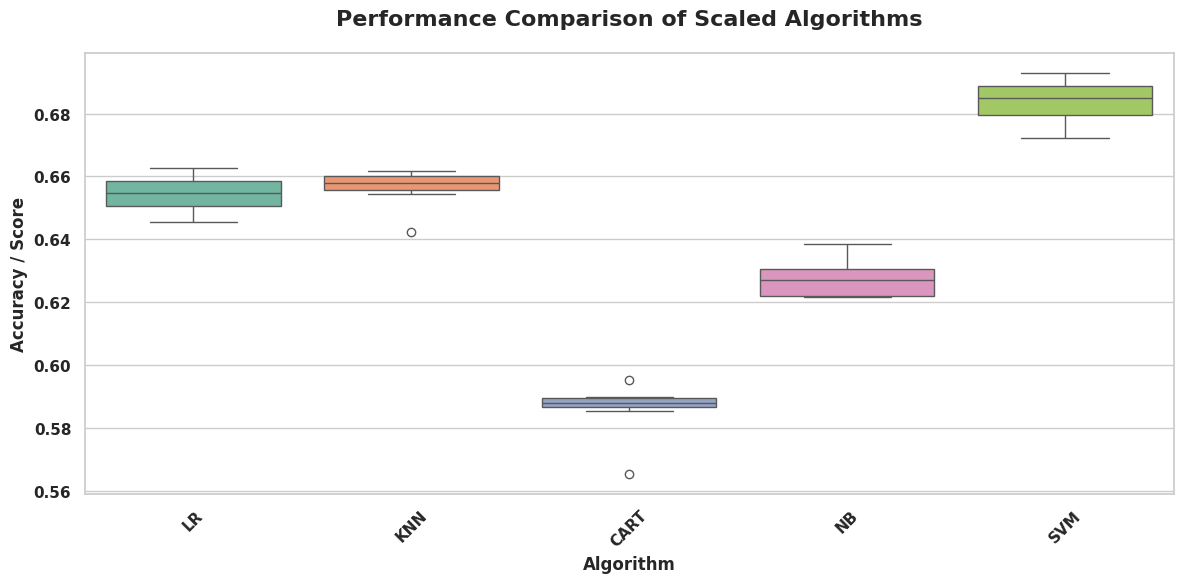

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set a professional style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))
# Using a specific palette (e.g., 'viridis' or 'Set2') helps differentiate the models
sns.boxplot(data=results, palette="Set2")

# Updating labels and title with bold formatting
plt.title('Performance Comparison of Scaled Algorithms', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Accuracy / Score', fontsize=12)
plt.xlabel('Algorithm', fontsize=12)

# Set the x-axis tick labels to your algorithm names
plt.xticks(range(len(names)), names, rotation=45)

plt.tight_layout()
plt.show()

##Application Of Ensemble Methods

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
import xgboost as xgb
ensembles = []

ensembles.append(('AB',AdaBoostClassifier()))
ensembles.append(('HGB',HistGradientBoostingClassifier()))
ensembles.append(('RF',RandomForestClassifier()))
ensembles.append(('BG',BaggingClassifier()))
ensembles.append(('ET', ExtraTreesClassifier()))
ensembles.append(('XGB',xgb.XGBClassifier()))


results = []
names = []

for name,model in ensembles:
    kfold = KFold(n_splits=num_folds,random_state=None)
    cv_results = cross_val_score(model,
                                X_train,
                                y_train,
                                cv=kfold,
                                scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s:%f (%f)" %(name,cv_results.mean(),cv_results.std())
    print(msg)

AB:0.612877 (0.010610)
HGB:0.692129 (0.006943)
RF:0.656871 (0.007104)
BG:0.643649 (0.004833)
ET:0.644049 (0.006905)
XGB:0.690066 (0.005319)


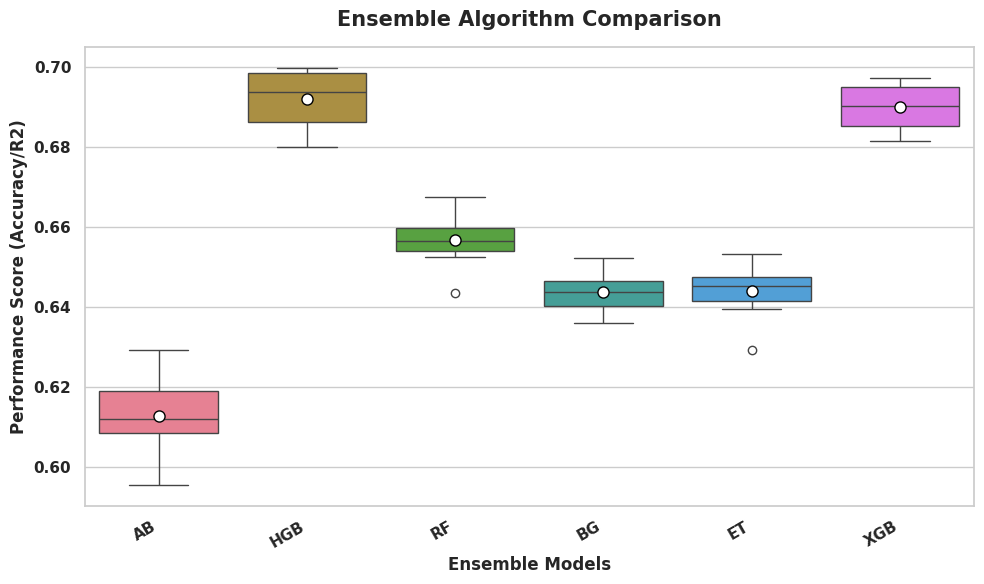

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Set the visual style
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(10, 6))

# 2. Create the boxplot with enhanced styling
# 'showmeans=True' is great for academic projects to show average performance
sns.boxplot(data=results, palette="husl", showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"})

# 3. Add titles and labels
plt.title('Ensemble Algorithm Comparison', fontsize=15, fontweight='bold', pad=15)
plt.ylabel('Performance Score (Accuracy/R2)', fontsize=12)
plt.xlabel('Ensemble Models', fontsize=12)

# 4. Set x-axis labels with rotation to prevent overlapping names
plt.xticks(range(len(names)), names, rotation=30, ha='right')

# 5. Clean up the layout
plt.tight_layout()
plt.show()

- After analysis with all the algorithms the models chosen are logistic regression,svm,naive bayes,Random Forest and XGB classifier.

## Logistic regression

In [ ]:
from sklearn.model_selection import GridSearchCV, KFold

# 1. Define the parameters for Logistic Regression
# C is the inverse of regularization strength
# We usually search across powers of 10
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],           # Standard penalty
    'solver': ['lbfgs'],         # Default solver that works well with L2
    'max_iter': [1000]           # Increased to ensure convergence on your 62k rows
}

# 2. Initialize the model
model = LogisticRegression()

# 3. Setup the Cross-Validation
kfold = KFold(n_splits=num_folds, random_state=None)

# 4. Setup the Grid Search
# Using n_jobs=-1 will make this run much faster by using all CPU cores
grid = GridSearchCV(estimator=model,
                   param_grid=param_grid,
                   scoring=scoring,
                   cv=kfold,
                   n_jobs=-1)

# 5. Fit the model
# Using y_res_train (assuming you used SMOTE or balancing)
grid_result = grid.fit(X_train, y_train)

# 6. Print the results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best: 0.654346 using {'C': 1, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'lbfgs'}


In [ ]:
#fitting the model with the parameters
model_lg = LogisticRegression(C=1,max_iter=1000,penalty='l2',solver='lbfgs')
model_lg.fit(X_train,y_train)

LogisticRegression(C=1, max_iter=1000)

In [ ]:
#predicting using the model
y_pred = model_lg.predict(X_test)
y_pred

array([1, 1, 1, ..., 1, 2, 3])

In [ ]:
#checking with the confusion matrix
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test,y_pred))


[[ 610  635    0    0]
 [ 284 5637  428   80]
 [  13 1292  665  640]
 [   1  459  406 1330]]


In [ ]:
#print the classification report
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.67      0.49      0.57      1245
           1       0.70      0.88      0.78      6429
           2       0.44      0.25      0.32      2610
           3       0.65      0.61      0.63      2196

    accuracy                           0.66     12480
   macro avg       0.62      0.56      0.57     12480
weighted avg       0.64      0.66      0.64     12480



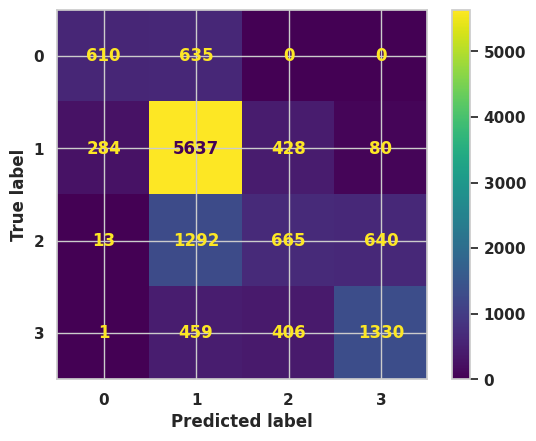

In [ ]:
#plotting the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [ ]:
#print training and testing accuracy
print("Train Accuracy:",model_lg.score(X_train,y_train))
print("Test Accuracy:",model_lg.score(X_test,y_test))

Train Accuracy: 0.6545064807580584
Test Accuracy: 0.6604166666666667


##SVM

In [ ]:
# 2. Optimized Parameter Grid
# Note: 'poly' and 'sigmoid' kernels are extremely slow on large datasets.
# It is often better to test 'linear' and 'rbf' first.
c_val = [0.1, 1, 10]
kernel_val = ['linear', 'rbf']
gamma = [0.1, 0.01]

param_grid = dict(kernel=kernel_val, C=c_val, gamma=gamma)

# 3. Model with Cache Size
# cache_size=1000 uses 1GB of RAM to speed up the kernel calculation
model = SVC(cache_size=1000)

kfold = KFold(n_splits=num_folds, random_state=None)

# 4. Use n_jobs=-1 to use all CPU cores
grid = GridSearchCV(estimator=model,
                    param_grid=param_grid,
                    scoring=scoring,
                    cv=kfold,
                    n_jobs=-1)

# 5. Fitting (Recommendation: Use a sample first)
# Even with optimization, 62k rows is very heavy for SVC.
# Try grid.fit(X_train_scaled[:10000], y_train[:10000]) first to check time.
grid_result = grid.fit(X_train[:10000], y_train[:10000])

print("Best : %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best : 0.674700 using {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}


In [ ]:
#fitting the model with the svm parameters
model_svc = SVC(C=10,cache_size=1000,gamma=0.1,kernel='rbf')
model_svc.fit(X_train,y_train)

SVC(C=10, cache_size=1000, gamma=0.1)

In [ ]:
#predicting with our given model
y_pred = model_svc.predict(X_test)
y_pred

array([1, 1, 1, ..., 1, 2, 3])

In [ ]:
#print the confusion matrix
print(confusion_matrix(y_test,y_pred))

[[ 625  620    0    0]
 [ 267 5874  259   29]
 [  10 1376  942  282]
 [   1  500  512 1183]]


In [ ]:
#printing the classification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.69      0.50      0.58      1245
           1       0.70      0.91      0.79      6429
           2       0.55      0.36      0.44      2610
           3       0.79      0.54      0.64      2196

    accuracy                           0.69     12480
   macro avg       0.68      0.58      0.61     12480
weighted avg       0.68      0.69      0.67     12480



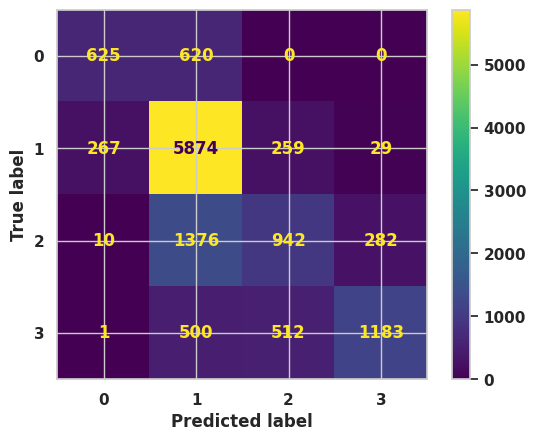

In [ ]:
#plotting the confusion reportfrom sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [ ]:
#print training and testing accuracy
print("Train Accuracy:",model_svc.score(X_train,y_train))
print("Test Accuracy:",model_svc.score(X_test,y_test))

Train Accuracy: 0.6847767293707554
Test Accuracy: 0.691025641025641


##Naive Bayes


In [ ]:
param_grid = {
    'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
}

# 2. Initialize the model
model = GaussianNB()

# 3. Setup the Cross-Validation
kfold = KFold(n_splits=num_folds, random_state=None)

# 4. Setup the Grid Search
grid = GridSearchCV(estimator=model,
                   param_grid=param_grid,
                   scoring=scoring,
                   cv=kfold,
                   n_jobs=-1)

# 5. Fit the model
# You can use scaled or unscaled X, but GaussianNB handles unscaled data quite well
grid_result = grid.fit(X_train, y_train)

# 6. Print the results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best: 0.627582 using {'var_smoothing': 1e-09}


In [ ]:
#fitting the model with given parameters
model_gb = GaussianNB(var_smoothing=1e-09)
model_gb.fit(X_train,y_train)

GaussianNB()

In [ ]:
#predicting using our model
y_pred = model_gb.predict(X_test)
y_pred

array([2, 1, 1, ..., 3, 1, 3])

In [ ]:
#printing the confusion matrix
print(confusion_matrix(y_test,y_pred))

[[ 387  856    0    2]
 [ 155 5722  386  166]
 [   7 1480  602  521]
 [   1  552  496 1147]]


In [ ]:
#printing the classification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.70      0.31      0.43      1245
           1       0.66      0.89      0.76      6429
           2       0.41      0.23      0.29      2610
           3       0.62      0.52      0.57      2196

    accuracy                           0.63     12480
   macro avg       0.60      0.49      0.51     12480
weighted avg       0.61      0.63      0.60     12480



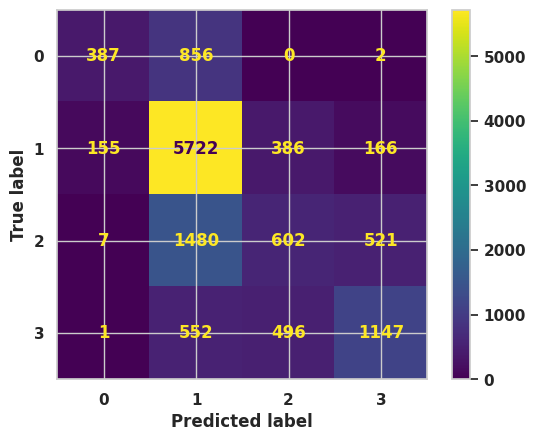

In [ ]:
#plotting the confusion matrix
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model_gb.classes_)
disp.plot()
plt.show()

In [ ]:
#print train and test accuracy
print("Train Accuracy:",model_gb.score(X_train,y_train))
print("Test Accuracy:",model_gb.score(X_test,y_test))
#

Train Accuracy: 0.6275216859987579
Test Accuracy: 0.6296474358974359


##Random Forest

In [ ]:
max_depth = [2, 3, 4, 5]
max_features = [2, 4, 6]
n_estimators = [20, 40, 60, 100]

param_grid = dict(max_depth=max_depth,
                  max_features=max_features,
                  n_estimators=n_estimators)

# 2. Initialize the model with n_jobs=-1
# This tells each Random Forest to use all CPU cores for internal tree building
model = RandomForestClassifier(n_jobs=-1, random_state=42)

# 3. Setup the Cross-Validation
kfold = KFold(n_splits=num_folds, random_state=None)

# 4. Setup the Grid Search with n_jobs=-1
# This tells the GridSearch to run different parameter combinations in parallel
grid = GridSearchCV(estimator=model,
                   param_grid=param_grid,
                   scoring=scoring,
                   cv=kfold,
                   n_jobs=-1)

# 5. Fit the model
# Using y_res_train suggests you are working with balanced data
grid_result = grid.fit(X_train[:10000], y_train[:10000])

# 6. Print the results
print("Best : %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best : 0.647100 using {'max_depth': 5, 'max_features': 6, 'n_estimators': 60}


In [ ]:
#fitting with our suggested parameter
model_rf = RandomForestClassifier(max_depth=5,max_features=6,n_estimators=60,n_jobs=-1,random_state=42)
model_rf.fit(X_train,y_train)

RandomForestClassifier(max_depth=5, max_features=6, n_estimators=60, n_jobs=-1,
                       random_state=42)

In [ ]:
#predicting using our model
y_pred = model_rf.predict(X_test)
y_pred

array([1, 1, 1, ..., 1, 1, 3])

In [ ]:
#printing the confusion matrix
print(confusion_matrix(y_test,y_pred))

[[ 247  998    0    0]
 [  93 6028  232   76]
 [   3 1536  705  366]
 [   1  591  374 1230]]


In [ ]:
#printing the clasification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.72      0.20      0.31      1245
           1       0.66      0.94      0.77      6429
           2       0.54      0.27      0.36      2610
           3       0.74      0.56      0.64      2196

    accuracy                           0.66     12480
   macro avg       0.66      0.49      0.52     12480
weighted avg       0.65      0.66      0.62     12480



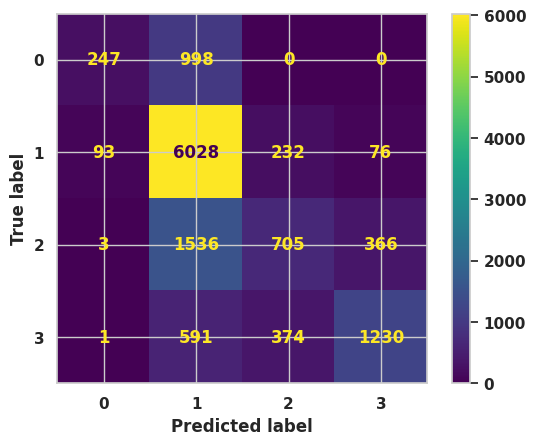

In [ ]:
#plot the confusion matrix
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

##XG Boost

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, KFold

# 1. Define the Parameter Distribution
# RandomizedSearch will pick random combinations from these lists
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],           # Percentage of samples used per tree
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],          # Controls overfitting (higher = more conservative)
    'gamma': [0, 0.1, 0.2]                  # Minimum loss reduction for a split
}

# 2. Initialize the XGBoost model
model_xgb = XGBClassifier(
    n_jobs=-1,
    random_state=42,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

# 3. Setup the Cross-Validation
kfold = KFold(n_splits=num_folds, random_state=None)

# 4. Setup the Randomized Search
# n_iter=50 means it will try 50 random combinations from the grid above
random_search_xgb = RandomizedSearchCV(
    estimator=model_xgb,
    param_distributions=param_dist,
    n_iter=30,             # Number of parameter settings sampled
    scoring=scoring,
    cv=kfold,
    n_jobs=-1,
    random_state=42,       # Ensuring reproducibility of the random choices
    verbose=1              # Shows progress during the search
)

# 5. Fit the model
# Using the 10,000 sample subset as per your previous workflow
random_result_xgb = random_search_xgb.fit(X_train[:30000], y_train[:30000])

# 6. Print the results
print("Best XGBoost (Random Search): %f using %s" % (random_result_xgb.best_score_, random_result_xgb.best_params_))

Fitting 8 folds for each of 30 candidates, totalling 240 fits
Best XGBoost (Random Search): 0.691500 using {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 1.0}


In [ ]:
#fitting with our suggested parameters
model_xgb = XGBClassifier(colsample_bytree=0.8,learning_rate=0.05,max_depth=6,n_estimators=200,n_jobs=-1,random_state=42)
model_xgb.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
#predicting using the XGboost classifier
y_pred = model_xgb.predict(X_test)
y_pred

array([1, 1, 1, ..., 1, 2, 3])

In [ ]:
#printing the confusion matrix
print(confusion_matrix(y_test,y_pred))

[[ 666  579    0    0]
 [ 323 5683  378   45]
 [  11 1188 1068  343]
 [   2  447  455 1292]]


In [ ]:
#printing the classification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.66      0.53      0.59      1245
           1       0.72      0.88      0.79      6429
           2       0.56      0.41      0.47      2610
           3       0.77      0.59      0.67      2196

    accuracy                           0.70     12480
   macro avg       0.68      0.60      0.63     12480
weighted avg       0.69      0.70      0.68     12480



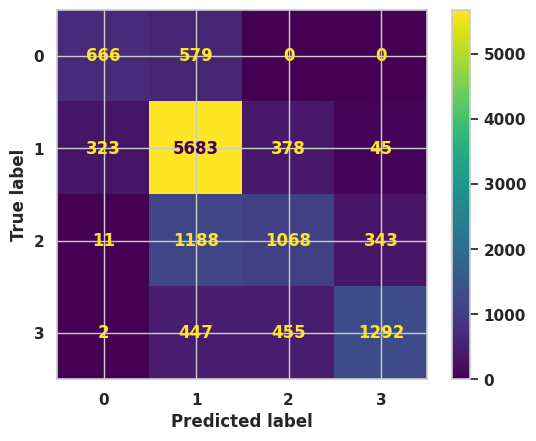

In [ ]:
#plotting the confusion matrix
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [ ]:
#print the train and test accuracy
print("Train Accuracy:",model_xgb.score(X_train,y_train))
print("Test Accuracy:",model_xgb.score(X_test,y_test))

Train Accuracy: 0.7128232866558487
Test Accuracy: 0.6978365384615385


In [ ]:
#variables
X.head()

,hh_size,head_age,intoxicant_spend,head_gender_female,Monthly_Misc_Expenditure
0,-0.13,0.56,1.82,0,1.87
1,-0.13,-0.01,1.82,0,1.87
4,-1.28,0.34,1.82,0,1.26
7,-0.13,0.56,1.82,0,1.87
8,1.02,1.49,0.73,0,1.87


- After Observing all the ml algorithms Xg boost has performed well with 70% accuracy.

#Smote Technique to resample the data

In [ ]:
#smote on y variable
from imblearn.over_sampling import SMOTE
# 3. Initialize SMOTE
# 'sampling_strategy' can be 'auto' to balance all classes equally
sm = SMOTE(random_state=42)

# 4. Fit SMOTE only on the Training Data
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print(f"Original training shape: {y_train.value_counts()}")
print(f"Resampled training shape: {y_train_res.value_counts()}")

Original training shape: clvt_label
1    25918
2    10875
3     8108
0     5016
Name: count, dtype: int64
Resampled training shape: clvt_label
0    25918
1    25918
2    25918
3    25918
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, KFold

# 1. Define the Parameter Distribution
# RandomizedSearch will pick random combinations from these lists
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],           # Percentage of samples used per tree
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],          # Controls overfitting (higher = more conservative)
    'gamma': [0, 0.1, 0.2]                  # Minimum loss reduction for a split
}

# 2. Initialize the XGBoost model
model_xgb = XGBClassifier(
    n_jobs=-1,
    random_state=42,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

# 3. Setup the Cross-Validation
kfold = KFold(n_splits=num_folds, random_state=None)

# 4. Setup the Randomized Search
# n_iter=50 means it will try 50 random combinations from the grid above
random_search_xgb = RandomizedSearchCV(
    estimator=model_xgb,
    param_distributions=param_dist,
    n_iter=30,             # Number of parameter settings sampled
    scoring=scoring,
    cv=kfold,
    n_jobs=-1,
    random_state=42,       # Ensuring reproducibility of the random choices
    verbose=1              # Shows progress during the search
)

# 5. Fit the model
# Using the 10,000 sample subset as per your previous workflow
random_result_xgb = random_search_xgb.fit(X_train_res[:30000], y_train_res[:30000])

# 6. Print the results
print("Best XGBoost (Random Search): %f using %s" % (random_result_xgb.best_score_, random_result_xgb.best_params_))

Fitting 8 folds for each of 30 candidates, totalling 240 fits
Best XGBoost (Random Search): 0.691500 using {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 1.0}


In [ ]:
#fitting with our suggested parameters
model_xgb_res = XGBClassifier(colsample_bytree=1.0,learning_rate=0.05,max_depth=6,n_estimators=200,min_child_weight=5,n_jobs=-1,random_state=42)
model_xgb_res.fit(X_train_res,y_train_res)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
#predicting using the model
y_pred = model_xgb_res.predict(X_test)
y_pred

array([2, 1, 1, ..., 1, 2, 3])

In [ ]:
#printing the confusion matrix
print(confusion_matrix(y_test,y_pred))

[[1073  172    0    0]
 [ 992 4325 1007  105]
 [  58  733 1266  553]
 [   5  238  510 1443]]


In [ ]:
#printing the classification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.50      0.86      0.64      1245
           1       0.79      0.67      0.73      6429
           2       0.45      0.49      0.47      2610
           3       0.69      0.66      0.67      2196

    accuracy                           0.65     12480
   macro avg       0.61      0.67      0.63     12480
weighted avg       0.67      0.65      0.65     12480



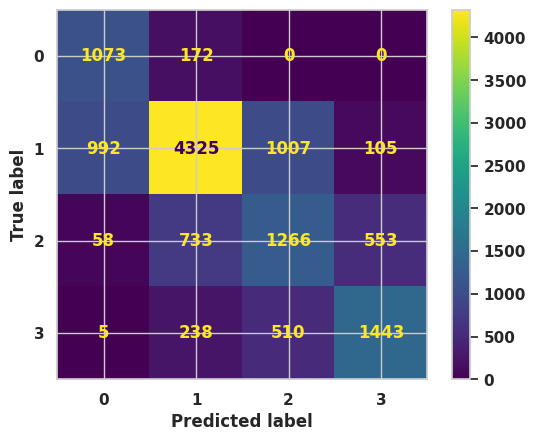

In [ ]:
#plotting the confusion matrix
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

- with applications all models the best model to categorise our houselds for cltv is Xg boost without the smote technique and we have chosen the model